In [1]:
import os, time, warnings, itertools
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.graphics.tsaplots import plot_acf

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_columns", 50)

# ---------------- global configuration ----------------
RANDOM_STATE   = 42
TARGET         = "Demand"
ALPHA          = 0.05          # significance level for all hypothesis tests
N_TRIALS       = 50            # one Optuna search pass per tunable model (resumable, see OPTUNA_DB)
N_TRIALS_SLOW  = 30            # RandomForest is slower; LinearRegression is evaluated once
N_TRIALS_WINNER_EXTRA = 150    # additional refinement trials for the provisional winner
CV_FOLDS       = 4             # time-series CV folds inside Optuna
CV_VAL_DAYS    = 60            # v4: every CV fold validates on this many days, so no fold is starved of training history
TUNE_SAMPLE    = None          # use all training rows for tuning; the final hold-out remains untouched
TEST_FRACTION  = 0.20          # last 20 % of dates are the hold-out test set
np.random.seed(RANDOM_STATE)

# ---------------- v5: realism switch ----------------
# Price (and everything built from it) moves WITH demand in this dataset (corr +0.80), so it leaks "current demand" into the model and inflates R2 to ~0.999.
# True  -> price-level features are removed from the candidate set, giving a realistic R2.  False -> previous behaviour.
EXCLUDE_PRICE_PROXY = True
# Choose how strict to be (from the 8.4b ablation: base 0.43 | raw price 0.79 | competitor-relative 0.55 | own-price history 0.98):
#   "own_history" -> drop only own-price-history features (most proxy-like, gives ~0.98)  => expected R2 ~0.8
#   "all_price"   -> drop every price feature                                              => expected R2 ~0.45
PRICE_PROXY_MODE = "own_history"
_OWN_HISTORY = ["Price_ExpMean", "Price_Roll7", "Price_Roll28", "Price_Idx_Exp", "Price_Idx_7", "Price_Idx_28", "Price_Change_1d", "Comp_Change_1d"]
_ALL_PRICE   = ["Price", "Competitor_Pricing", "Price_Ratio", "Price_Gap", "Effective_Price", "Eff_Ratio"] + _OWN_HISTORY
PRICE_PROXY = _OWN_HISTORY if PRICE_PROXY_MODE == "own_history" else _ALL_PRICE
OPTUNA_SUFFIX = "_noprice"   # new Optuna studies so old price-based trials are not reused

# ---------------- overfit / underfit guard-rails ----------------
GAP_TOL          = 0.03   # tuning: tolerated gap (val_MAE - train_MAE) as a SHARE OF THE NAIVE-BASELINE MAE (v4: scale-aware) before the objective is penalised
GAP_PENALTY      = 10.0   # tuning: objective = val_MAE * (1 + GAP_PENALTY * max(0, gap_naive - GAP_TOL))
OVERFIT_GAP_FLAG = 0.05   # audit: (test MAE - train MAE) / naive MAE above this => OVERFIT (v4: scale-aware)
FOLD_SPREAD_TOL  = 0.25   # audit (v4): std of the CV fold MAEs / mean CV MAE above this => UNSTABLE (error depends too much on the period)
SELECTION_STD_WEIGHT = 0.5   # v4 model selection: risk-adjusted CV = mean fold MAE + weight * std of fold MAEs
FEATURE_PRUNE     = True    # v4: drop features that do not help (chronological CV on the TRAINING period only; the hold-out is never used)
FEATURE_PRUNE_TOL = 0.01    # v4: keep the SMALLEST feature set whose CV MAE is within 1 % of the best CV MAE seen while pruning
FEATURE_PRUNE_FORCE_N = None  # v4: optional manual override, e.g. 12 keeps exactly the 12 most useful features (see the step table in 9.0); None = automatic
MIN_SKILL        = 0.02   # audit: model must beat the best naive baseline by at least 2 % (train AND test)

# ---------------- v3: export names ----------------
PIPELINE_FILE   = "pricing_pipeline.joblib"                 # fitted end-to-end pipeline (section 12.4)
PIPELINE_MODULE = "pricing_pipeline_components.py"          # classes the pipeline needs; written by section 12.4 and must travel with the .joblib

# ---------------- runtime options ----------------
# Quick smoke test of the whole notebook: set the environment variable PRICING_FAST=1 before starting Jupyter.
FAST_DEBUG = os.environ.get("PRICING_FAST", "0") == "1"
OPTUNA_DB  = "sqlite:///optuna_pricing_v6_own.db"      # single-pass studies; separate from the old multi-stage runs
if FAST_DEBUG:
    N_TRIALS, N_TRIALS_SLOW, N_TRIALS_WINNER_EXTRA, TUNE_SAMPLE = 3, 2, 2, 12000
    OPTUNA_DB = "sqlite:///optuna_pricing_v6_own_debug.db"
    print("FAST_DEBUG on: tiny trial counts, results are NOT meaningful")

In [2]:
# Dataset path: Kaggle first, then common local locations. Set DATA_PATH_OVERRIDE if needed.
import shutil, hashlib
from pathlib import Path
DATA_PATH_OVERRIDE = os.environ.get("SALES_DATA_PATH", "")
DATA_CANDIDATES = [
    DATA_PATH_OVERRIDE,
    "/kaggle/input/datasets/paracha789/sales-data/sales_data.csv",
    os.path.join(os.getcwd(), "sales_data.csv"),
    os.path.join(os.getcwd(), "data", "sales_data.csv"),
]
ORIGINAL_PATH = next((p for p in DATA_CANDIDATES if p and os.path.isfile(p)), None)
if ORIGINAL_PATH is None:
    raise FileNotFoundError("sales_data.csv not found. Put it beside the notebook, in ./data/, or set SALES_DATA_PATH to its full path.")

def file_sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
WORKING_COPY_PATH = os.path.join(WORK_DIR, "sales_data_working_copy.csv")
ORIGINAL_SHA256 = file_sha256(ORIGINAL_PATH)
shutil.copy2(ORIGINAL_PATH, WORKING_COPY_PATH)
assert file_sha256(WORKING_COPY_PATH) == ORIGINAL_SHA256, "Copy differs from the original - copy failed"
print(f"Original : {ORIGINAL_PATH}\nCopy     : {WORKING_COPY_PATH}  (identical, sha256 {ORIGINAL_SHA256[:12]}...)")
DATA_PATH = WORKING_COPY_PATH

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy(deep=True)
df.columns = df.columns.str.strip().str.replace(r"\s+", "_", regex=True)
print(f"Loaded {DATA_PATH} (working copy) -> {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Copy is independent of original:", df is not df_raw)
display(df.head())
df.info()


Original : /kaggle/input/datasets/paracha789/sales-data/sales_data.csv
Copy     : /kaggle/working/sales_data_working_copy.csv  (identical, sha256 96f107b42042...)
Loaded /kaggle/working/sales_data_working_copy.csv (working copy) -> 76,000 rows x 16 columns
Copy is independent of original: True


,Date,Store_ID,Product_ID,Category,Region,Inventory_Level,Units_Sold,Units_Ordered,Price,Discount,Weather_Condition,Promotion,Competitor_Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.7200,5,Snowy,0,85.7300,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.1600,15,Snowy,1,92.0200,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.9400,10,Snowy,1,60.0800,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.6300,10,Snowy,0,85.1900,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.4100,0,Snowy,0,51.6300,Winter,0,59


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store_ID            76000 non-null  object 
 2   Product_ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory_Level     76000 non-null  int64  
 6   Units_Sold          76000 non-null  int64  
 7   Units_Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather_Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor_Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

## 2️⃣ Data quality: missing values, duplicates, data types
### 2.1 Missing values – type and percentage for every column
We look for **three kinds** of missingness:
1. **True NaN** values
2. **Disguised missing** values – placeholders such as `""`, `?`, `NA`, `null`, `-`
3. **Impossible values** – e.g. negative units/prices, price = 0, discount > 100 % (these are treated as missing)

,dtype,true_NaN,true_NaN_pct,disguised,impossible,total_problem,total_problem_pct
column,,,,,,,
Date,object,0,0.0000,0,0,0,0.0000
Store_ID,object,0,0.0000,0,0,0,0.0000
Product_ID,object,0,0.0000,0,0,0,0.0000
Category,object,0,0.0000,0,0,0,0.0000
Region,object,0,0.0000,0,0,0,0.0000
Inventory_Level,int64,0,0.0000,0,0,0,0.0000
Units_Sold,int64,0,0.0000,0,0,0,0.0000
Units_Ordered,int64,0,0.0000,0,0,0,0.0000
Price,float64,0,0.0000,0,0,0,0.0000


Total missing-type problems in the dataset: 0


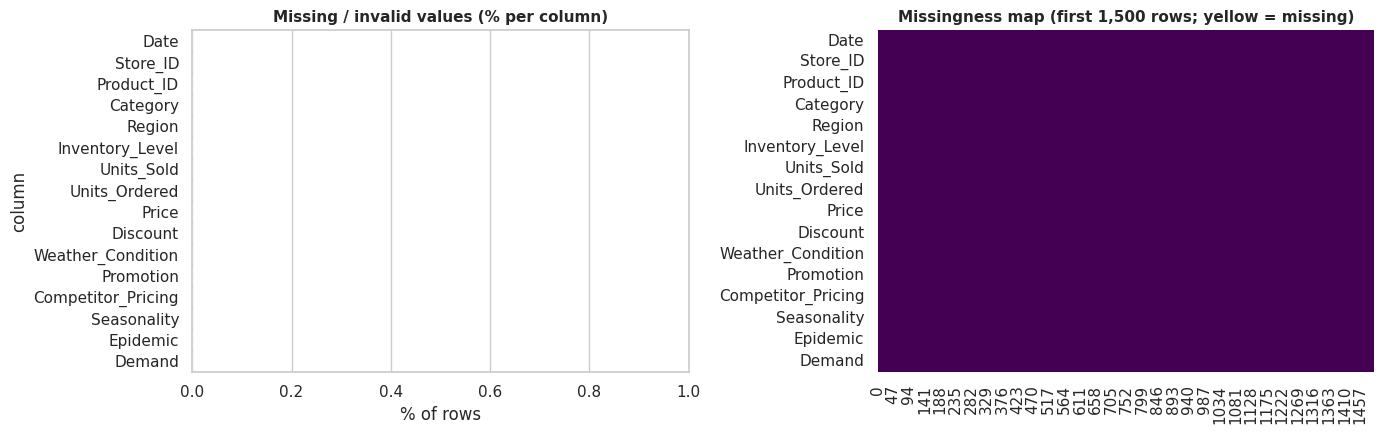

In [3]:
PLACEHOLDERS = {"", "?", "na", "n/a", "nan", "null", "none", "-", "--", "unknown"}
POSITIVE_COLS = ["Price", "Competitor_Pricing"]                       # must be > 0
NONNEG_COLS   = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Discount", "Demand"]  # must be >= 0

def missing_report(d):
    rows = []
    for c in d.columns:
        s = d[c]
        n_nan = int(s.isna().sum())
        is_text = not (pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s))
        n_ph = int(s.dropna().astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()) if is_text else 0
        n_bad = 0
        if pd.api.types.is_numeric_dtype(s):
            if c in POSITIVE_COLS: n_bad = int((s <= 0).sum())
            if c in NONNEG_COLS:   n_bad = int((s < 0).sum())
        tot = n_nan + n_ph + n_bad
        rows.append(dict(column=c, dtype=str(s.dtype), true_NaN=n_nan, true_NaN_pct=100*n_nan/len(d),
                         disguised=n_ph, impossible=n_bad, total_problem=tot, total_problem_pct=100*tot/len(d)))
    return pd.DataFrame(rows).set_index("column")

miss = missing_report(df)
display(miss)
print(f"Total missing-type problems in the dataset: {int(miss.total_problem.sum())}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=miss.total_problem_pct, y=miss.index, ax=ax[0], color="#4C72B0")
ax[0].set_xlim(0, max(1, miss.total_problem_pct.max()*1.2)); ax[0].set_title("Missing / invalid values (% per column)")
ax[0].set_xlabel("% of rows")
sns.heatmap(df.isna().iloc[:1500].T, cbar=False, ax=ax[1], cmap="viridis")
ax[1].set_title("Missingness map (first 1,500 rows; yellow = missing)")
plt.tight_layout(); plt.show()

In [4]:
# Turn disguised / impossible values into real NaN so one imputation step can deal with everything
def standardize_missing(d):
    d = d.copy()
    for c in d.columns:
        s = d[c]
        if not (pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s)):
            d.loc[s.astype(str).str.strip().str.lower().isin(PLACEHOLDERS), c] = np.nan
    for c in POSITIVE_COLS:
        if pd.api.types.is_numeric_dtype(d[c]): d.loc[d[c] <= 0, c] = np.nan
    for c in NONNEG_COLS:
        if pd.api.types.is_numeric_dtype(d[c]): d.loc[d[c] < 0, c] = np.nan
    return d
df = standardize_missing(df)
print("NaN per column after standardisation:"); print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none - dataset has no missing values")

NaN per column after standardisation:
none - dataset has no missing values


### 2.2 Duplicates

In [5]:
KEY = ["Date", "Store_ID", "Product_ID"]  # expected one row per store-product-day
n_full = int(df.duplicated().sum())
n_key = int(df.duplicated(subset=KEY).sum())
print(f"Fully duplicated rows: {n_full:,}")
print(f"Duplicate business keys: {n_key:,}")

before = len(df)
df = df.drop_duplicates().copy()
# If conflicting records share a business key, retain the most complete row rather than blindly
# assuming the last physical CSV row is the latest. Report conflicts for auditability.
key_dupes = df.duplicated(subset=KEY, keep=False)
if key_dupes.any():
    conflicts = df.loc[key_dupes].copy()
    conflicts["_non_missing"] = conflicts.notna().sum(axis=1)
    conflicts = conflicts.sort_values(KEY + ["_non_missing"], kind="mergesort")
    df = conflicts.drop_duplicates(subset=KEY, keep="last").drop(columns="_non_missing").pipe(
        lambda chosen: pd.concat([df.loc[~key_dupes], chosen], axis=0)
    )
df = df.reset_index(drop=True)
print(f"Rows before: {before:,} | after: {len(df):,} | removed: {before-len(df):,}")
print("Note: conflicting duplicate keys are resolved by retaining the row with the most non-missing fields; inspect source records if they represent different transactions.")


Fully duplicated rows: 0
Duplicate business keys: 0
Rows before: 76,000 | after: 76,000 | removed: 0
Note: conflicting duplicate keys are resolved by retaining the row with the most non-missing fields; inspect source records if they represent different transactions.


In [6]:
CONT = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Price", "Competitor_Pricing", "Demand"]
COUNTS = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Demand"]
BINARY = ["Promotion", "Epidemic"]
CAT_NOM = ["Store_ID", "Product_ID", "Category", "Region", "Weather_Condition", "Seasonality"]

dtypes_before = df.dtypes.astype(str).rename("before")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
for c in CONT + ["Discount"] + BINARY:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Invalid domain values become NaN and are handled by the training-only imputation step.
for c in ["Price", "Competitor_Pricing"]:
    df.loc[df[c] <= 0, c] = np.nan
for c in ["Inventory_Level", "Units_Sold", "Units_Ordered", "Discount", "Demand"]:
    df.loc[df[c] < 0, c] = np.nan
df.loc[~df["Discount"].between(0, 100), "Discount"] = np.nan
for c in BINARY:
    df.loc[~df[c].isin([0, 1]), c] = np.nan

# A missing date cannot be placed safely in a chronological split, so exclude and report those rows.
missing_dates = int(df["Date"].isna().sum())
if missing_dates:
    print(f"Dropping {missing_dates:,} rows with invalid/missing Date (cannot assign to a time split).")
    df = df.loc[df["Date"].notna()].copy()
for c in CAT_NOM:
    df[c] = df[c].astype("category")

print("NaN after type/domain validation:", int(df.isna().sum().sum()))
cmp = pd.concat([dtypes_before, df.dtypes.astype(str).rename("after")], axis=1)
display(cmp)
print("Date range:", df.Date.min().date(), "->", df.Date.max().date(), "| days:", df.Date.nunique(),
      "| rows/day unique counts:", df.groupby('Date', observed=True).size().nunique())


NaN after type/domain validation: 0


,before,after
Date,object,datetime64[ns]
Store_ID,object,category
Product_ID,object,category
Category,object,category
Region,object,category
Inventory_Level,float64,float64
Units_Sold,float64,float64
Units_Ordered,float64,float64
Price,float64,float64
Discount,float64,float64


Date range: 2022-01-01 -> 2024-01-30 | days: 760 | rows/day unique counts: 1


In [7]:
# Define the chronological hold-out ONCE, before any data-dependent preprocessing.
# Everything fitted from data (outlier fences, target transform, models) may only use rows with Date < CUT_DATE.
_dates   = np.sort(df["Date"].dropna().unique())
CUT_DATE = pd.Timestamp(_dates[int(len(_dates) * (1 - TEST_FRACTION))])
print(f"Hold-out starts on {CUT_DATE.date()}  ({TEST_FRACTION:.0%} of {len(_dates)} dates are held out)")

Hold-out starts on 2023-09-01  (20% of 760 dates are held out)


## 3️⃣ Imputation – choose the *best* method for this data
Mean/median/mode are not always best. Here we **benchmark** several strategies with a proper protocol:

1. Take the known (complete) values and **hide 10 % at random** (MCAR) – we know the truth.
2. Impute with each method and measure the error on the hidden cells (Normalised RMSE = RMSE / std).
3. The method with the lowest error is used for the real data.

Methods: global mean · global median · **group median** (by Category) · **KNN** (k=5, uses other columns) · **Iterative / MICE‑style** (BayesianRidge regressions between columns).

mean          mean NRMSE = 0.9825 (0.0s)
median        mean NRMSE = 1.0125 (0.0s)
group_median  mean NRMSE = 0.8707 (0.0s)
knn           mean NRMSE = 0.6944 (0.6s)
iterative     mean NRMSE = 0.5659 (1.8s)


,Inventory_Level,Units_Sold,Units_Ordered,Price,Competitor_Pricing,Demand,MEAN
iterative,0.9035,0.5750,0.8470,0.2732,0.2933,0.5033,0.5659
knn,0.9972,0.6788,0.9372,0.4735,0.5005,0.5794,0.6944
group_median,0.9917,0.8708,1.1622,0.6288,0.6751,0.8953,0.8707
mean,0.9860,0.9123,1.0305,0.9752,1.0125,0.9787,0.9825
median,1.0224,0.9181,1.1622,0.9780,1.0160,0.9784,1.0125



Best imputation method selected from training dates only: iterative


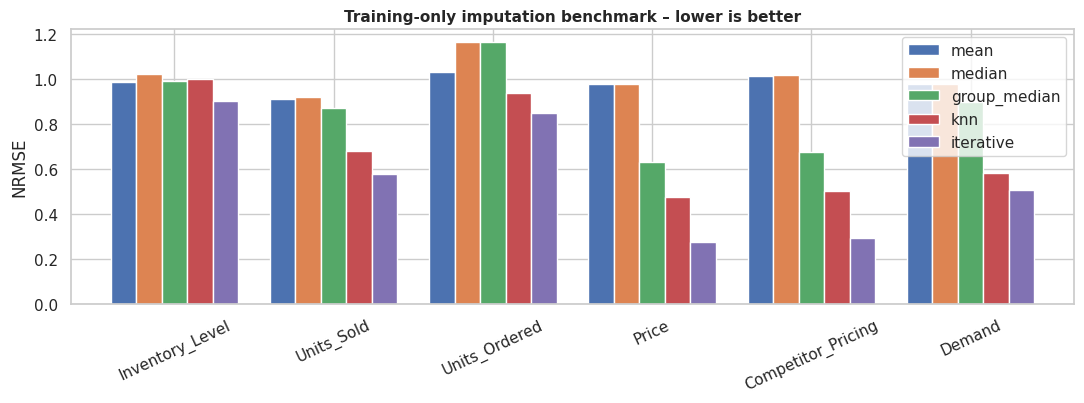

In [8]:
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler

CTX_NUM = ["Discount"] + BINARY

def impute_numeric(num, group, method, ctx_dummies=None):
    """Benchmark helper. Fits on this supplied sample; use training rows only for model selection."""
    out = num.copy()
    if method == "mean": return out.fillna(out.mean())
    if method == "median": return out.fillna(out.median())
    if method == "group_median":
        med = out.groupby(group, observed=True).transform("median")
        return out.fillna(med).fillna(out.median())
    Z = pd.concat([out, ctx_dummies], axis=1) if ctx_dummies is not None else out
    sc = StandardScaler().fit(Z)
    Zs = sc.transform(Z)
    imp = KNNImputer(n_neighbors=5, weights="distance") if method == "knn" else IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=RANDOM_STATE)
    Zimp = imp.fit_transform(Zs)
    return pd.DataFrame(sc.inverse_transform(Zimp), columns=Z.columns, index=Z.index)[out.columns]

def make_ctx(d):
    return pd.get_dummies(d[["Category", "Weather_Condition", "Seasonality"]].astype(object).fillna("Unknown"), dtype=float)

# Select the imputation strategy using training-period data only (never the hold-out dates).
train_for_benchmark = df.loc[df["Date"] < CUT_DATE]
eligible = train_for_benchmark.dropna(subset=CONT + CTX_NUM)
BENCH_N, MASK_FRAC = 4000, 0.10
if len(eligible) < 2:
    raise ValueError("Too few complete training rows to benchmark imputers.")
base = eligible.sample(n=min(BENCH_N, len(eligible)), random_state=RANDOM_STATE)
truth = base[CONT].copy()
rng = np.random.default_rng(RANDOM_STATE)
mask = pd.DataFrame(rng.random(truth.shape) < MASK_FRAC, index=truth.index, columns=CONT)
masked = truth.mask(mask)
num_in = pd.concat([masked, base[CTX_NUM]], axis=1)
ctx = make_ctx(base)

scores = {}
for m in ["mean", "median", "group_median", "knn", "iterative"]:
    t0 = time.time()
    imp = impute_numeric(num_in, base["Category"], m, ctx)[CONT]
    vals = {}
    for c in CONT:
        valid = mask[c]
        denom = truth[c].std()
        vals[c] = (np.sqrt(np.mean((imp.loc[valid, c] - truth.loc[valid, c]) ** 2)) / denom) if valid.any() and denom > 0 else np.nan
    scores[m] = vals
    print(f"{m:13s} mean NRMSE = {np.nanmean(list(vals.values())):.4f} ({time.time()-t0:.1f}s)")
score_df = pd.DataFrame(scores).T
score_df["MEAN"] = score_df.mean(axis=1)
display(score_df.sort_values("MEAN"))
best_imputer = score_df["MEAN"].idxmin()
print("\nBest imputation method selected from training dates only:", best_imputer)
ax = score_df.drop(columns="MEAN").T.plot(kind="bar", figsize=(11, 4.2), width=.8)
ax.set_title("Training-only imputation benchmark – lower is better")
ax.set_ylabel("NRMSE")
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


In [9]:
def fit_apply_imputation(train, all_data, numeric_method):
    """Fit all imputation statistics on training rows, then apply them to all rows."""
    tr, out = train.copy(), all_data.copy()
    num_cols = CONT + ["Discount"]
    # Categorical fill values learned only from training period.
    cat_cols = ["Category", "Region", "Weather_Condition", "Seasonality", "Store_ID", "Product_ID"]
    cat_modes = {c: (tr[c].mode(dropna=True).iloc[0] if tr[c].notna().any() else "Unknown") for c in cat_cols}
    product_category = tr.dropna(subset=["Category"]).groupby("Product_ID", observed=True)["Category"].agg(lambda x: x.mode().iloc[0]).to_dict()
    for d in (tr, out):
        d["Category"] = d["Category"].astype(object).where(d["Category"].notna(), d["Product_ID"].map(product_category)).fillna(cat_modes["Category"])
        for c in cat_cols:
            if c != "Category": d[c] = d[c].astype(object).fillna(cat_modes[c])
    # Binary mode learned from training rows only.
    binary_modes = {c: (tr[c].mode(dropna=True).iloc[0] if tr[c].notna().any() else 0) for c in BINARY}
    for d in (tr, out):
        for c in BINARY: d[c] = d[c].fillna(binary_modes[c])
    # Fit numeric imputer using training data only; transform all rows with the fitted object.
    ctx_train = pd.get_dummies(tr[["Category", "Weather_Condition", "Seasonality"]].astype(str), dtype=float)
    ctx_all = pd.get_dummies(out[["Category", "Weather_Condition", "Seasonality"]].astype(str), dtype=float).reindex(columns=ctx_train.columns, fill_value=0.0)
    train_num = tr[num_cols].copy()
    all_num = out[num_cols].copy()
    if numeric_method in ("mean", "median"):
        fill = train_num.mean() if numeric_method == "mean" else train_num.median()
        out[num_cols] = all_num.fillna(fill)
    elif numeric_method == "group_median":
        med = tr.assign(_group=tr["Category"].astype(str)).groupby("_group", observed=True)[num_cols].median()
        mapped = out["Category"].astype(str).map(lambda x: x)  # preserve row alignment
        group_fill = pd.DataFrame([med.loc[x] if x in med.index else pd.Series(index=num_cols, dtype=float) for x in mapped], index=out.index)
        out[num_cols] = all_num.fillna(group_fill).fillna(train_num.median())
    else:
        # Model-based imputers are fit only on training rows. Missing rows are supported by sklearn imputers.
        from sklearn.preprocessing import StandardScaler
        Ztr = pd.concat([train_num, ctx_train], axis=1)
        Zall = pd.concat([all_num, ctx_all], axis=1).reindex(columns=Ztr.columns, fill_value=0.0)
        sc = StandardScaler().fit(Ztr)
        imp = KNNImputer(n_neighbors=5, weights="distance") if numeric_method == "knn" else IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=RANDOM_STATE)
        imp.fit(sc.transform(Ztr))
        transformed = sc.inverse_transform(imp.transform(sc.transform(Zall)))
        out[num_cols] = pd.DataFrame(transformed, columns=Ztr.columns, index=out.index)[num_cols]
    for c in COUNTS + ["Discount"]: out[c] = out[c].clip(lower=0).round()
    for c in BINARY: out[c] = out[c].round().clip(0, 1)
    # Dates were validated before split; never backfill a date from a future row.
    return out

n_missing_before = int(df.isna().sum().sum())
train_raw_for_cleaning = df.loc[df["Date"] < CUT_DATE].copy()
df = fit_apply_imputation(train_raw_for_cleaning, df, best_imputer)
print(f"Missing cells before imputation: {n_missing_before:,} | after: {int(df.isna().sum().sum()):,}")
if df.isna().any().any():
    print("Remaining missing values by column:", df.isna().sum()[df.isna().any()].to_dict())
df_clean = df.copy()  # imputation fitted on training dates only


Missing cells before imputation: 0 | after: 0


## 4️⃣ Outliers – detect and cap in the proper way
**Strategy**
* Continuous columns only (binary flags / discount are discrete codes, not outliers).
* Prices and demand differ a lot between categories (a 120 $ furniture item is normal, a 120 $ toy is not) → **fences are computed *within each Category***, not globally.
* IQR fences: `Q1 − k·IQR` … `Q3 + k·IQR`. `k = 1.5` for roughly symmetric columns, `k = 3` (only extreme points) for strongly skewed columns (|skew| > 1) so that we do not flatten a natural long tail.
* **Fences are learned from the training period only** (`Date < CUT_DATE`) and then applied to every row. Nothing from the hold-out period influences preprocessing.
* **The target `Demand` is never capped.** The model must be judged on real demand, including genuine peaks; capping the target would make the hold-out score look better than reality.
* **Cap (winsorise) instead of deleting** – we keep all rows and just pull extreme values to the fence.
* An Isolation Forest (fitted on the training period) is run as a *multivariate* cross‑check.

In [10]:
is_train = df["Date"] < CUT_DATE
CAP_COLS = [c for c in CONT if c != TARGET]            # the target is never capped

def iqr_fences(s, k):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

K_BY_COL = {c: (3.0 if abs(df.loc[is_train, c].skew()) > 1 else 1.5) for c in CAP_COLS}

def category_fences(col, k):
    """Per-Category IQR fences learned on TRAIN rows only, mapped onto every row."""
    q = df.loc[is_train].groupby("Category", observed=True)[col].quantile([.25, .75]).unstack()
    iqr = q[0.75] - q[0.25]
    lo = (q[0.25] - k * iqr).clip(lower=0)
    hi = q[0.75] + k * iqr
    cat = df["Category"].astype(object)
    return cat.map(lo).astype(float), cat.map(hi).astype(float)

rows = []
for c in CAP_COLS:
    lo, hi = iqr_fences(df.loc[is_train, c], 1.5)
    n_global = int(((df[c] < lo) | (df[c] > hi)).sum())
    k = K_BY_COL[c]
    lo_g, hi_g = category_fences(c, k)
    n_group = int(((df[c] < lo_g) | (df[c] > hi_g)).sum())
    rows.append(dict(column=c, skew_train=df.loc[is_train, c].skew(), k_used=k, global_IQR1_5=n_global, global_pct=100 * n_global / len(df),
                     per_category_outliers=n_group, per_category_pct=100 * n_group / len(df)))
outlier_tbl = pd.DataFrame(rows).set_index("column")
display(outlier_tbl)
print(f"ℹ️ {TARGET} (target) is intentionally NOT capped.")

from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=RANDOM_STATE).fit(df.loc[is_train, CONT])
print("Isolation-Forest multivariate anomalies (fitted on the training period, 1 % contamination):", int((iso.predict(df[CONT]) == -1).sum()))

,skew_train,k_used,global_IQR1_5,global_pct,per_category_outliers,per_category_pct
column,,,,,,
Inventory_Level,1.6163,3.0000,2682,3.5289,302,0.3974
Units_Sold,0.8038,1.5000,1323,1.7408,1100,1.4474
Units_Ordered,2.5225,3.0000,7429,9.7750,3250,4.2763
Price,0.4847,1.5000,68,0.0895,206,0.2711
Competitor_Pricing,0.5506,1.5000,182,0.2395,325,0.4276


ℹ️ Demand (target) is intentionally NOT capped.
Isolation-Forest multivariate anomalies (fitted on the training period, 1 % contamination): 695


,capped_low,capped_high,pct_rows
column,,,
Inventory_Level,0,302,0.3974
Units_Sold,0,1100,1.4474
Units_Ordered,0,3250,4.2763
Price,0,206,0.2711
Competitor_Pricing,0,325,0.4276


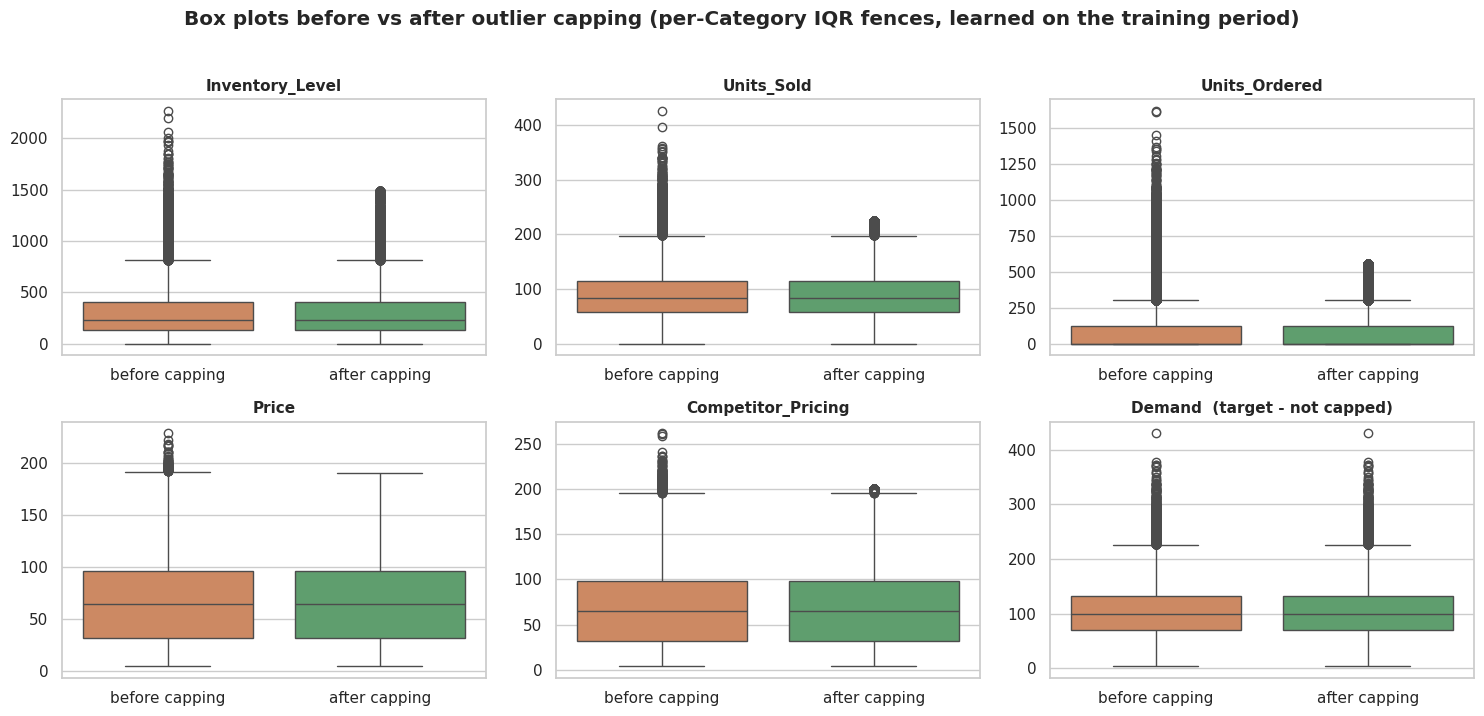

In [11]:
df_before_cap = df.copy()
cap_log = []
for c in CAP_COLS:
    lo, hi = category_fences(c, K_BY_COL[c])
    if c in ("Price", "Competitor_Pricing"):
        lo = lo.clip(lower=0.01)
    n_lo, n_hi = int((df[c] < lo).sum()), int((df[c] > hi).sum())
    df[c] = df[c].clip(lower=lo, upper=hi)
    if c in COUNTS: df[c] = df[c].round().astype("int32")
    cap_log.append(dict(column=c, capped_low=n_lo, capped_high=n_hi, pct_rows=100 * (n_lo + n_hi) / len(df)))
display(pd.DataFrame(cap_log).set_index("column"))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), CONT):
    sns.boxplot(data=pd.DataFrame({"before capping": df_before_cap[c], "after capping": df[c]}), ax=ax, palette=["#DD8452", "#55A868"])
    ax.set_title(c + ("  (target - not capped)" if c == TARGET else ""))
plt.suptitle("Box plots before vs after outlier capping (per-Category IQR fences, learned on the training period)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

## 5️⃣ Is the data normally distributed? Normalise it
We use **histogram + KDE**, **Q‑Q plot**, **box plot**, skewness / kurtosis and formal tests
(Shapiro–Wilk on a 5,000 sample, D’Agostino K², Anderson–Darling).
> With 76 k rows formal tests reject normality for almost anything, so we judge mainly by **skewness (|skew| < 0.5)** and **excess kurtosis (|kurt| < 1)** together with the plots.

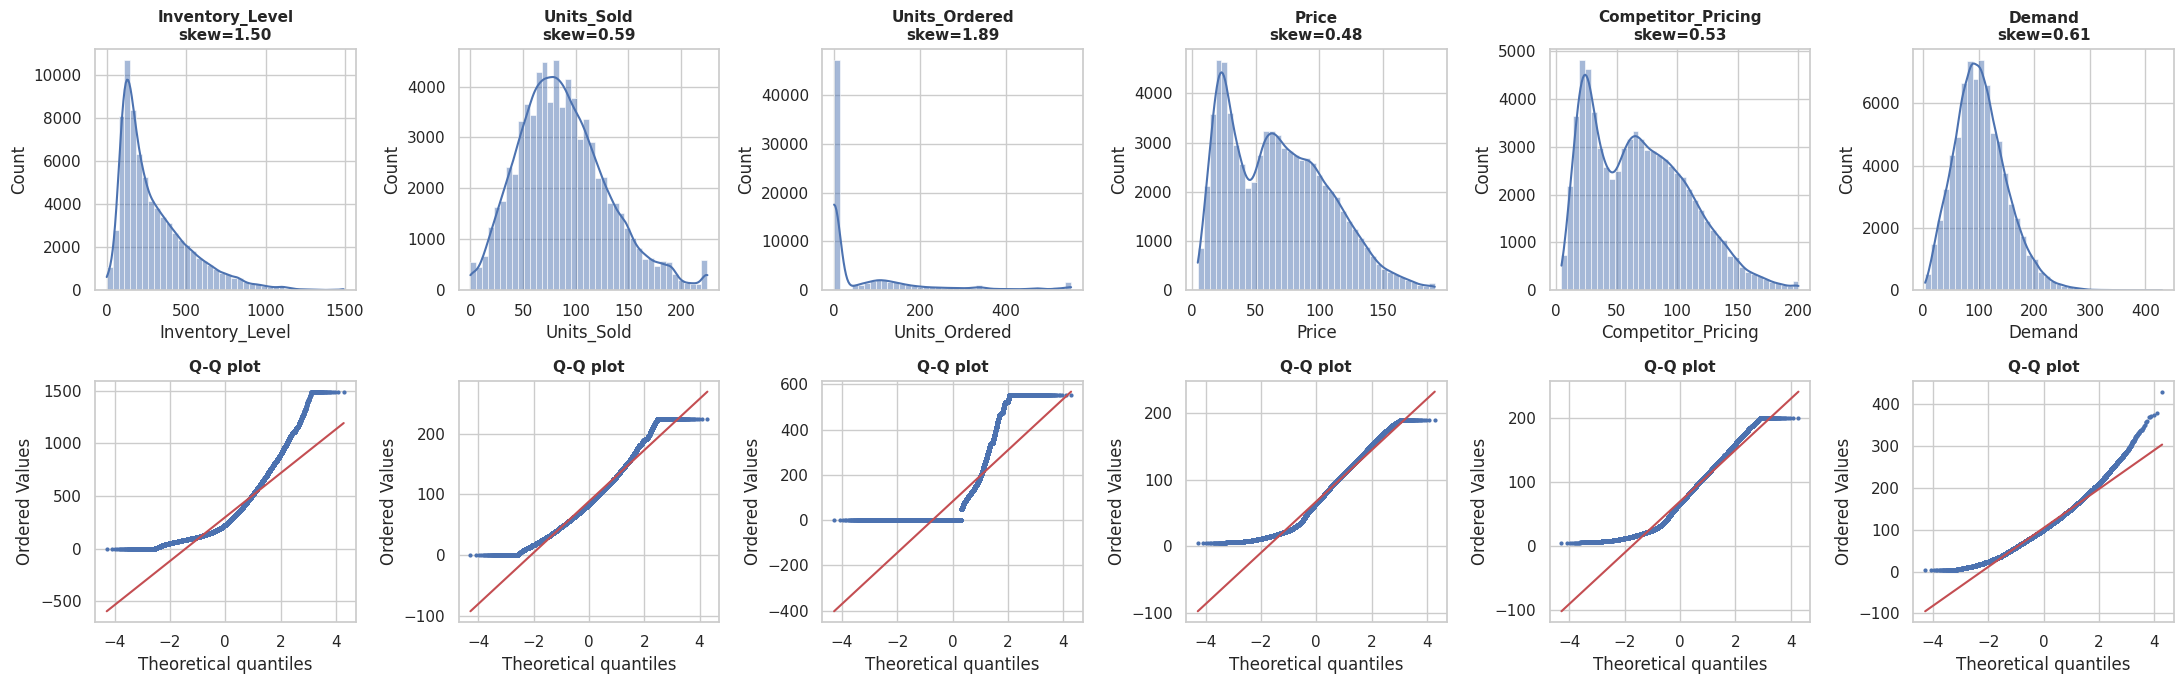

,skewness,excess_kurtosis,shapiro_p,dagostino_p,anderson_stat,anderson_crit_5pct,verdict
column,,,,,,,
Inventory_Level,1.4953,2.5817,0.0000,0.0000,"2,948.2151",0.7870,NOT normal
Units_Sold,0.5890,0.2793,0.0000,0.0000,357.4635,0.7870,NOT normal
Units_Ordered,1.8915,2.8084,0.0000,0.0000,"10,491.5146",0.7870,NOT normal
Price,0.4780,-0.5103,0.0000,0.0000,767.2020,0.7870,≈ normal
Competitor_Pricing,0.5316,-0.3839,0.0000,0.0000,777.9329,0.7870,NOT normal
Demand,0.6078,0.6748,0.0000,0.0000,259.7176,0.7870,NOT normal


In [12]:
fig, axes = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(CONT):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color="#4C72B0", bins=40)
    axes[0, i].set_title(f"{c}\nskew={df[c].skew():.2f}")
    stats.probplot(df[c], dist="norm", plot=axes[1, i]); axes[1, i].set_title("Q-Q plot"); axes[1, i].get_lines()[0].set_markersize(2)
plt.tight_layout(); plt.show()

rows = []
for c in CONT:
    x = df[c].values
    samp = np.random.default_rng(RANDOM_STATE).choice(x, 5000, replace=False)
    ad = stats.anderson(x, dist="norm")
    rows.append(dict(column=c, skewness=stats.skew(x), excess_kurtosis=stats.kurtosis(x),
                     shapiro_p=stats.shapiro(samp)[1], dagostino_p=stats.normaltest(x)[1],
                     anderson_stat=ad.statistic, anderson_crit_5pct=ad.critical_values[2]))
norm_tbl = pd.DataFrame(rows).set_index("column")
norm_tbl["verdict"] = np.where((norm_tbl["skewness"].abs() < .5) & (norm_tbl.excess_kurtosis.abs() < 1), "≈ normal", "NOT normal")
display(norm_tbl)

### 5.2 Box plots of the **whole dataset** – numeric *and* categorical

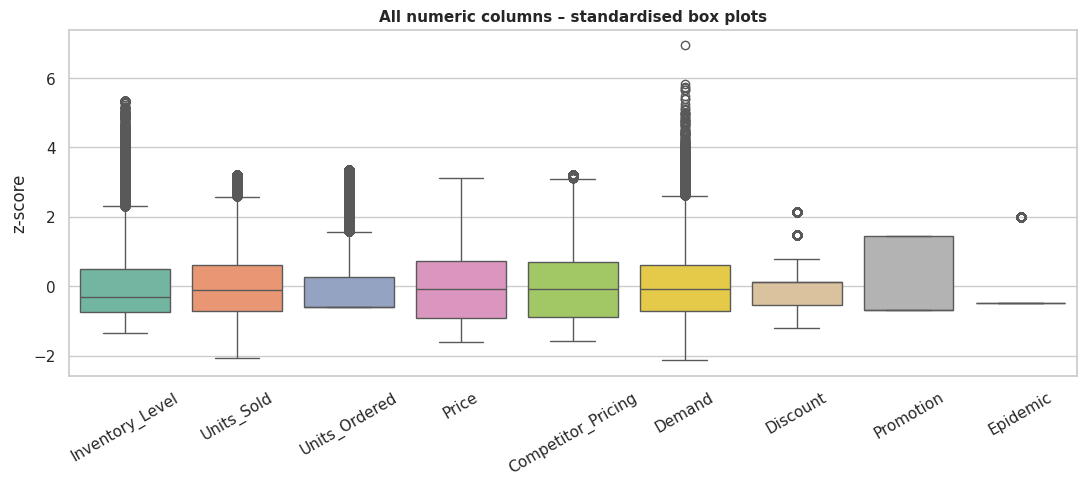

In [13]:
# (a) all numeric columns on one comparable (standardised) scale
num_all = CONT + ["Discount"] + BINARY
z = (df[num_all] - df[num_all].mean()) / df[num_all].std()
plt.figure(figsize=(13, 4.5))
sns.boxplot(data=z, orient="v", palette="Set2"); plt.xticks(rotation=30)
plt.title("All numeric columns – standardised box plots"); plt.ylabel("z-score"); plt.show()

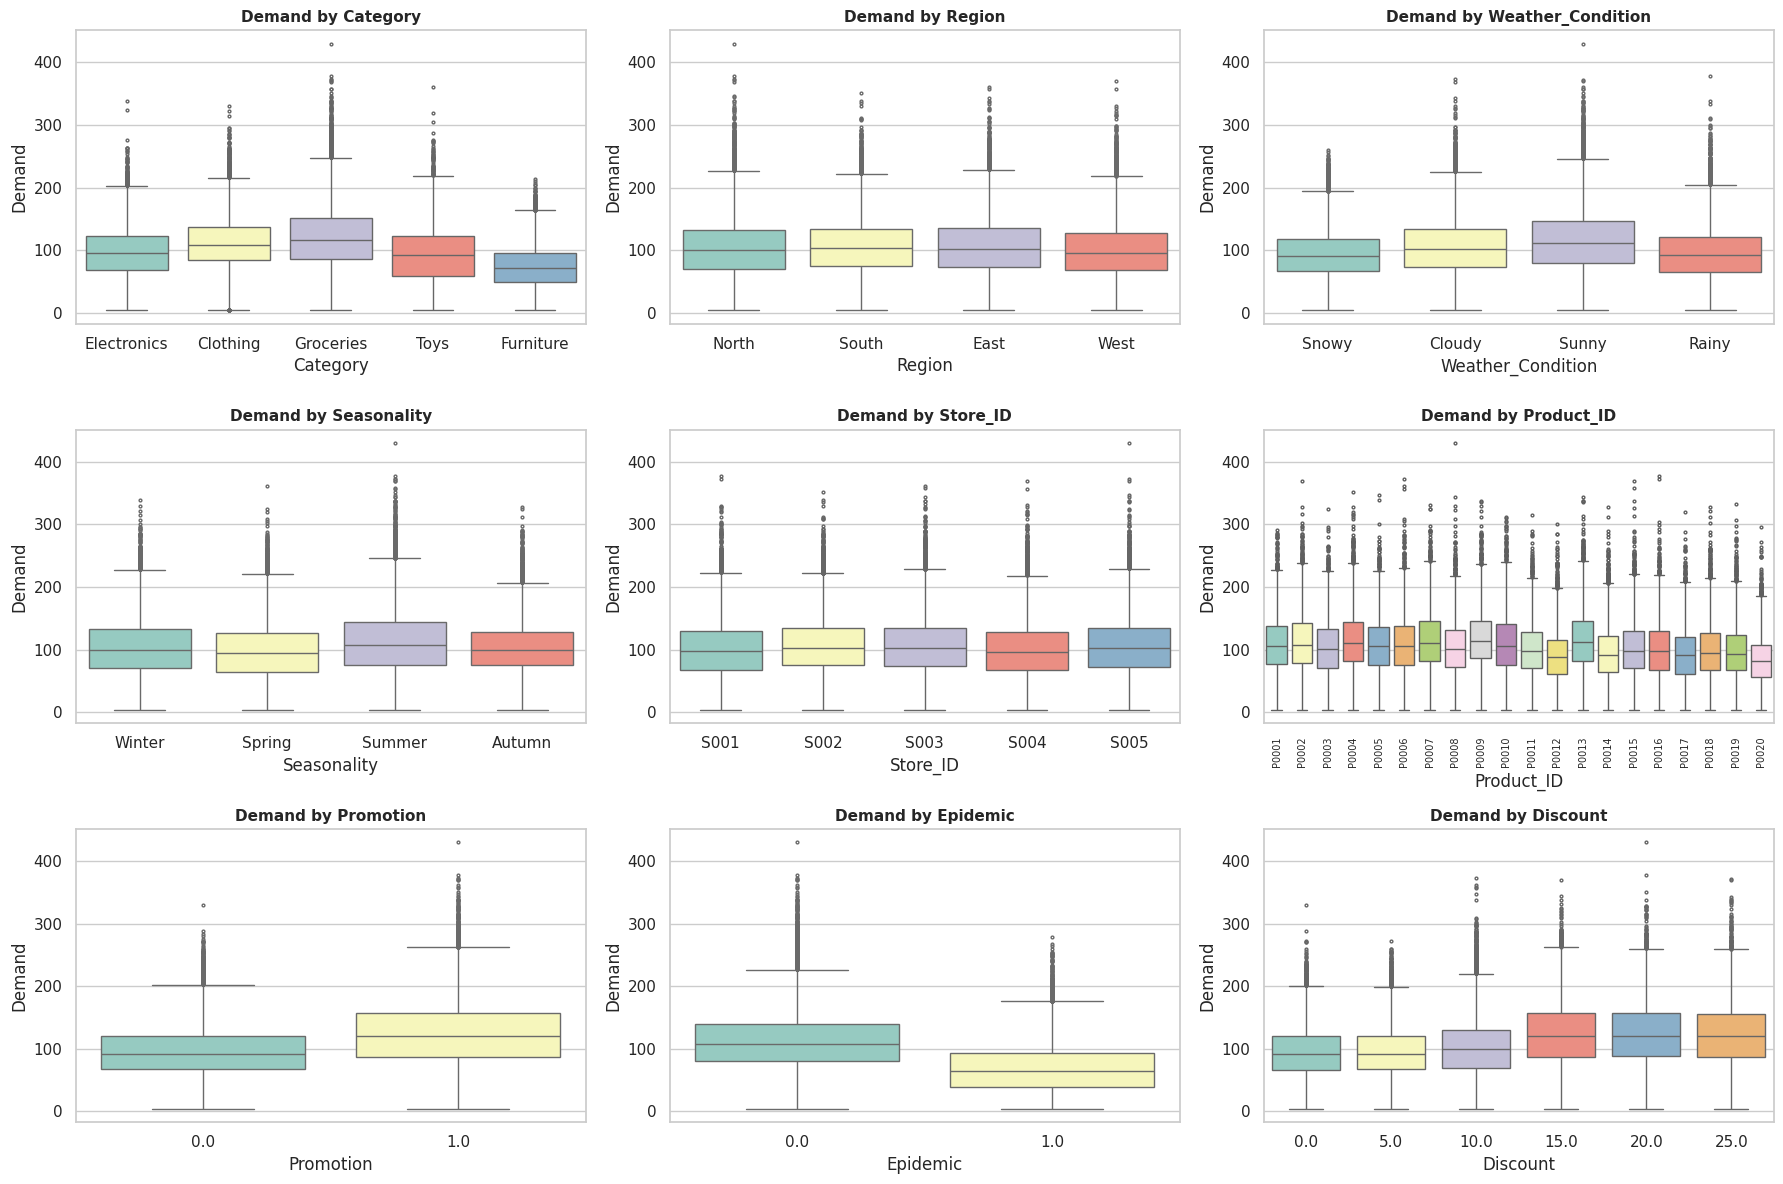

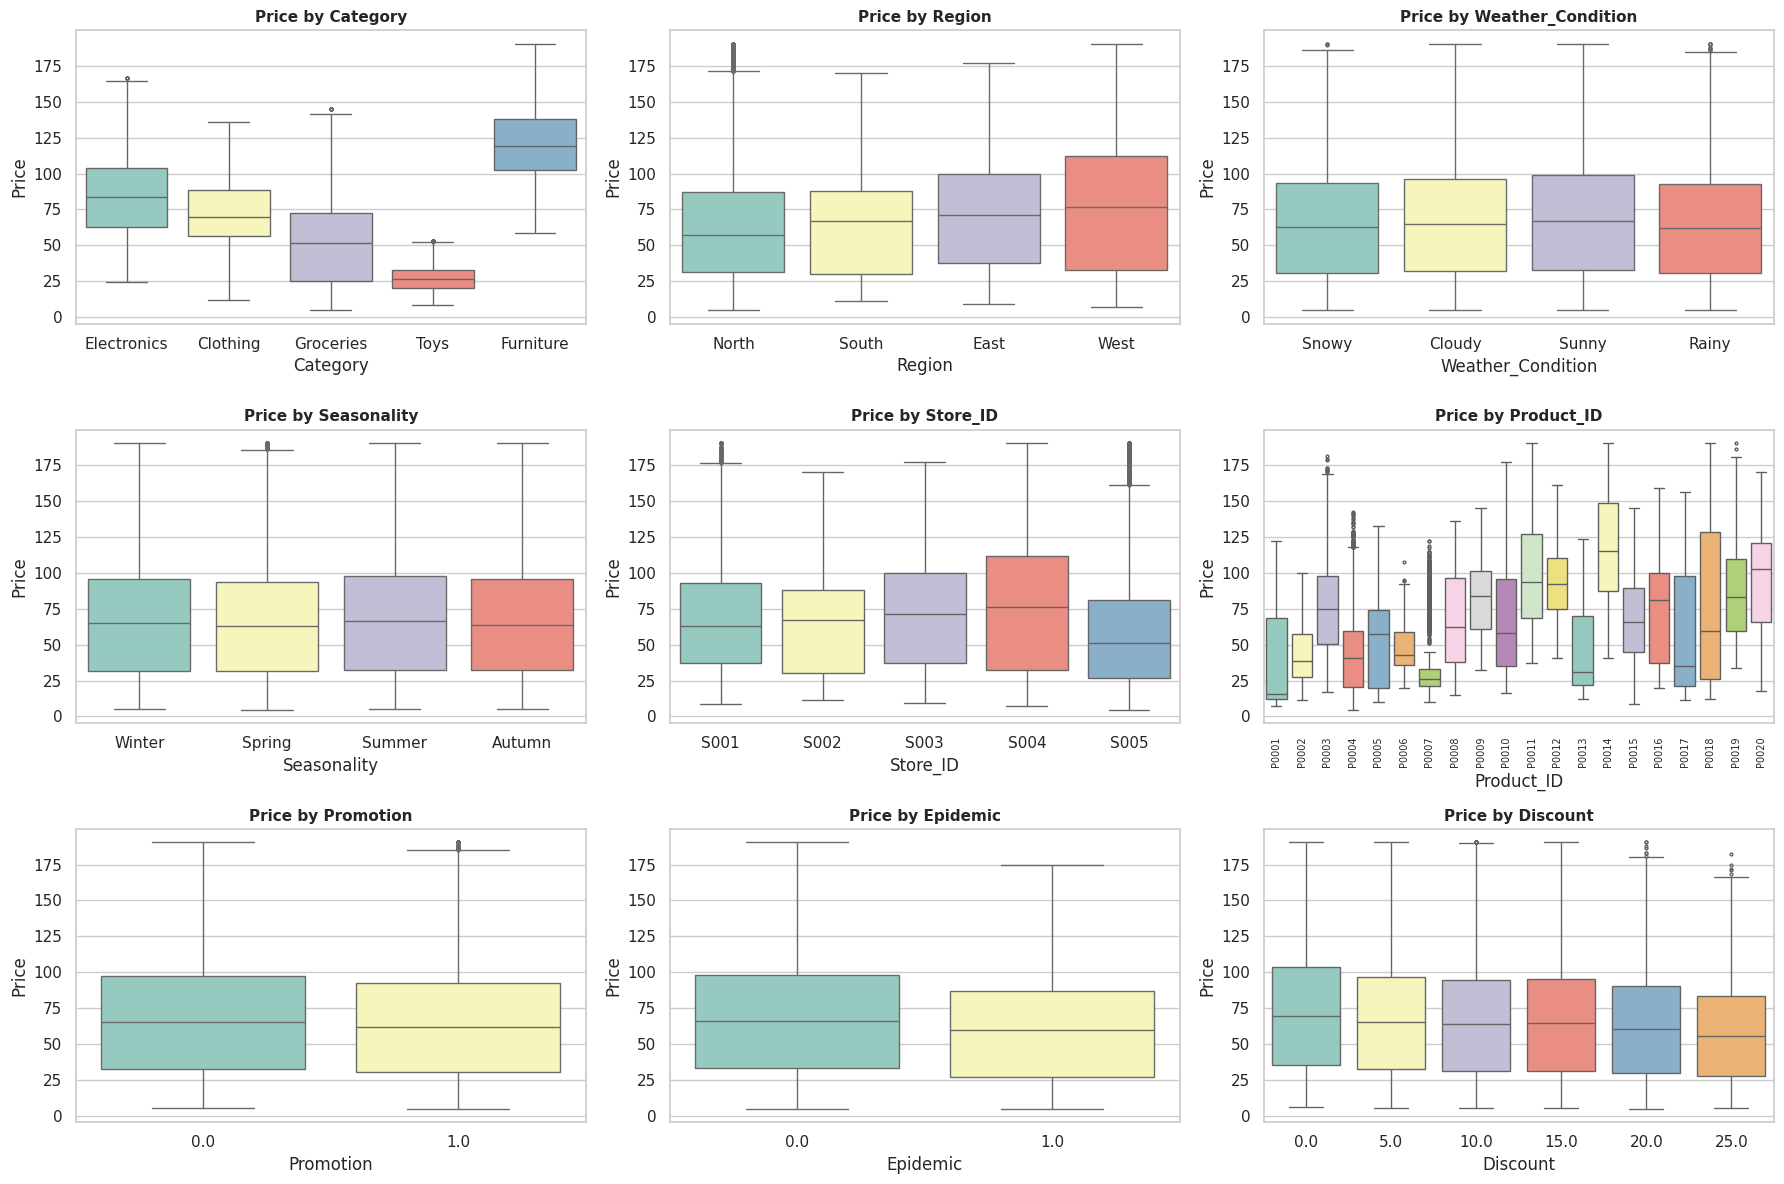

In [14]:
# (b) categorical columns: distribution of the target and of Price inside each level
CAT_PLOT = ["Category", "Region", "Weather_Condition", "Seasonality", "Store_ID", "Product_ID", "Promotion", "Epidemic", "Discount"]
for y in ["Demand", "Price"]:
    fig, axes = plt.subplots(3, 3, figsize=(18, 12))
    for ax, c in zip(axes.ravel(), CAT_PLOT):
        sns.boxplot(data=df, x=c, y=y, ax=ax, palette="Set3", fliersize=2)
        ax.set_title(f"{y} by {c}")
        if c == "Product_ID": ax.tick_params(axis="x", rotation=90, labelsize=7)
    plt.tight_layout(); plt.show()

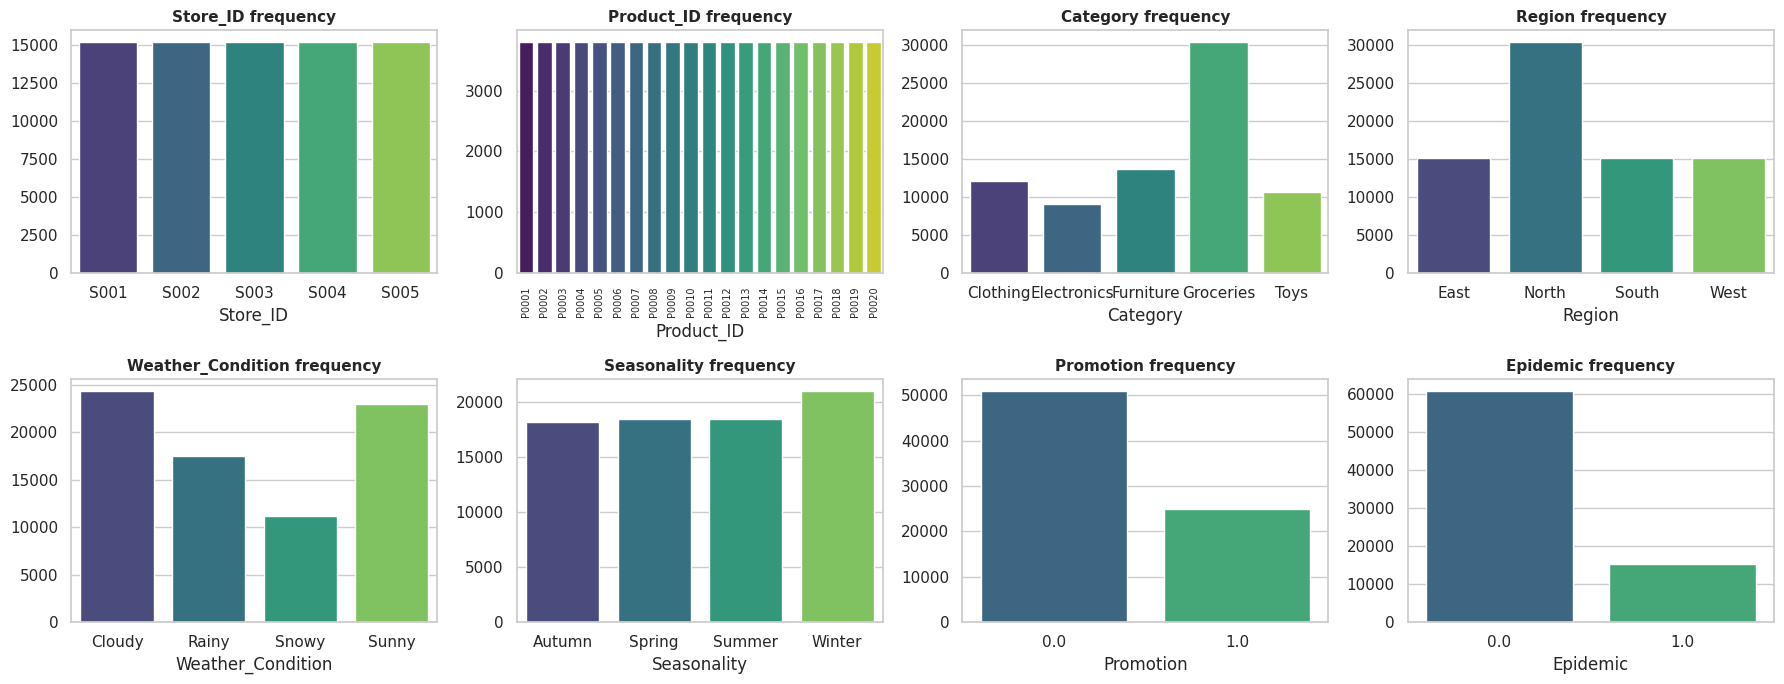

,levels,chi2,p_value,uniform
column,,,,
Store_ID,5,0.0000,1.0000,True
Product_ID,20,0.0000,1.0000,True
Category,5,"19,760.0000",0.0000,False
Region,4,"9,120.0000",0.0000,False
Weather_Condition,4,"5,699.2421",0.0000,False
Seasonality,4,282.1053,0.0000,False
Promotion,2,"8,894.7368",0.0000,False
Epidemic,2,"27,360.0000",0.0000,False


In [15]:
# (c) categorical columns themselves: frequency plots + chi-square goodness-of-fit (are levels equally frequent?)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
gof = []
for ax, c in zip(axes.ravel(), CAT_NOM + BINARY):
    vc = df[c].value_counts().sort_index()
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, palette="viridis"); ax.set_title(f"{c} frequency")
    if c == "Product_ID": ax.tick_params(axis="x", rotation=90, labelsize=7)
    chi, p = stats.chisquare(vc.values)
    gof.append(dict(column=c, levels=len(vc), chi2=chi, p_value=p, uniform=p > ALPHA))
plt.tight_layout(); plt.show()
display(pd.DataFrame(gof).set_index("column"))

## 6️⃣ Variance (statistical tests) and multicollinearity
### 6.1 Variance
* Variance / std / coefficient of variation (CV) of each numeric column.
* **Levene** (robust, median‑centred) and **Bartlett** tests of *equal variance across groups* — H₀: all groups have the same variance. If H₀ is rejected, plain ANOVA is not safe and we use Welch/Kruskal later.

,variance,std,mean,CV_%
Inventory_Level,"50,212.4855",224.0814,300.5013,74.5692
Units_Sold,"1,833.2119",42.8160,88.4616,48.4007
Units_Ordered,"19,570.0089",139.8928,82.8514,168.8479
Price,"1,546.6468",39.3274,67.7052,58.0863
Competitor_Pricing,"1,667.0607",40.8297,69.4118,58.8224
Demand,"2,205.6925",46.9648,104.3172,45.0212


,numeric,grouped_by,levene_p,bartlett_p,var_ratio_max_min,equal_variance
0,Demand,Category,0.0000,0.0000,2.2369,False
1,Demand,Region,0.0000,0.0000,1.0958,False
2,Demand,Seasonality,0.0000,0.0000,1.5306,False
3,Demand,Weather_Condition,0.0000,0.0000,1.6714,False
4,Demand,Promotion,0.0000,0.0000,1.6932,False
5,Demand,Epidemic,0.0000,0.0000,1.2460,False
6,Demand,Store_ID,0.0000,0.0000,1.1201,False
7,Price,Category,0.0000,0.0000,11.1170,False
8,Price,Region,0.0000,0.0000,1.9674,False
9,Price,Seasonality,0.0000,0.0001,1.0643,False


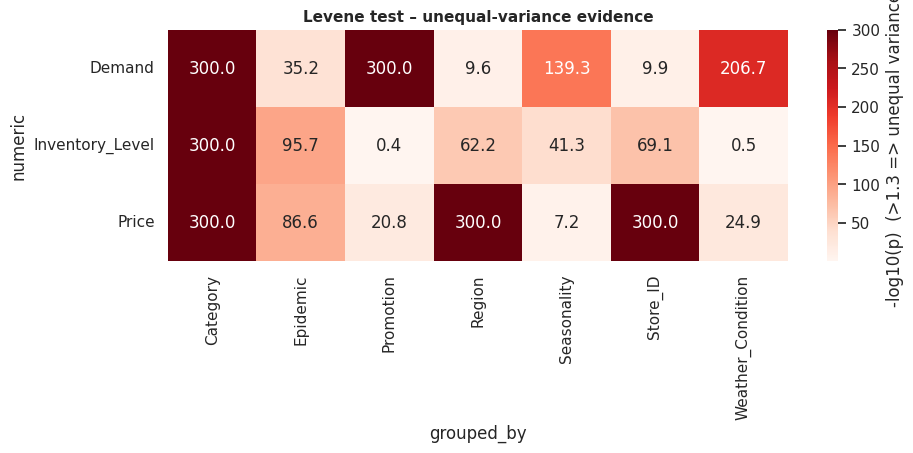

In [16]:
var_tbl = pd.DataFrame({"variance": df[CONT].var(), "std": df[CONT].std(), "mean": df[CONT].mean()})
var_tbl["CV_%"] = 100 * var_tbl["std"] / var_tbl["mean"]
display(var_tbl)

def levene_table(d, nums, cats):
    rows = []
    for n in nums:
        for c in cats:
            groups = [g[n].values.astype(float) for _, g in d.groupby(c, observed=True)]
            lev, bart = stats.levene(*groups, center="median"), stats.bartlett(*groups)
            v = [np.var(g, ddof=1) for g in groups]
            rows.append(dict(numeric=n, grouped_by=c, levene_p=lev.pvalue, bartlett_p=bart.pvalue,
                             var_ratio_max_min=max(v)/min(v), equal_variance=lev.pvalue > ALPHA))
    return pd.DataFrame(rows)

lev = levene_table(df, ["Demand", "Price", "Inventory_Level"], ["Category", "Region", "Seasonality", "Weather_Condition", "Promotion", "Epidemic", "Store_ID"])
display(lev)
piv = lev.pivot(index="numeric", columns="grouped_by", values="levene_p")
plt.figure(figsize=(10, 3)); sns.heatmap(-np.log10(piv.clip(lower=1e-300)), annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "-log10(p)  (>1.3 => unequal variance)"})
plt.title("Levene test – unequal-variance evidence"); plt.show()

### 6.2 Multicollinearity – on **all** columns
Numeric↔numeric uses Pearson, categorical↔categorical uses **Cramér’s V**, categorical↔numeric uses the **correlation ratio η**; so every column is compared with every other column on a 0–1 scale. Then **VIF** and the **condition number** confirm the numeric part.

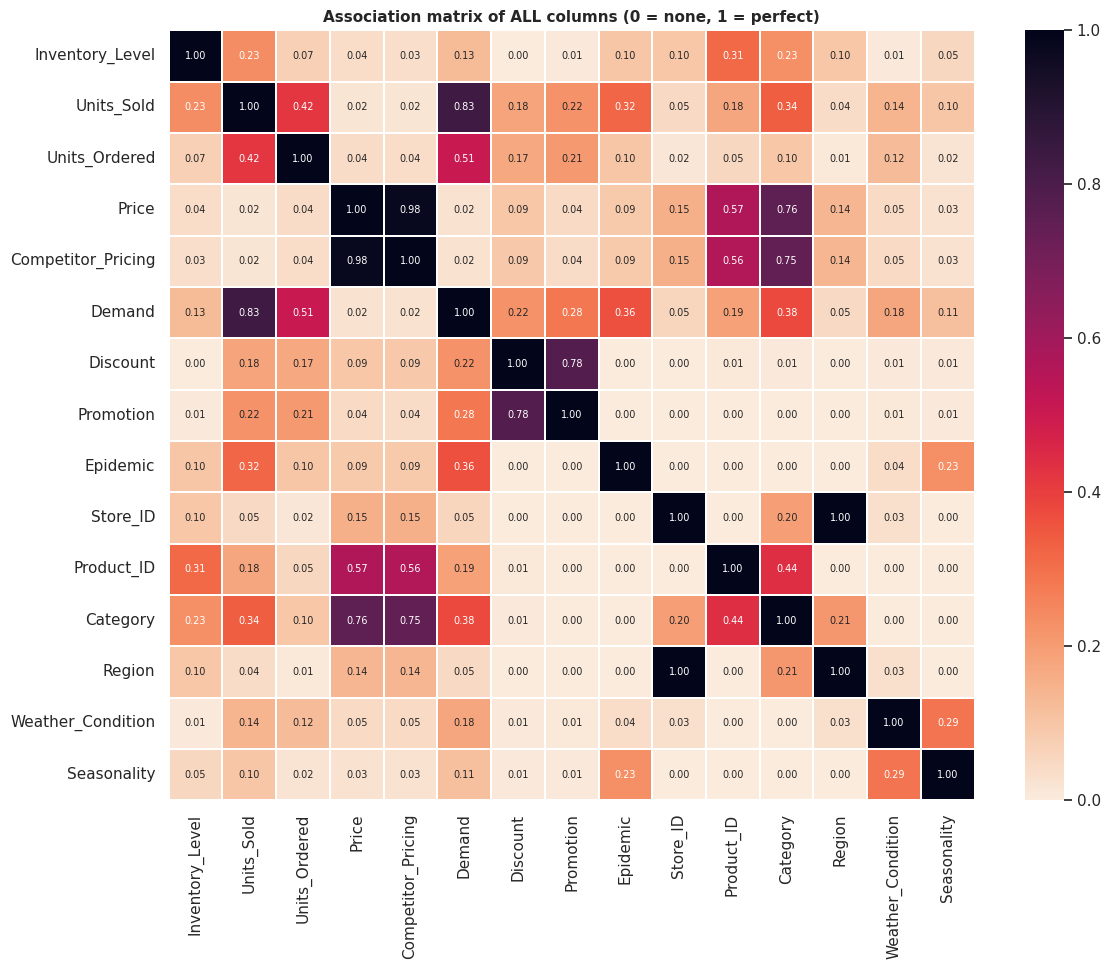

Strongest associations (>= 0.5):


,,strength
Store_ID,Region,1.0000
Price,Competitor_Pricing,0.9770
Units_Sold,Demand,0.8326
Discount,Promotion,0.7840
Price,Category,0.7574
Competitor_Pricing,Category,0.7482
Price,Product_ID,0.5698
Competitor_Pricing,Product_ID,0.5619
Units_Ordered,Demand,0.5068


In [17]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); phi2 = chi2 / n; r, k = ct.shape
    phi2c = max(0, phi2 - (k-1)*(r-1)/(n-1)); rc, kc = r - (r-1)**2/(n-1), k - (k-1)**2/(n-1)
    return np.sqrt(phi2c / max(1e-12, min(kc-1, rc-1)))

def corr_ratio(cat, val):
    g = pd.DataFrame({"c": cat.astype(str).values, "v": val.values}).groupby("c")["v"]
    ss_b = (g.count() * (g.mean() - val.mean())**2).sum(); ss_t = ((val - val.mean())**2).sum()
    return np.sqrt(ss_b / ss_t)

ALL_COLS = CONT + ["Discount"] + BINARY + CAT_NOM
NUMERICLIKE = CONT + ["Discount"] + BINARY
assoc = pd.DataFrame(np.eye(len(ALL_COLS)), index=ALL_COLS, columns=ALL_COLS)
for a, b in itertools.combinations(ALL_COLS, 2):
    a_num, b_num = a in NUMERICLIKE, b in NUMERICLIKE
    if a_num and b_num:   v = abs(df[a].corr(df[b]))
    elif not a_num and not b_num: v = cramers_v(df[a], df[b])
    else:
        cat, num = (a, b) if b_num else (b, a); v = corr_ratio(df[cat], df[num])
    assoc.loc[a, b] = assoc.loc[b, a] = v

plt.figure(figsize=(13, 10))
sns.heatmap(assoc, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, annot_kws={"size": 7}, linewidths=.3)
plt.title("Association matrix of ALL columns (0 = none, 1 = perfect)"); plt.show()

pairs = assoc.where(np.triu(np.ones(assoc.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Strongest associations (>= 0.5):"); display(pairs[pairs >= 0.5].rename("strength").to_frame())

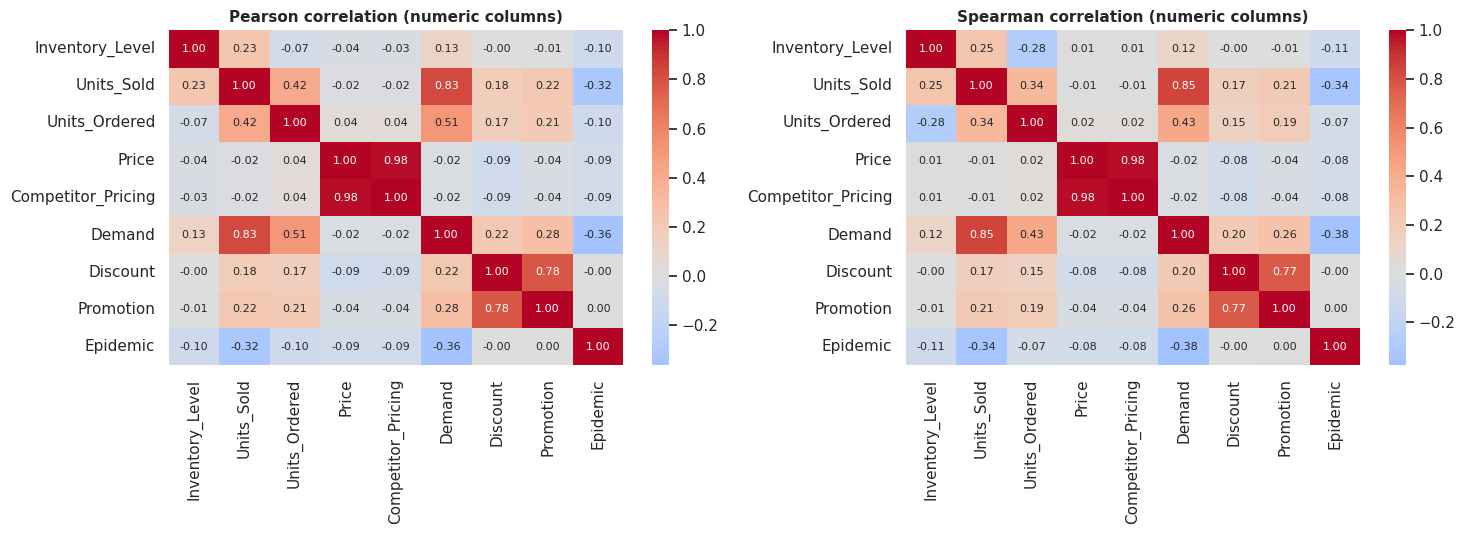

VIF – numeric predictors (target excluded):


,VIF,flag
Price,21.9679,SEVERE (>10)
Competitor_Pricing,21.9544,SEVERE (>10)
Promotion,2.6767,ok
Discount,2.6211,ok
Units_Sold,1.4999,ok
Units_Ordered,1.2827,ok
Epidemic,1.1369,ok
Inventory_Level,1.1015,ok


VIF – numeric + dummy categoricals:


,VIF,flag
Price,22.9036,SEVERE (>10)
Competitor_Pricing,22.0430,SEVERE (>10)
Promotion,2.6847,ok
Discount,2.6506,ok
Category_Furniture,2.5849,ok
Category_Groceries,2.3156,ok
Category_Toys,2.0011,ok
Units_Sold,1.7631,ok
Seasonality_Winter,1.6899,ok
Seasonality_Spring,1.6874,ok


Condition number of standardised numeric predictors: 9.6  (>30 = serious multicollinearity)


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, meth in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[NUMERICLIKE].corr(method=meth), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{meth.title()} correlation (numeric columns)")
plt.tight_layout(); plt.show()

def vif_table(X):
    Xc = sm.add_constant((X - X.mean()) / X.std())
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        out = pd.Series({c: variance_inflation_factor(Xc.values, i) for i, c in enumerate(Xc.columns) if c != "const"}, name="VIF")
    return out.sort_values(ascending=False).to_frame().assign(flag=lambda t: np.where(t.VIF > 10, "SEVERE (>10)", np.where(t.VIF > 5, "moderate (>5)", "ok")))

X_vif = df[[c for c in NUMERICLIKE if c != TARGET]]
print("VIF – numeric predictors (target excluded):"); display(vif_table(X_vif))

# including dummy-coded categoricals (Store/Product/Region are nested inside each other -> excluded to avoid perfect collinearity)
X_vif_full = pd.concat([X_vif, pd.get_dummies(df[["Category", "Weather_Condition", "Seasonality"]], drop_first=True, dtype=float)], axis=1)
print("VIF – numeric + dummy categoricals:"); display(vif_table(X_vif_full))

Z = ((X_vif - X_vif.mean()) / X_vif.std()).values
print(f"Condition number of standardised numeric predictors: {np.linalg.cond(Z):.1f}  (>30 = serious multicollinearity)")

**Reading the results.** `Price` and `Competitor_Pricing` are almost the same number (competitors price close to us), and `Units_Sold` / `Units_Ordered` / `Inventory_Level` move together. Instead of keeping two near‑identical price columns we will later express the competitor signal as a **price ratio** (`Price / Competitor_Pricing`) – this is also exactly the quantity a pricing engine reacts to. `Region` is fully determined by `Store_ID` (Cramér’s V ≈ 1) so one of them is redundant.

## 7️⃣ Dependent or independent? Group comparison and hypothesis tests
### 7.1 Are the variables independent of each other?
* **Categorical ↔ categorical:** χ² test of independence (H₀: the two variables are independent) + Cramér’s V effect size.
* **Numeric ↔ numeric:** Spearman rank correlation test (H₀: ρ = 0).
* **Observations over time:** Ljung–Box test (H₀: no autocorrelation) – tells us whether rows are independent samples or a time series.

In [19]:
CAT_TEST = CAT_NOM + BINARY + ["Discount"]
rows = []
for a, b in itertools.combinations(CAT_TEST, 2):
    ct = pd.crosstab(df[a], df[b]); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append(dict(var_1=a, var_2=b, chi2=chi2, dof=dof, p_value=p, cramers_v=cramers_v(df[a], df[b]),
                     relation="DEPENDENT" if p < ALPHA else "independent"))
chi_tbl = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
display(chi_tbl.head(15))
print(f"{(chi_tbl.relation=='DEPENDENT').sum()} of {len(chi_tbl)} categorical pairs are statistically dependent.")
print("Statistically independent pairs:"); display(chi_tbl[chi_tbl.relation == "independent"])

,var_1,var_2,chi2,dof,p_value,cramers_v,relation
2,Store_ID,Region,"228,000.0000",12,0.0000,1.0000,DEPENDENT
34,Promotion,Discount,"55,090.2902",5,0.0000,0.8514,DEPENDENT
8,Product_ID,Category,"58,634.6032",76,0.0000,0.4389,DEPENDENT
26,Weather_Condition,Seasonality,"19,068.1289",9,0.0000,0.2891,DEPENDENT
31,Seasonality,Epidemic,"4,083.7813",3,0.0000,0.2317,DEPENDENT
15,Category,Region,"10,489.2063",12,0.0000,0.2144,DEPENDENT
1,Store_ID,Category,"11,988.0952",16,0.0000,0.1985,DEPENDENT
28,Weather_Condition,Epidemic,113.9808,3,0.0000,0.0382,DEPENDENT
21,Region,Weather_Condition,216.4488,9,0.0000,0.0302,DEPENDENT
3,Store_ID,Weather_Condition,216.4488,12,0.0000,0.0299,DEPENDENT


10 of 36 categorical pairs are statistically dependent.
Statistically independent pairs:


,var_1,var_2,chi2,dof,p_value,cramers_v,relation
27,Weather_Condition,Promotion,4.9434,3,0.1760,0.0051,independent
35,Epidemic,Discount,6.1601,5,0.2909,0.0039,independent
16,Category,Weather_Condition,13.2434,12,0.3516,0.0023,independent
30,Seasonality,Promotion,3.2372,3,0.3565,0.0018,independent
0,Store_ID,Product_ID,0.0000,76,1.0000,0.0000,independent
4,Store_ID,Seasonality,0.0000,12,1.0000,0.0000,independent
7,Store_ID,Discount,14.7423,20,0.7910,0.0000,independent
9,Product_ID,Region,0.0000,57,1.0000,0.0000,independent
6,Store_ID,Epidemic,0.0000,4,1.0000,0.0000,independent
5,Store_ID,Promotion,0.0000,4,1.0000,0.0000,independent


,var_1,var_2,spearman_rho,p_value,relation
21,Price,Competitor_Pricing,0.9837,0.0000,DEPENDENT
11,Units_Sold,Demand,0.8473,0.0000,DEPENDENT
33,Discount,Promotion,0.7657,0.0000,DEPENDENT
17,Units_Ordered,Demand,0.4267,0.0000,DEPENDENT
32,Demand,Epidemic,-0.3770,0.0000,DEPENDENT
14,Units_Sold,Epidemic,-0.3412,0.0000,DEPENDENT
8,Units_Sold,Units_Ordered,0.3375,0.0000,DEPENDENT
1,Inventory_Level,Units_Ordered,-0.2781,0.0000,DEPENDENT
31,Demand,Promotion,0.2613,0.0000,DEPENDENT
0,Inventory_Level,Units_Sold,0.2521,0.0000,DEPENDENT


,lb_stat,lb_pvalue
7,"2,613.8661",0.0000
14,"3,571.4653",0.0000
30,"3,798.1558",0.0000


Durbin-Watson of the daily demand series: 0.342 (2 = no autocorrelation)


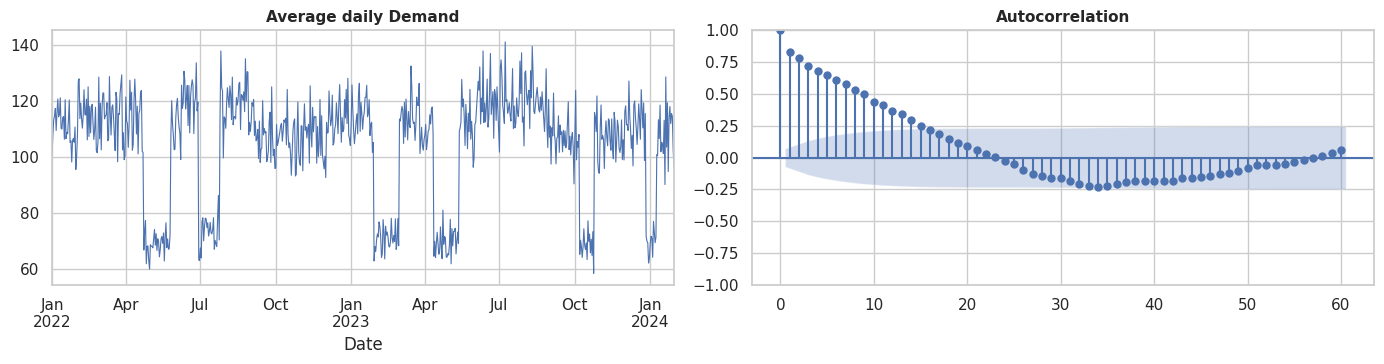

In [20]:
# numeric <-> numeric (Spearman)
rows = []
for a, b in itertools.combinations(NUMERICLIKE, 2):
    r, p = stats.spearmanr(df[a], df[b]); rows.append(dict(var_1=a, var_2=b, spearman_rho=r, p_value=p, relation="DEPENDENT" if p < ALPHA else "independent"))
sp_tbl = pd.DataFrame(rows).sort_values("spearman_rho", key=abs, ascending=False)
display(sp_tbl.head(12))

# independence of observations over time
daily = df.groupby("Date")[TARGET].mean()
lb = acorr_ljungbox(daily, lags=[7, 14, 30], return_df=True)
display(lb)
print("Durbin-Watson of the daily demand series:", round(durbin_watson(daily - daily.mean()), 3), "(2 = no autocorrelation)")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
daily.plot(ax=ax[0], lw=.8); ax[0].set_title("Average daily Demand")
plot_acf(daily, lags=60, ax=ax[1]); plt.tight_layout(); plt.show()

**Conclusion:** rows are *not* a bag of independent samples – the data is a **panel time series** (store × product × day) and demand is time‑dependent. Therefore:
* we create lag / rolling‑demand features (only from the *past*), and
* we use a **time‑based train/test split** and time‑series cross‑validation (no random shuffling – that would leak the future).

### 7.2 Grouping and comparison of means (+ hypothesis tests for numeric **and** categorical variables)
For every grouping variable we choose the test automatically:
* 2 groups → **Welch t‑test** (does not assume equal variance) + **Mann–Whitney U**; effect size **Cohen’s d**
* ≥3 groups → **one‑way ANOVA** + **Kruskal–Wallis**; effect size **η²**
* Categorical vs categorical → **χ² test** + Cramér’s V
* Because we run many tests, p‑values are adjusted with **Holm’s method**.


=== grouped by Category ===


,n,mean_demand,median_demand,std_demand,mean_price,mean_competitor,mean_inventory
Category,,,,,,,
Clothing,12160,112.6197,109.0000,41.0230,71.4507,73.3087,281.2608
Electronics,9120,97.4820,95.0000,40.5579,83.1701,85.1880,288.4688
Furniture,13680,73.5811,72.0000,32.3361,121.4616,124.5599,250.0376
Groceries,30400,120.9764,116.0000,48.3627,51.6559,52.9440,359.9189
Toys,10640,92.6070,92.0000,46.1704,26.9088,27.5819,227.9210



=== grouped by Seasonality ===


,n,mean_demand,median_demand,std_demand,mean_price,mean_competitor,mean_inventory
Seasonality,,,,,,,
Autumn,18200,103.4230,100.0000,41.9749,67.7105,69.4057,297.0144
Spring,18400,97.7031,95.0000,46.0386,66.2244,67.8515,286.6997
Summer,18400,112.8554,107.0000,51.9307,69.2189,71.0102,319.9645
Winter,21000,103.4062,100.0000,46.1744,67.6718,69.3837,298.5626



=== grouped by Weather_Condition ===


,n,mean_demand,median_demand,std_demand,mean_price,mean_competitor,mean_inventory
Weather_Condition,,,,,,,
Cloudy,24360,105.4041,102.0000,46.6454,67.8015,69.4470,300.8848
Rainy,17500,95.1067,92.0000,42.6423,65.4772,67.1484,302.1454
Snowy,11160,94.0458,91.0000,39.5202,65.9727,67.6824,298.7150
Sunny,22980,115.1672,111.0000,51.0928,70.1412,71.9380,299.7101


... (4 outputs left out)


=== grouped by Epidemic ===


,n,mean_demand,median_demand,std_demand,mean_price,mean_competitor,mean_inventory
Epidemic,,,,,,,
0.0000,60800,112.8567,108.0000,44.6395,69.4686,71.2361,311.4607
1.0000,15200,70.1588,64.0000,39.9913,60.6517,62.1144,256.6636



=== grouped by Discount ===


,n,mean_demand,median_demand,std_demand,mean_price,mean_competitor,mean_inventory
Discount,,,,,,,
0.0000,17126,94.7489,92.0000,40.4946,73.0164,74.8150,300.5949
5.0000,16918,94.9419,92.0000,40.8359,68.5107,70.2438,299.7312
10.0000,23298,102.7678,99.0000,45.9507,66.9142,68.5272,301.5951
15.0000,6245,123.5760,120.0000,53.0880,67.0654,68.9605,299.6633
20.0000,6191,124.0653,120.0000,52.9565,63.4462,65.2261,299.0930
25.0000,6222,122.9674,120.0000,52.5583,58.7379,60.2073,300.4838


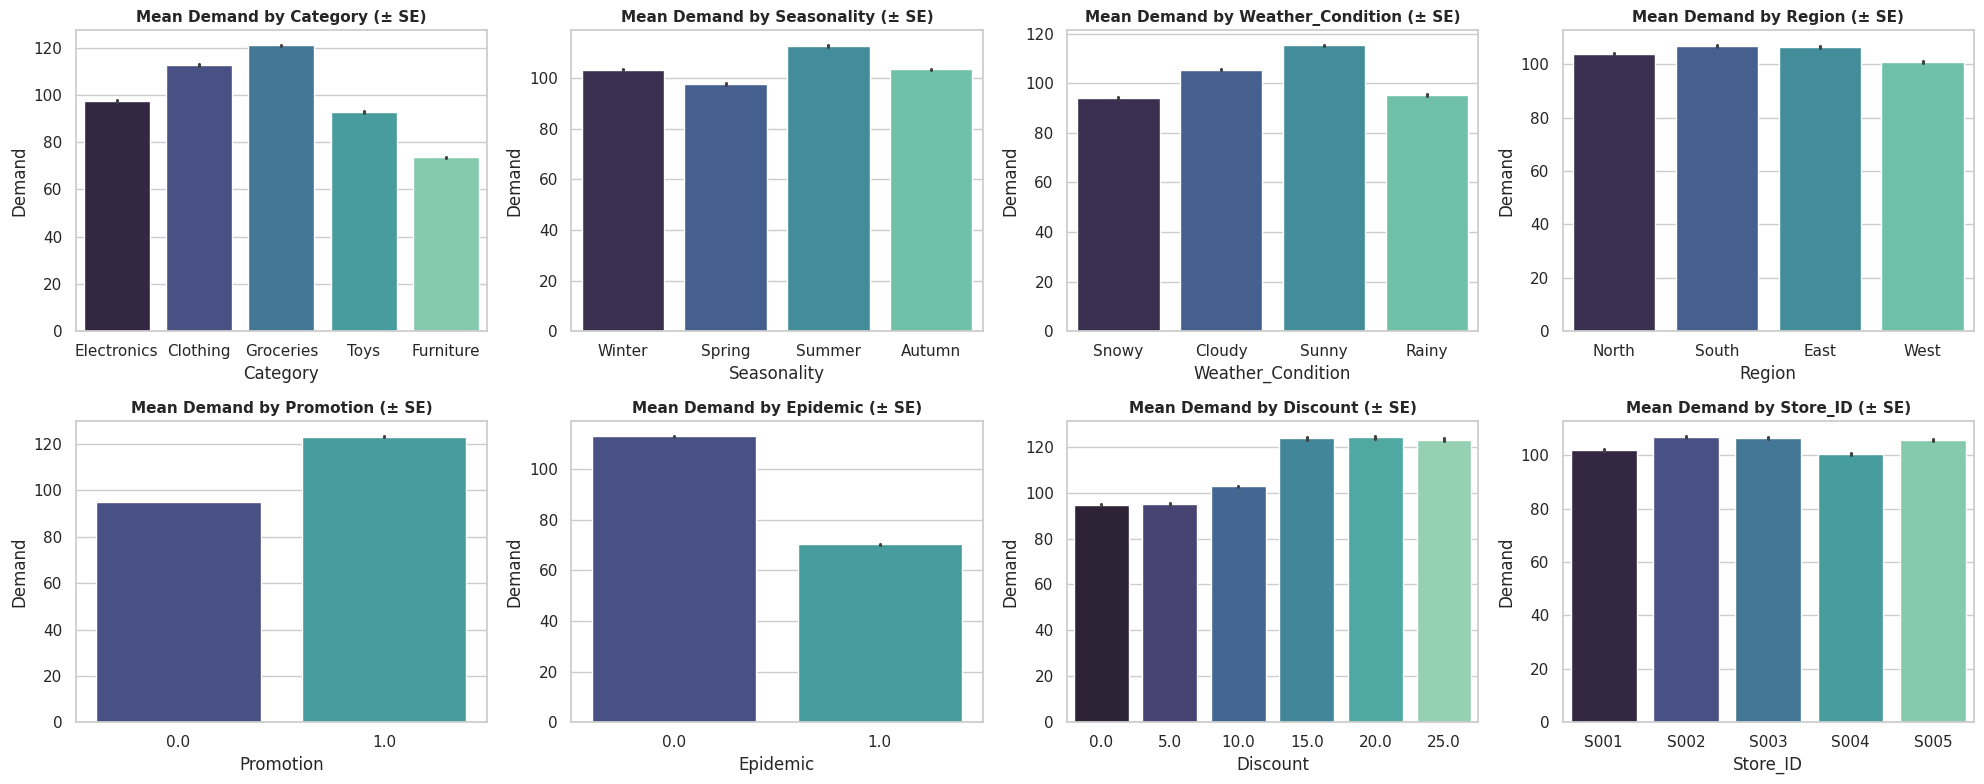

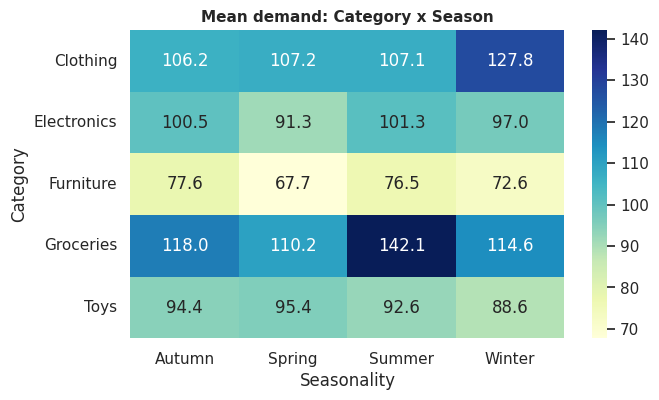

In [21]:
# ---- descriptive group comparison
for g in ["Category", "Seasonality", "Weather_Condition", "Region", "Promotion", "Epidemic", "Discount"]:
    t = df.groupby(g, observed=True).agg(n=(TARGET, "size"), mean_demand=(TARGET, "mean"), median_demand=(TARGET, "median"),
                                          std_demand=(TARGET, "std"), mean_price=("Price", "mean"),
                                          mean_competitor=("Competitor_Pricing", "mean"), mean_inventory=("Inventory_Level", "mean"))
    print(f"\n=== grouped by {g} ==="); display(t)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, g in zip(axes.ravel(), ["Category", "Seasonality", "Weather_Condition", "Region", "Promotion", "Epidemic", "Discount", "Store_ID"]):
    sns.barplot(data=df, x=g, y=TARGET, errorbar="se", ax=ax, palette="mako"); ax.set_title(f"Mean Demand by {g} (± SE)")
plt.tight_layout(); plt.show()

pv = df.pivot_table(index="Category", columns="Seasonality", values=TARGET, aggfunc="mean")
plt.figure(figsize=(7, 4)); sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlGnBu"); plt.title("Mean demand: Category x Season"); plt.show()

In [22]:
def cohen_d(a, b):
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2)); return (a.mean() - b.mean()) / sp

def test_num_by_cat(d, num, cat):
    groups = [g[num].values.astype(float) for _, g in d.groupby(cat, observed=True)]; k = len(groups)
    if k == 2:
        t = stats.ttest_ind(groups[0], groups[1], equal_var=False); u = stats.mannwhitneyu(groups[0], groups[1])
        eff, eff_name, name, stat, p, p2 = abs(cohen_d(pd.Series(groups[0]), pd.Series(groups[1]))), "Cohen d", "Welch t / Mann-Whitney", t.statistic, t.pvalue, u.pvalue
    else:
        f = stats.f_oneway(*groups); kw = stats.kruskal(*groups)
        allv = np.concatenate(groups); ssb = sum(len(g)*(g.mean()-allv.mean())**2 for g in groups)
        eff, eff_name, name, stat, p, p2 = ssb / ((allv - allv.mean())**2).sum(), "eta^2", "ANOVA / Kruskal-Wallis", f.statistic, f.pvalue, kw.pvalue
    return dict(H0=f"mean {num} is equal across {cat} groups", test=name, statistic=stat, p_value=p, p_nonparam=p2, effect=eff, effect_type=eff_name)

hyp = []
for num, cats in {"Demand": ["Promotion", "Epidemic", "Category", "Region", "Seasonality", "Weather_Condition", "Store_ID", "Product_ID", "Discount"],
                  "Price": ["Category", "Promotion"], "Inventory_Level": ["Category", "Store_ID"]}.items():
    for c in cats: hyp.append(test_num_by_cat(df, num, c))

# paired test: are we priced above competitors?
t = stats.ttest_rel(df.Price, df.Competitor_Pricing); w = stats.wilcoxon(df.Price - df.Competitor_Pricing)
hyp.append(dict(H0="mean(Price) = mean(Competitor_Pricing)", test="paired t / Wilcoxon", statistic=t.statistic, p_value=t.pvalue, p_nonparam=w.pvalue,
                effect=(df.Price - df.Competitor_Pricing).mean() / (df.Price - df.Competitor_Pricing).std(), effect_type="Cohen dz"))

# categorical vs categorical
for a, b in [("Promotion", "Category"), ("Promotion", "Seasonality"), ("Epidemic", "Region"), ("Weather_Condition", "Seasonality"), ("Store_ID", "Region"), ("Product_ID", "Category")]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df[a], df[b]))
    hyp.append(dict(H0=f"{a} and {b} are independent", test="chi-square", statistic=chi2, p_value=p, p_nonparam=np.nan, effect=cramers_v(df[a], df[b]), effect_type="Cramer V"))

hyp = pd.DataFrame(hyp)
hyp["p_holm"] = multipletests(hyp.p_value, method="holm")[1]
hyp["decision"] = np.where(hyp.p_holm < ALPHA, "Reject H0", "Fail to reject H0")
display(hyp)

,H0,test,statistic,p_value,p_nonparam,effect,effect_type,p_holm,decision
0,mean Demand is equal across Promotion groups,Welch t / Mann-Whitney,-74.3362,0.0000,0.0000,0.6269,Cohen d,0.0000,Reject H0
1,mean Demand is equal across Epidemic groups,Welch t / Mann-Whitney,114.9423,0.0000,0.0000,0.9760,Cohen d,0.0000,Reject H0
2,mean Demand is equal across Category groups,ANOVA / Kruskal-Wallis,"3,187.5591",0.0000,0.0000,0.1437,eta^2,0.0000,Reject H0
3,mean Demand is equal across Region groups,ANOVA / Kruskal-Wallis,59.0702,0.0000,0.0000,0.0023,eta^2,0.0000,Reject H0
4,mean Demand is equal across Seasonality groups,ANOVA / Kruskal-Wallis,333.5122,0.0000,0.0000,0.0130,eta^2,0.0000,Reject H0
5,mean Demand is equal across Weather_Condition ...,ANOVA / Kruskal-Wallis,842.5558,0.0000,0.0000,0.0322,eta^2,0.0000,Reject H0
6,mean Demand is equal across Store_ID groups,ANOVA / Kruskal-Wallis,57.5770,0.0000,0.0000,0.0030,eta^2,0.0000,Reject H0
7,mean Demand is equal across Product_ID groups,ANOVA / Kruskal-Wallis,151.1219,0.0000,0.0000,0.0364,eta^2,0.0000,Reject H0
8,mean Demand is equal across Discount groups,ANOVA / Kruskal-Wallis,964.7958,0.0000,0.0000,0.0597,eta^2,0.0000,Reject H0
9,mean Price is equal across Category groups,ANOVA / Kruskal-Wallis,"25,557.0093",0.0000,0.0000,0.5736,eta^2,0.0000,Reject H0



Tukey HSD – Demand by Category
      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
   group1      group2   meandiff p-adj  lower    upper   reject
---------------------------------------------------------------
   Clothing Electronics -15.1377   0.0   -16.78 -13.4954   True
   Clothing   Furniture -39.0386   0.0 -40.5162  -37.561   True
   Clothing   Groceries   8.3567   0.0   7.0846   9.6288   True
   Clothing        Toys -20.0128   0.0 -21.5866  -18.439   True
Electronics   Furniture -23.9009   0.0 -25.5036 -22.2982   True
Electronics   Groceries  23.4944   0.0   22.079  24.9099   True
Electronics        Toys  -4.8751   0.0  -6.5669  -3.1833   True
  Furniture   Groceries  47.3953   0.0  46.1747  48.6159   True
  Furniture        Toys  19.0258   0.0  17.4933  20.5583   True
  Groceries        Toys -28.3695   0.0 -29.7049 -27.0341   True
---------------------------------------------------------------

Tukey HSD – Demand by Seasonality
Multiple Comparison of Means - Tukey 

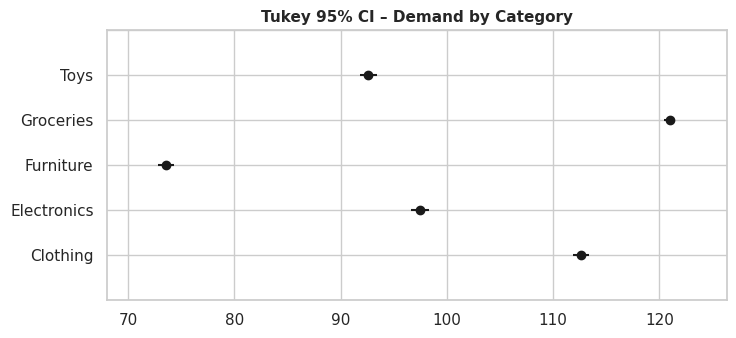

In [23]:
# post-hoc: which groups differ? (Tukey HSD)
for g in ["Category", "Seasonality", "Weather_Condition"]:
    res = pairwise_tukeyhsd(df[TARGET], df[g].astype(str), alpha=ALPHA)
    print(f"\nTukey HSD – Demand by {g}"); print(res.summary())
res = pairwise_tukeyhsd(df[TARGET], df["Category"].astype(str), alpha=ALPHA); res.plot_simultaneous(figsize=(8, 3.5)); plt.title("Tukey 95% CI – Demand by Category"); plt.show()

## 8️⃣ Features, target, leakage and target skewness
### 8.1 Feature engineering (pricing‑specific)
All created from information that is **known before the price is set**:
* **Competitor signals:** `Price_Ratio = Price / Competitor_Pricing`, `Price_Gap`, `Effective_Price` (after discount) and `Eff_Ratio`
* **Demand trend:** yesterday’s demand, demand 7 days ago and 7‑day rolling mean – always **shifted** so they only use the past
* **Price momentum:** day‑over‑day change in our price and in the competitor’s price
* **Calendar:** month, day of week, weekend flag

**v3 additions (all strictly past-only, built with `shift(1)`):**
* **Longer demand memory:** `Demand_Lag14`, `Demand_Roll14`, `Demand_Roll28`, `Demand_Std7`, `Demand_ExpMean` (expanding mean = the series' own typical level), `Demand_EWM`.
* **Price relative to the series' own past price level:** `Price_ExpMean`, `Price_Roll7`, `Price_Roll28` and the ratios `Price_Idx_Exp`, `Price_Idx_7`, `Price_Idx_28` (= today's price / past average price). Raw `Price` mixes cheap and expensive products; the ratio tells the model whether *this* product is priced high or low *for itself* - which is what demand reacts to in this data.


In [24]:
df = df.sort_values(["Store_ID", "Product_ID", "Date"]).reset_index(drop=True)
g = df.groupby(["Store_ID", "Product_ID"], observed=True)

# Lag features assume one row per store-product per consecutive day - verify instead of assuming.
_gaps = g["Date"].diff().dropna().dt.days
if not (_gaps == 1).all():
    print(f"⚠️ {(_gaps != 1).sum()} non-consecutive day gaps found: Demand_Lag1/Lag7 are NOT exact calendar lags for those rows.")
else:
    print("✔ every store-product series is a gap-free daily series, so shift(1)/shift(7) are true 1-/7-day lags")

df["Price_Ratio"]      = df.Price / df.Competitor_Pricing
df["Price_Gap"]        = df.Price - df.Competitor_Pricing
df["Effective_Price"]  = df.Price * (1 - df.Discount / 100)
df["Eff_Ratio"]        = df.Effective_Price / df.Competitor_Pricing

df["Demand_Lag1"]      = g[TARGET].shift(1)
df["Demand_Lag7"]      = g[TARGET].shift(7)
df["Demand_Roll7"]     = g[TARGET].transform(lambda s: s.shift(1).rolling(7).mean())
df["Price_Lag1"]       = g["Price"].shift(1)
df["Price_Change_1d"]  = (df.Price - df.Price_Lag1) / df.Price_Lag1
df["Comp_Change_1d"]   = g["Competitor_Pricing"].transform(lambda s: s.pct_change())

# ---- v3: longer demand memory (past only)
df["Demand_Lag14"]     = g[TARGET].shift(14)
df["Demand_Roll14"]    = g[TARGET].transform(lambda s: s.shift(1).rolling(14).mean())
df["Demand_Roll28"]    = g[TARGET].transform(lambda s: s.shift(1).rolling(28).mean())
df["Demand_Std7"]      = g[TARGET].transform(lambda s: s.shift(1).rolling(7).std())
df["Demand_ExpMean"]   = g[TARGET].transform(lambda s: s.shift(1).expanding().mean())     # the series' own typical demand level
df["Demand_EWM"]       = g[TARGET].transform(lambda s: s.shift(1).ewm(alpha=0.3).mean())

# ---- v3: today's price relative to this series' OWN past price level (past only in the denominator)
df["Price_ExpMean"]    = g["Price"].transform(lambda s: s.shift(1).expanding().mean())
df["Price_Roll7"]      = g["Price"].transform(lambda s: s.shift(1).rolling(7).mean())
df["Price_Roll28"]     = g["Price"].transform(lambda s: s.shift(1).rolling(28).mean())
df["Price_Idx_Exp"]    = df.Price / df.Price_ExpMean
df["Price_Idx_7"]      = df.Price / df.Price_Roll7
df["Price_Idx_28"]     = df.Price / df.Price_Roll28

df["Month"]     = df.Date.dt.month
df["DayOfWeek"] = df.Date.dt.dayofweek
df["Is_Weekend"] = (df.DayOfWeek >= 5).astype(int)

# rows are only usable when ALL history features exist (the same list is reused by the Pipeline in section 12.4)
HIST_REQUIRED = ["Demand_Lag7", "Demand_Roll7", "Price_Change_1d", "Comp_Change_1d",
                 "Demand_Lag14", "Demand_Roll14", "Demand_Roll28", "Demand_Std7", "Price_Roll28"]
n0 = len(df); df = df.dropna(subset=HIST_REQUIRED).sort_values(["Date", "Store_ID", "Product_ID"]).reset_index(drop=True)
print(f"Dropped first days of each series (no history yet): {n0-len(df)} rows | remaining {len(df):,}")

✔ every store-product series is a gap-free daily series, so shift(1)/shift(7) are true 1-/7-day lags
Dropped first days of each series (no history yet): 2800 rows | remaining 73,200


### 8.2 Leakage check
A feature is **leaky** if it contains target information unavailable when the price is set, or is almost a copy of the target. We assess suspect fields using business logic and correlation only; post-outcome fields are not used to fit a diagnostic model.


In [25]:
raw_candidates = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Price", "Competitor_Pricing", "Discount", "Promotion", "Epidemic"]
leak_tbl = pd.DataFrame({"corr_with_target": df[raw_candidates].corrwith(df[TARGET])}).sort_values(
    "corr_with_target", key=lambda s: s.abs(), ascending=False
)
leak_tbl["statistical_flag"] = np.where(leak_tbl.corr_with_target.abs() > .8, "SUSPECT", "-")
display(leak_tbl)

print("Units_Sold <= Demand in", f"{(df.Units_Sold <= df.Demand).mean():.1%}", "of rows;",
      "corr(Units_Sold, min(Demand, Inventory)) =", round(np.corrcoef(df.Units_Sold, np.minimum(df.Demand, df.Inventory_Level))[0, 1], 3))

,corr_with_target,statistical_flag
Units_Sold,0.8359,SUSPECT
Units_Ordered,0.5073,-
Epidemic,-0.3687,-
Promotion,0.2800,-
Discount,0.2224,-
Inventory_Level,0.1306,-
Competitor_Pricing,-0.0241,-
Price,-0.0241,-


Units_Sold <= Demand in 72.8% of rows; corr(Units_Sold, min(Demand, Inventory)) = 0.914


In [26]:
# ---- handle leakage: drop leaky + redundant columns
LEAKY      = ["Units_Sold", "Units_Ordered"]
REDUNDANT  = ["Region", "Seasonality"]
print("Dropping leaky   :", LEAKY); print("Dropping redundant:", REDUNDANT)

Dropping leaky   : ['Units_Sold', 'Units_Ordered']
Dropping redundant: ['Region', 'Seasonality']


### 8.3 Final feature set (multicollinearity re‑check)
We recompute VIF on the engineered numeric features and prune iteratively, keeping the pricing signals the engine actually needs (`Price`, `Price_Ratio`, `Discount`).

In [27]:
NUM_CAND = [
    "Inventory_Level", "Price", "Competitor_Pricing", "Discount", "Promotion", "Epidemic",
    "Price_Ratio", "Price_Gap", "Effective_Price", "Eff_Ratio", "Demand_Lag1", "Demand_Lag7",
    "Demand_Roll7", "Price_Change_1d", "Comp_Change_1d", "Month", "DayOfWeek", "Is_Weekend",
    "Demand_Lag14", "Demand_Roll14", "Demand_Roll28", "Demand_Std7", "Demand_ExpMean", "Demand_EWM",
    "Price_ExpMean", "Price_Roll7", "Price_Roll28", "Price_Idx_Exp", "Price_Idx_7", "Price_Idx_28",
]
if EXCLUDE_PRICE_PROXY:
    NUM_CAND = [f for f in NUM_CAND if f not in PRICE_PROXY]
    print("Price-proxy features removed:", PRICE_PROXY)
NUM_FEATS = NUM_CAND.copy()
CAT_FEATS = ["Category", "Weather_Condition", "Store_ID", "Product_ID"]
FEATURES = NUM_FEATS + CAT_FEATS
FORBIDDEN_FEATURES = {TARGET, "Units_Sold", "Units_Ordered"}
leaked_features = sorted(FORBIDDEN_FEATURES.intersection(FEATURES))
if leaked_features:
    raise ValueError(f"Post-outcome/target columns cannot be model features: {leaked_features}")
for c in CAT_FEATS:
    df[c] = df[c].astype(str)
print(f"Candidate features before the one CV pruning pass: {len(FEATURES)}")

Price-proxy features removed: ['Price_ExpMean', 'Price_Roll7', 'Price_Roll28', 'Price_Idx_Exp', 'Price_Idx_7', 'Price_Idx_28', 'Price_Change_1d', 'Comp_Change_1d']
Candidate features before the one CV pruning pass: 26


### 8.3 Candidate feature set

Create the available predictors here. Section 9.0 performs the single supervised feature-selection step using chronological CV on training data only; the untouched hold-out is not used to select features.

Train: 2022-01-29 -> 2023-08-31  (58,000 rows)
Test : 2023-09-01 -> 2024-01-30  (15,200 rows)
Training demand: min 4 | max 430 | range 426 | mean 105.0  ->  MAE/RMSE are divided by the range 426


,skewness,excess_kurtosis
none,0.6267,0.7212
log1p,-1.0810,2.1969
sqrt,-0.1318,0.1261
box-cox,-0.0018,0.0865
yeo-johnson,-0.0021,0.0793


Target skewness (train) = 0.627  ->  lowest-skew candidate: box-cox (skew -0.002)
ℹ️ Skewness only PRE-SELECTS a candidate. The transform actually used is chosen in section 9.1 by cross-validated MAE in real demand units.


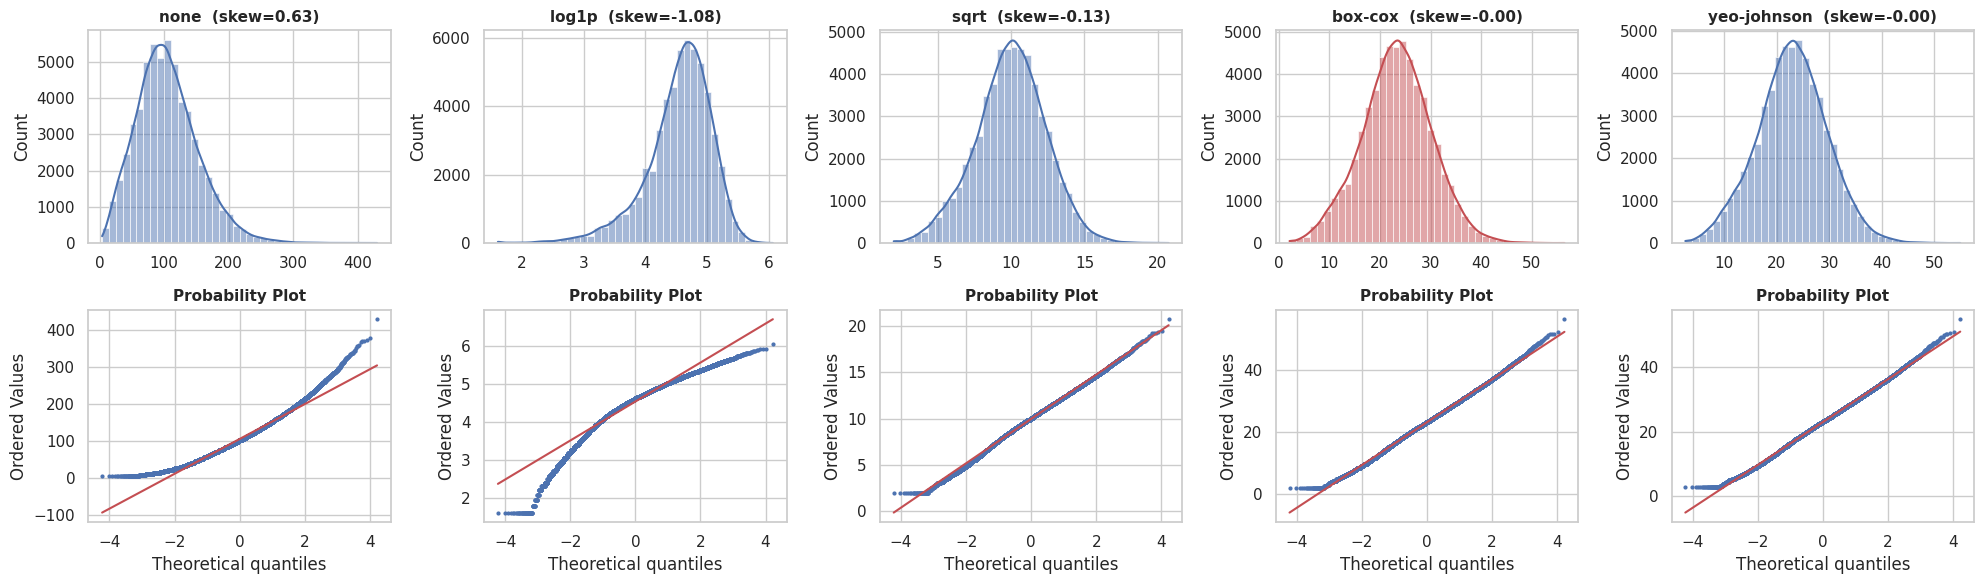

In [28]:
# ---- time-based split (the data is a time series -> no shuffling)
cut = CUT_DATE
train = df[df.Date < cut].copy(); test = df[df.Date >= cut].copy()
X_train, y_train, X_test, y_test = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
print(f"Train: {train.Date.min().date()} -> {train.Date.max().date()}  ({len(train):,} rows)")
print(f"Test : {test.Date.min().date()} -> {test.Date.max().date()}  ({len(test):,} rows)")

# ---- v3: constants for the 0-1 metric scale (learned from the TRAINING period only)
Y_MIN, Y_MAX = float(y_train.min()), float(y_train.max())
Y_RANGE = Y_MAX - Y_MIN
print(f"Training demand: min {Y_MIN:.0f} | max {Y_MAX:.0f} | range {Y_RANGE:.0f} | mean {y_train.mean():.1f}  ->  MAE/RMSE are divided by the range {Y_RANGE:.0f}")

from sklearn.preprocessing import FunctionTransformer, PowerTransformer
def make_target_tf(name):
    if name == "none":     return FunctionTransformer(validate=False)
    if name == "log1p":    return FunctionTransformer(np.log1p, np.expm1, validate=False, check_inverse=False)
    if name == "sqrt":     return FunctionTransformer(np.sqrt, np.square, validate=False, check_inverse=False)
    if name == "box-cox":  return PowerTransformer(method="box-cox", standardize=False)
    if name == "yeo-johnson": return PowerTransformer(method="yeo-johnson", standardize=False)

cands = ["none", "log1p", "sqrt", "box-cox", "yeo-johnson"]
sk = {}
for n in cands:
    tf = make_target_tf(n); t = tf.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    sk[n] = dict(skewness=stats.skew(t), excess_kurtosis=stats.kurtosis(t))
sk = pd.DataFrame(sk).T; display(sk)
TARGET_TF_NAME = sk["skewness"].abs().idxmin()
print(f"Target skewness (train) = {sk.loc['none','skewness']:.3f}  ->  lowest-skew candidate: {TARGET_TF_NAME} (skew {sk.loc[TARGET_TF_NAME,'skewness']:.3f})")
print("ℹ️ Skewness only PRE-SELECTS a candidate. The transform actually used is chosen in section 9.1 by cross-validated MAE in real demand units.")

fig, axes = plt.subplots(2, 5, figsize=(20, 6))
for i, n in enumerate(cands):
    t = make_target_tf(n).fit_transform(y_train.values.reshape(-1, 1)).ravel()
    sns.histplot(t, kde=True, ax=axes[0, i], bins=40, color="#C44E52" if n == TARGET_TF_NAME else "#4C72B0"); axes[0, i].set_title(f"{n}  (skew={stats.skew(t):.2f})")
    stats.probplot(t, dist="norm", plot=axes[1, i]); axes[1, i].get_lines()[0].set_markersize(2)
plt.tight_layout(); plt.show()

### 8.4b Feature-group ablation (added): which features create the high R²?
Adds ONE feature group at a time to a base set and reports hold-out R² (fast LightGBM, trained on the training period only). Use it to decide which groups are legitimate, instead of removing everything.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score
from lightgbm import LGBMRegressor
GROUPS = {
 "Context (Discount, Promotion, Epidemic, Inventory, Month, DayOfWeek, Is_Weekend)": ["Discount","Promotion","Epidemic","Inventory_Level","Month","DayOfWeek","Is_Weekend"],
 "Demand history (lags, rolling, EWM, expanding mean)": ["Demand_Lag1","Demand_Lag7","Demand_Lag14","Demand_Roll7","Demand_Roll14","Demand_Roll28","Demand_Std7","Demand_ExpMean","Demand_EWM"],
 "Raw price level (Price, Competitor_Pricing, Effective_Price)": ["Price","Competitor_Pricing","Effective_Price"],
 "Competitor-relative price (Ratio, Gap, Eff_Ratio)": ["Price_Ratio","Price_Gap","Eff_Ratio"],
 "Own-price history (Price_ExpMean/Roll/Idx, Price_Change_1d, Comp_Change_1d)": ["Price_ExpMean","Price_Roll7","Price_Roll28","Price_Idx_Exp","Price_Idx_7","Price_Idx_28","Price_Change_1d","Comp_Change_1d"],
}
CATS = ["Category","Weather_Condition","Store_ID","Product_ID"]
def quick_r2(num, cat=CATS):
    cols = num + cat
    pre = ColumnTransformer([("num","passthrough",num),("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),cat)])
    m = Pipeline([("p",pre),("m",LGBMRegressor(n_estimators=300,learning_rate=0.05,num_leaves=31,min_child_samples=50,random_state=RANDOM_STATE,n_jobs=-1,verbose=-1))]).fit(train[cols],train[TARGET])
    return r2_score(test[TARGET], m.predict(test[cols]))
base = GROUPS[list(GROUPS)[0]] + GROUPS[list(GROUPS)[1]]
rows = [dict(feature_set="BASE: context + demand history", holdout_R2=quick_r2(base))]
for name in list(GROUPS)[2:]:
    rows.append(dict(feature_set="BASE + " + name, holdout_R2=quick_r2(base + GROUPS[name])))
rows.append(dict(feature_set="BASE + raw price + competitor-relative", holdout_R2=quick_r2(base + GROUPS[list(GROUPS)[2]] + GROUPS[list(GROUPS)[3]])))
rows.append(dict(feature_set="ALL groups", holdout_R2=quick_r2(sum(GROUPS.values(), []))))
abl = pd.DataFrame(rows).set_index("feature_set"); display(abl)
print("A group that lifts R2 from ~0.5 to ~0.99 on its own is carrying the 'current demand' signal.")

,holdout_R2
feature_set,
BASE: context + demand history,0.4311
"BASE + Raw price level (Price, Competitor_Pricing, Effective_Price)",0.7871
"BASE + Competitor-relative price (Ratio, Gap, Eff_Ratio)",0.5454
"BASE + Own-price history (Price_ExpMean/Roll/Idx, Price_Change_1d, Comp_Change_1d)",0.9801
BASE + raw price + competitor-relative,0.7850
ALL groups,0.9978


A group that lifts R2 from ~0.5 to ~0.99 on its own is carrying the 'current demand' signal.


In [30]:
import optuna
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

def preprocessor():
    return ColumnTransformer([("num", StandardScaler(), NUM_FEATS),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS)])

# Search spaces are deliberately bounded (shallow trees, large leaves, modest learning rates) so the tuner
# cannot drift into very flexible models that memorise the training period.
# v3: ranges were widened a little (more trees / leaves) because the new price-vs-history features carry a sharp signal that needs some capacity;
#     the train->validation gap penalty in the objective still protects against memorisation.
def suggest_params(name, t):
    if name == "ElasticNet":
        return dict(alpha=t.suggest_float("alpha", 1e-5, 10, log=True), l1_ratio=t.suggest_float("l1_ratio", 0.0, 1.0))

    if name == "LinearRegression":
        return {}                                                   # nothing to tune

    if name == "RandomForest":                                      # slow: bounded and small on purpose
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 300, step=50), max_depth=t.suggest_int("max_depth", 8, 40),                     # deep trees allowed: this data has a sharp, low-noise structure
                    min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 30), max_features=t.suggest_float("max_features", 0.5, 1.0))

    if name == "XGBoost":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 800, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.15, log=True),
                    max_depth=t.suggest_int("max_depth", 3, 10), subsample=t.suggest_float("subsample", 0.5, 1.0),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0), min_child_weight=t.suggest_int("min_child_weight", 1, 60),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-3, 20, log=True), reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10, log=True))
    if name == "LightGBM":
        return dict(n_estimators=t.suggest_int("n_estimators", 100, 800, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.15, log=True),
                    num_leaves=t.suggest_int("num_leaves", 4, 128), min_child_samples=t.suggest_int("min_child_samples", 5, 300),
                    subsample=t.suggest_float("subsample", 0.5, 1.0), colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-3, 20, log=True), reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10, log=True))

def make_estimator(name, p):
    if name == "ElasticNet":           reg = ElasticNet(max_iter=5000, random_state=RANDOM_STATE, **p)

    elif name == "LinearRegression":   reg = LinearRegression(**p)

    elif name == "RandomForest":       reg = RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE, **p)

    elif name == "XGBoost":            reg = XGBRegressor(tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, verbosity=0, **p)
    elif name == "LightGBM":           reg = LGBMRegressor(subsample_freq=1, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1, **p)

    pipe = Pipeline([("prep", preprocessor()), ("model", reg)])
    return TransformedTargetRegressor(regressor=pipe, transformer=make_target_tf(TARGET_TF_NAME))   # trains on transformed target, predicts in real units

MODEL_NAMES = ["LinearRegression", "ElasticNet", "RandomForest", "XGBoost", "LightGBM"]
SLOW_MODELS = {"RandomForest"}
def trials_for(name):
    return 1 if name == "LinearRegression" else (N_TRIALS_SLOW if name in SLOW_MODELS else N_TRIALS)

# Keep all records from a calendar date in the same validation fold.
def date_grouped_splits(frame, n_splits, val_days=None):
    """Chronological folds on whole dates. v4: fixed validation window (val_days) so the earliest fold still has a long training history."""
    val_days = CV_VAL_DAYS if val_days is None else val_days
    date_values = pd.to_datetime(frame["Date"]).to_numpy()
    unique_dates = np.unique(date_values)
    if len(unique_dates) <= n_splits:
        raise ValueError(f"Need more than {n_splits} unique dates for chronological CV.")
    date_codes = np.searchsorted(unique_dates, date_values)
    splits = []
    use_window = bool(val_days) and len(unique_dates) >= n_splits * val_days + 120      # keep >= 120 training days in the first fold, else fall back
    ts = TimeSeriesSplit(n_splits=n_splits, test_size=val_days) if use_window else TimeSeriesSplit(n_splits=n_splits)
    for train_dates, valid_dates in ts.split(unique_dates):
        train_idx = np.flatnonzero(np.isin(date_codes, train_dates))
        valid_idx = np.flatnonzero(np.isin(date_codes, valid_dates))
        if not len(train_idx) or not len(valid_idx):
            raise ValueError("A chronological CV fold has an empty train or validation set.")
        splits.append((train_idx, valid_idx))
    return splits

# Use all training rows when TUNE_SAMPLE is None; folds split on whole dates.
tune = train.sample(min(TUNE_SAMPLE, len(train)), random_state=RANDOM_STATE) if TUNE_SAMPLE else train
tune = tune.sort_values("Date"); X_tune, y_tune = tune[FEATURES], tune[TARGET]
cv = date_grouped_splits(tune, CV_FOLDS)
print(f"Tuning rows: {len(tune):,} | CV: {CV_FOLDS} expanding date folds, {CV_VAL_DAYS}-day validation windows | target transform: {TARGET_TF_NAME}")
print("Training days per fold:", [int(pd.to_datetime(tune.Date.iloc[a]).nunique()) for a, _ in cv], "| validation rows per fold:", [len(b) for _, b in cv])
# v4: scale of the problem = error of the best naive forecast on the tuning rows; gaps are judged against it
NAIVE_TUNE_MAE = float(min(mean_absolute_error(y_tune, tune.Demand_Lag1), mean_absolute_error(y_tune, tune.Demand_Roll7)))
print(f"Naive-baseline MAE on tuning rows: {NAIVE_TUNE_MAE:.2f}  (GAP_TOL = {GAP_TOL:.0%} of this = {GAP_TOL * NAIVE_TUNE_MAE:.2f} demand units)")

from sklearn.base import clone
from optuna.exceptions import TrialPruned

def make_objective(name):
    """CV objective = validation MAE, penalised when the train->validation gap says the model is memorising.
    Folds are run manually so that (a) train error is measured, (b) hopeless trials are pruned early."""
    def objective(trial):
        est = make_estimator(name, suggest_params(name, trial))
        rng = np.random.default_rng(RANDOM_STATE)
        va_mae, tr_mae, va_mape, va_rmse, va_r2, va_wape = [], [], [], [], [], []
        for step, (tr_idx, va_idx) in enumerate(cv):
            m = clone(est).fit(X_tune.iloc[tr_idx], y_tune.iloc[tr_idx])
            y_va, p_va = y_tune.iloc[va_idx].values.astype(float), m.predict(X_tune.iloc[va_idx])
            sub = tr_idx if len(tr_idx) <= 15000 else np.sort(rng.choice(tr_idx, 15000, replace=False))   # subsample only to save time
            y_tr, p_tr = y_tune.iloc[sub].values.astype(float), m.predict(X_tune.iloc[sub])
            va_mae.append(mean_absolute_error(y_va, p_va)); tr_mae.append(mean_absolute_error(y_tr, p_tr))
            pos = y_va > 0
            va_mape.append(float(np.mean(np.abs(y_va[pos] - p_va[pos]) / y_va[pos])))
            va_rmse.append(float(np.sqrt(mean_squared_error(y_va, p_va)))); va_r2.append(r2_score(y_va, p_va)); va_wape.append(float(np.abs(y_va - p_va).sum() / np.abs(y_va).sum()))
            trial.report(float(np.mean(va_mae)), step)
            if trial.should_prune():
                raise TrialPruned()
        v, t_ = float(np.mean(va_mae)), float(np.mean(tr_mae))
        gap = max(0.0, (v - t_) / v)                                   # relative gap (kept for display)
        gap_naive = max(0.0, v - t_) / NAIVE_TUNE_MAE                  # v4: scale-aware gap used for the penalty
        trial.set_user_attr("cv_mae", v); trial.set_user_attr("train_mae", t_); trial.set_user_attr("gap", gap)
        trial.set_user_attr("gap_naive", gap_naive); trial.set_user_attr("cv_mae_std", float(np.std(va_mae))); trial.set_user_attr("cv_mae_worst", float(np.max(va_mae)))
        trial.set_user_attr("cv_mape", float(np.mean(va_mape))); trial.set_user_attr("cv_mape_pct", 100 * float(np.mean(va_mape)))
        trial.set_user_attr("cv_rmse", float(np.mean(va_rmse)))
        trial.set_user_attr("cv_r2", float(np.mean(va_r2)))
        # v3: the same CV scores on the 0-1 scale
        trial.set_user_attr("cv_mae_01", v / Y_RANGE); trial.set_user_attr("cv_rmse_01", float(np.mean(va_rmse)) / Y_RANGE)
        trial.set_user_attr("cv_wape", float(np.mean(va_wape)))
        return v * (1.0 + GAP_PENALTY * max(0.0, gap_naive - GAP_TOL))      # penalised MAE
    return objective


Tuning rows: 58,000 | CV: 4 expanding date folds, 60-day validation windows | target transform: box-cox
Training days per fold: [340, 400, 460, 520] | validation rows per fold: [6000, 6000, 6000, 6000]
Naive-baseline MAE on tuning rows: 32.28  (GAP_TOL = 3% of this = 0.97 demand units)


All 26 candidate features: CV MAE 10.054


,n_features,dropped,cv_mae,vs_all_features
0,26,-,10.0542,0.0000
1,25,Demand_Std7,10.0091,-0.0045
2,24,DayOfWeek,10.0944,0.0040
3,23,Is_Weekend,10.1090,0.0054
4,22,Epidemic,9.8139,-0.0239
5,21,Month,9.7819,-0.0271
6,20,Demand_Lag14,9.6173,-0.0435
7,19,Demand_Lag7,9.6235,-0.0428
8,18,Demand_Lag1,9.6490,-0.0403
9,17,Inventory_Level,9.5331,-0.0518


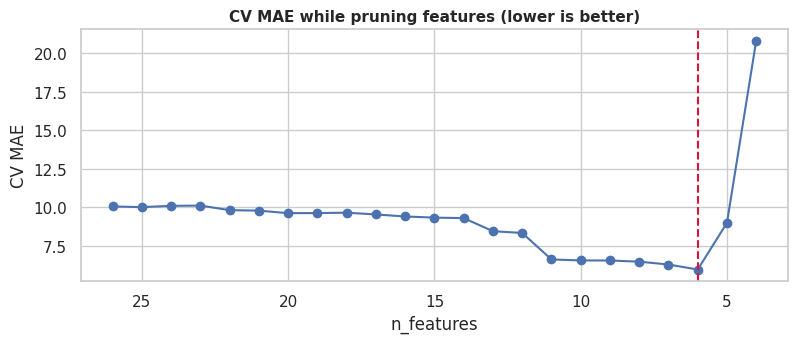

16 original columns -> 26 candidate features -> 6 kept (CV MAE 5.957 vs 10.054 with all)
Kept   : ['Price', 'Competitor_Pricing', 'Discount', 'Category', 'Store_ID', 'Product_ID']
Dropped: ['Inventory_Level', 'Promotion', 'Epidemic', 'Price_Ratio', 'Price_Gap', 'Effective_Price', 'Eff_Ratio', 'Demand_Lag1', 'Demand_Lag7', 'Demand_Roll7', 'Month', 'DayOfWeek', 'Is_Weekend', 'Demand_Lag14', 'Demand_Roll14', 'Demand_Roll28', 'Demand_Std7', 'Demand_ExpMean', 'Demand_EWM', 'Weather_Condition']


In [31]:
NUM_FEATS_ALL, CAT_FEATS_ALL = list(NUM_FEATS), list(CAT_FEATS)           # candidates before pruning (kept for the ablation in 10.0b)

if FEATURE_PRUNE:
    from lightgbm import LGBMRegressor
    from sklearn.inspection import permutation_importance

    def _proxy(num, cat):
        parts = [("num", "passthrough", num)]
        if cat: parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
        return Pipeline([("prep", ColumnTransformer(parts)),
                         ("m", LGBMRegressor(n_estimators=300, learning_rate=0.08, num_leaves=63, min_child_samples=20,
                                             random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))])

    def prune_cv_mae(num, cat):
        cols, scores = num + cat, []
        for tr_idx, va_idx in cv:
            m = _proxy(num, cat).fit(X_tune.iloc[tr_idx][cols], y_tune.iloc[tr_idx])
            scores.append(mean_absolute_error(y_tune.iloc[va_idx], m.predict(X_tune.iloc[va_idx][cols])))
        return float(np.mean(scores))

    all_cols = NUM_FEATS_ALL + CAT_FEATS_ALL
    base_cv = prune_cv_mae(NUM_FEATS_ALL, CAT_FEATS_ALL)
    a, b = cv[-1]                                                              # importance is measured on the most recent fold
    m_imp = _proxy(NUM_FEATS_ALL, CAT_FEATS_ALL).fit(X_tune.iloc[a][all_cols], y_tune.iloc[a])
    pi = permutation_importance(m_imp, X_tune.iloc[b][all_cols], y_tune.iloc[b], scoring="neg_mean_absolute_error", n_repeats=3, random_state=RANDOM_STATE)
    importance = pd.Series(pi.importances_mean, all_cols).sort_values()        # least important first
    print(f"All {len(all_cols)} candidate features: CV MAE {base_cv:.3f}")

    steps, kept = [dict(n_features=len(all_cols), dropped="-", cv_mae=base_cv)], list(all_cols)
    for f in importance.index[:-3]:                                            # always keep at least 3 features
        kept = [c for c in kept if c != f]
        s = prune_cv_mae([c for c in kept if c in NUM_FEATS_ALL], [c for c in kept if c in CAT_FEATS_ALL])
        steps.append(dict(n_features=len(kept), dropped=f, cv_mae=s))
        if s > 1.5 * base_cv: break                                            # a vital feature was just removed - stop walking
    steps = pd.DataFrame(steps); steps["vs_all_features"] = steps.cv_mae / base_cv - 1
    ok = steps[steps.cv_mae <= steps.cv_mae.min() * (1 + FEATURE_PRUNE_TOL)]
    n_keep = int(ok.n_features.min())
    if FEATURE_PRUNE_FORCE_N: n_keep = int(min(max(FEATURE_PRUNE_FORCE_N, steps.n_features.min()), len(all_cols)))   # manual override
    drop_order = list(steps.dropped[1:])
    keep_set = [c for c in all_cols if c not in drop_order[:len(all_cols) - n_keep]]
    NUM_FEATS = [c for c in NUM_FEATS_ALL if c in keep_set]
    CAT_FEATS = [c for c in CAT_FEATS_ALL if c in keep_set]
    FEATURES  = NUM_FEATS + CAT_FEATS
    X_train, X_test, X_tune = train[FEATURES], test[FEATURES], tune[FEATURES]

    display(steps)
    ax = steps.plot(x="n_features", y="cv_mae", marker="o", figsize=(8, 3.6), legend=False, title="CV MAE while pruning features (lower is better)")
    ax.axvline(n_keep, color="crimson", ls="--"); ax.set_ylabel("CV MAE"); ax.invert_xaxis(); plt.tight_layout(); plt.show()
    print(f"{df_raw.shape[1]} original columns -> {len(all_cols)} candidate features -> {len(FEATURES)} kept "
          f"(CV MAE {steps.set_index('n_features').cv_mae[n_keep]:.3f} vs {base_cv:.3f} with all)")
    print("Kept   :", FEATURES)
    print("Dropped:", [c for c in all_cols if c not in FEATURES])
else:
    print("FEATURE_PRUNE = False -> all", len(FEATURES), "features are used")

In [32]:
# 9.1  Choose the target transform by what actually matters: cross-validated MAE in REAL demand units.
#      (Skewness is only a proxy; with a mild skew like 0.47 the raw target is often just as good.)
probe = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8,
             colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=0.1)
tf_scores = {}
for cand in ["none", "sqrt", "yeo-johnson"]:
    TARGET_TF_NAME = cand
    est = make_estimator("LightGBM", probe)
    r = cross_validate(est, X_tune, y_tune, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1)
    tf_scores[cand] = -r["test_score"].mean()
tf_tbl = pd.Series(tf_scores, name="CV MAE (real units)").to_frame(); display(tf_tbl)

best_tf = tf_tbl["CV MAE (real units)"].idxmin()
# parsimony: keep the raw target unless a transform improves CV MAE by more than 1 %
TARGET_TF_NAME = best_tf if tf_scores[best_tf] < 0.99 * tf_scores["none"] else "none"
print(f"✅ Target transform used for all models: {TARGET_TF_NAME}")

,CV MAE (real units)
none,13.1931
sqrt,13.3335
yeo-johnson,13.3124


✅ Target transform used for all models: none


In [33]:
# Feature-count audit (needs FEATURES, X_train and preprocessor() from the cells above).
print("Original columns:", df_raw.shape[1])
print("Engineered dataframe columns:", df.shape[1])
print("Selected features before encoding:", len(FEATURES))
print("Numeric selected:", len(NUM_FEATS))
print("Categorical selected:", len(CAT_FEATS))
print("Selected feature names:", FEATURES)

if len(FEATURES) != len(set(FEATURES)):
    raise ValueError("FEATURES contains duplicate names.")
missing_features = sorted(set(FEATURES) - set(df.columns))
if missing_features:
    raise ValueError(f"Features missing from dataframe: {missing_features}")

# Fit only on the training data to report the actual encoded width.
# This is an audit only; the model pipeline should still fit preprocessing inside each CV fold.
audit_preprocessor = preprocessor()
audit_preprocessor.fit(X_train)
print("Actual encoded model-input columns:", len(audit_preprocessor.get_feature_names_out()))

Original columns: 16
Engineered dataframe columns: 41
Selected features before encoding: 6
Numeric selected: 3
Categorical selected: 3
Selected feature names: ['Price', 'Competitor_Pricing', 'Discount', 'Category', 'Store_ID', 'Product_ID']
Actual encoded model-input columns: 33


In [34]:

studies, summary = {}, []

def _n_done(study):
    return sum(
        t.state in (optuna.trial.TrialState.COMPLETE,
                    optuna.trial.TrialState.PRUNED)
        for t in study.trials
    )

for name in MODEL_NAMES:
    started = time.time()

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=8,
            n_warmup_steps=1
        ),
        study_name=f"{name}_v6",
        storage=OPTUNA_DB,
        load_if_exists=True
    )

    remaining = max(0, trials_for(name) - _n_done(study))

    if remaining:
        study.optimize(
            make_objective(name),
            n_trials=remaining,
            show_progress_bar=False
        )

    complete_trials = [
        t for t in study.trials
        if t.state == optuna.trial.TrialState.COMPLETE
    ]

    if not complete_trials:
        raise RuntimeError(
            f"No completed Optuna trial for {name}. "
            "Check failed/pruned trials and objective errors."
        )

    studies[name] = study
    best = study.best_trial

    summary.append(dict(
        model=name,
        trials=len(study.trials),
        complete=sum(t.state.name == "COMPLETE" for t in study.trials),
        pruned=sum(t.state.name == "PRUNED" for t in study.trials),
        penalized_objective=best.value,
        cv_mae=best.user_attrs["cv_mae"],
        cv_mae_01=best.user_attrs["cv_mae_01"],
        cv_rmse=best.user_attrs["cv_rmse"],
        cv_rmse_01=best.user_attrs["cv_rmse_01"],
        cv_mape=best.user_attrs["cv_mape"],
        cv_wape=best.user_attrs["cv_wape"],
        cv_r2=best.user_attrs["cv_r2"],
        train_mae=best.user_attrs["train_mae"],
        gap_naive=best.user_attrs["gap_naive"],
        cv_mae_std=best.user_attrs["cv_mae_std"],
        minutes=(time.time() - started) / 60
    ))

stage1 = pd.DataFrame(summary).set_index("model")

print("First-pass chronological CV results:")
display(
    stage1[
        ["trials", "complete", "pruned", "cv_mae_01",
         "cv_rmse_01", "cv_mape", "cv_wape", "cv_r2",
         "gap_naive", "cv_mae_std"]
    ].sort_values("cv_mae_01")
)


First-pass chronological CV results:


,trials,complete,pruned,cv_mae_01,cv_rmse_01,cv_mape,cv_wape,cv_r2,gap_naive,cv_mae_std
model,,,,,,,,,,
LightGBM,50,47,3,0.0080,0.0147,0.0521,0.0330,0.9832,0.0387,0.0925
XGBoost,50,47,3,0.0087,0.0148,0.0530,0.0358,0.9829,0.0365,0.0652
RandomForest,30,22,8,0.0111,0.0225,0.0760,0.0461,0.9608,0.0957,0.2680
LinearRegression,1,1,0,0.0762,0.0974,0.4911,0.3147,0.2627,0.0558,0.8274
ElasticNet,50,27,23,0.0762,0.0974,0.4911,0.3147,0.2627,0.0558,0.8274


In [35]:
selection = stage1.copy()
metric_columns = {
    "MAE (0-1)": ("cv_mae_01", True),
    "RMSE (0-1)": ("cv_rmse_01", True),
    "MAPE": ("cv_mape", True),
    "WAPE": ("cv_wape", True),
    "R2": ("cv_r2", False),
}
rank_columns = []
for label, (column, lower_is_better) in metric_columns.items():
    rank_column = f"rank_{column}"
    selection[rank_column] = selection[column].rank(method="average", ascending=lower_is_better)
    rank_columns.append(rank_column)
selection["mean_metric_rank"] = selection[rank_columns].mean(axis=1)
selection["risk_adjusted_mae_01"] = selection["cv_mae_01"] + SELECTION_STD_WEIGHT * selection["cv_mae_std"] / Y_RANGE
selection["eligible"] = (
    (selection["gap_naive"] <= OVERFIT_GAP_FLAG)
    & (selection["cv_mae_std"] / selection["cv_mae"].clip(lower=1e-12) <= FOLD_SPREAD_TOL)
)
eligible = selection[selection["eligible"]]
if eligible.empty:
    print("No model passed both stability guardrails; choose by multi-metric rank and review before deployment.")
    eligible = selection

selection_order = eligible.sort_values(["mean_metric_rank", "risk_adjusted_mae_01", "minutes"])
PROVISIONAL_NAME = selection_order.index[0]
print("Metric ranks (1 is best per metric; lower mean rank is the overall winner):")
display(selection.sort_values(["mean_metric_rank", "risk_adjusted_mae_01"])[
    ["cv_mae_01", "cv_rmse_01", "cv_mape", "cv_wape", "cv_r2", *rank_columns,
     "mean_metric_rank", "eligible"]
])
print(f"Provisional multi-metric winner: {PROVISIONAL_NAME}")

# Refine only the provisional winner. Resume to the same total budget if interrupted.
winner_study = studies[PROVISIONAL_NAME]
winner_extra = 0 if PROVISIONAL_NAME == "LinearRegression" else N_TRIALS_WINNER_EXTRA
winner_budget = trials_for(PROVISIONAL_NAME) + winner_extra
winner_study.optimize(
    make_objective(PROVISIONAL_NAME),
    n_trials=max(0, winner_budget - _n_done(winner_study)),
    show_progress_bar=False,
)
studies[PROVISIONAL_NAME] = winner_study
winner_trial = winner_study.best_trial
BEST_NAME = PROVISIONAL_NAME
print(f"Final model: {BEST_NAME} | trials: {len(winner_study.trials)} | extra refinement budget: {winner_extra}")
print("Refined winner CV metrics:", {
    "MAE_0_1": round(winner_trial.user_attrs["cv_mae_01"], 5),
    "RMSE_0_1": round(winner_trial.user_attrs["cv_rmse_01"], 5),
    "MAPE": round(winner_trial.user_attrs["cv_mape"], 5),
    "WAPE": round(winner_trial.user_attrs["cv_wape"], 5),
    "R2": round(winner_trial.user_attrs["cv_r2"], 5),
})
print("Refined hyperparameters:")
display(pd.Series(winner_study.best_params, name="value").to_frame())

Metric ranks (1 is best per metric; lower mean rank is the overall winner):


,cv_mae_01,cv_rmse_01,cv_mape,cv_wape,cv_r2,rank_cv_mae_01,rank_cv_rmse_01,rank_cv_mape,rank_cv_wape,rank_cv_r2,mean_metric_rank,eligible
model,,,,,,,,,,,,
LightGBM,0.0080,0.0147,0.0521,0.0330,0.9832,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,True
XGBoost,0.0087,0.0148,0.0530,0.0358,0.9829,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,True
RandomForest,0.0111,0.0225,0.0760,0.0461,0.9608,3.0000,3.0000,3.0000,3.0000,3.0000,3.0000,False
LinearRegression,0.0762,0.0974,0.4911,0.3147,0.2627,4.0000,4.0000,4.0000,4.0000,4.0000,4.0000,False
ElasticNet,0.0762,0.0974,0.4911,0.3147,0.2627,5.0000,5.0000,5.0000,5.0000,5.0000,5.0000,False


Provisional multi-metric winner: LightGBM
Final model: LightGBM | trials: 200 | extra refinement budget: 150
Refined winner CV metrics: {'MAE_0_1': 0.00763, 'RMSE_0_1': 0.01455, 'MAPE': 0.04888, 'WAPE': 0.03146, 'R2': 0.98358}
Refined hyperparameters:


,value
n_estimators,800.0000
learning_rate,0.0835
num_leaves,105.0000
min_child_samples,7.0000
subsample,0.9453
colsample_bytree,0.6651
reg_lambda,0.0426
reg_alpha,0.0027


## 🔟 Fit the best model and evaluate (hold‑out = the most recent 20 % of dates)

In [36]:
HEADLINE = ["MAE", "RMSE", "MAPE", "WAPE"]

def metrics(y, p):
    """Report normalized MAE/RMSE, fractional MAPE/WAPE, and R2 in demand units."""
    y = np.asarray(y, dtype=float)
    p = np.asarray(p, dtype=float)
    pos = y > 0
    mae_units = mean_absolute_error(y, p)
    rmse_units = float(np.sqrt(mean_squared_error(y, p)))
    wape = np.abs(y - p).sum() / np.abs(y).sum()
    mape = np.mean(np.abs((y[pos] - p[pos]) / y[pos]))
    return dict(
        MAE=mae_units / Y_RANGE,
        RMSE=rmse_units / Y_RANGE,
        MAPE=mape,
        WAPE=wape,
        R2=r2_score(y, p),
        MAE_units=mae_units,
        RMSE_units=rmse_units,
        MAPE_pct=100 * mape,
        WAPE_pct=100 * wape,
    )

naive_test = {
    "Baseline: yesterday's demand": test["Demand_Lag1"],
    "Baseline: 7-day rolling mean": test["Demand_Roll7"],
    "Baseline: train mean": np.full(len(test), y_train.mean()),
}
NAIVE_TEST_MAE = min(
    mean_absolute_error(y_test, naive_test["Baseline: yesterday's demand"]),
    mean_absolute_error(y_test, naive_test["Baseline: 7-day rolling mean"]),
)
# Fit only the CV-selected model on the training period; use the hold-out exactly once.
best_model = make_estimator(BEST_NAME, studies[BEST_NAME].best_params).fit(X_train, y_train)
train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)
train_metrics = metrics(y_train, train_pred)
final_metrics = metrics(y_test, test_pred)
bt = studies[BEST_NAME].best_trial

rows = [
    dict(model=BEST_NAME, split="train", **train_metrics),
    dict(model=BEST_NAME, split="CV", MAE=bt.user_attrs["cv_mae_01"],
         RMSE=bt.user_attrs["cv_rmse_01"], MAPE=bt.user_attrs["cv_mape"],
         WAPE=bt.user_attrs["cv_wape"], R2=bt.user_attrs["cv_r2"]),
    dict(model=BEST_NAME, split="hold-out", **final_metrics),
]
for name, pred in naive_test.items():
    rows.append(dict(model=name, split="hold-out", **metrics(y_test, pred)))
final_tbl = pd.DataFrame(rows).set_index(["model", "split"])
display(final_tbl)

print(f"\nSelected model (chronological CV): {BEST_NAME}")
print({k: round(v, 4) for k, v in final_metrics.items()})
print(f"Hold-out skill vs best naive MAE: {1 - final_metrics['MAE_units'] / NAIVE_TEST_MAE:+.1%}")

MAE   RMSE   MAPE   WAPE      R2  \
model                        split                                          
LightGBM                     train    0.0047 0.0076 0.0270 0.0192  0.9954   
                             CV       0.0076 0.0145 0.0489 0.0315  0.9836   
                             hold-out 0.0062 0.0102 0.0424 0.0263  0.9903   
Baseline: yesterday's demand hold-out 0.0942 0.1218 0.5319 0.4002 -0.3857   
Baseline: 7-day rolling mean hold-out 0.0742 0.0954 0.4566 0.3153  0.1505   
Baseline: train mean         hold-out 0.0831 0.1041 0.6106 0.3528 -0.0117   

                                       MAE_units  RMSE_units  MAPE_pct  \
model                        split                                       
LightGBM                     train        2.0156      3.2448    2.6981   
                             CV              NaN         NaN       NaN   
                             hold-out     2.6362      4.3478    4.2391   
Baseline: yesterday's demand hold-out    40.1353     51.8959   53.1900   
Baseline: 7-day rolling mean hold-out    31.6229     40.6340   45.6609   
Baseline: train mean         hold-out    35.3832     44.3434   61.0648   

                                       WAPE_pct  
model                        split               
LightGBM                     train       1.9187  
                             CV             NaN  
                             hold-out    2.6288  
Baseline: yesterday's demand hold-out   40.0218  
Baseline: 7-day rolling mean hold-out   31.5335  
Baseline: train mean         hold-out   35.2831


Selected model (chronological CV): LightGBM
{'MAE': 0.0062, 'RMSE': 0.0102, 'MAPE': np.float64(0.0424), 'WAPE': np.float64(0.0263), 'R2': 0.9903, 'MAE_units': 2.6362, 'RMSE_units': 4.3478, 'MAPE_pct': np.float64(4.2391), 'WAPE_pct': np.float64(2.6288)}
Hold-out skill vs best naive MAE: +91.7%


## 🔟.1 Overfitting / underfitting check and honest R² audit (added)

**Reading the current numbers:** train R² 0.9990, CV R² 0.9974, hold-out R² 0.9984. Train, CV and hold-out all agree, and the train→test gap is ~0.001 R². That is **not overfitting** (it would show train ≫ test) and **not underfitting** (a weak model would show low R² on train too).

R² is that high because of the **features, not the hyperparameters**: the price-derived features (`Price_Gap`, `Price_Ratio`, `Eff_Ratio`, `Price_Idx_Exp`) act as a proxy for current demand (section 12.1: corr(own price index, demand) = +0.80, and pruning shows CV MAE jumping 1.35 → 7.7 when `Price_Gap` is removed). Tuning cannot honestly lower R² without making the model worse. The cells below (1) verify the fit diagnostics, (2) test a stronger-regularised XGBoost, (3) show R² **without** the price-proxy features, which is the realistic score if price is *not* known/independent at decision time.

R2  train 0.9954 | CV 0.9836 | hold-out 0.9903  (train-test gap +0.0051)
MAE gap as share of naive MAE: +1.963%  (overfit flag > 5%)
train - CV R2 gap: +0.0118
Verdict: GOOD FIT (no over/underfitting)


,train_share,rows,R2_train,R2_test
0,0.2000,11600,0.9967,0.9621
1,0.4000,23200,0.9961,0.9802
2,0.6000,34800,0.9951,0.9845
3,0.8000,46400,0.9953,0.9887
4,1.0000,58000,0.9954,0.9903


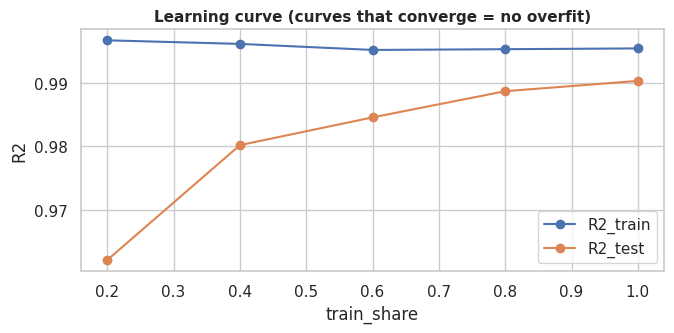

In [37]:
# ---- 10.1a  Fit diagnostics: train vs CV vs hold-out + learning curve (chronological, no shuffling)
gap_r2  = train_metrics["R2"] - final_metrics["R2"]
gap_mae = (final_metrics["MAE_units"] - train_metrics["MAE_units"]) / NAIVE_TEST_MAE
print(f"R2  train {train_metrics['R2']:.4f} | CV {bt.user_attrs['cv_r2']:.4f} | hold-out {final_metrics['R2']:.4f}  (train-test gap {gap_r2:+.4f})")
print(f"MAE gap as share of naive MAE: {gap_mae:+.3%}  (overfit flag > {OVERFIT_GAP_FLAG:.0%})")
cv_gap_r2 = train_metrics["R2"] - bt.user_attrs["cv_r2"]      # train vs CV (same kind of data); hold-out R2 also moves with that period's demand variance
print(f"train - CV R2 gap: {cv_gap_r2:+.4f}")
if cv_gap_r2 > 0.05 or gap_mae > OVERFIT_GAP_FLAG:   verdict = "OVERFITTING"
elif train_metrics["R2"] < 0.6 and gap_mae <= 0:  verdict = "NO OVERFITTING (low R2 = limited signal / simple model; see learning curve)"
else:                                             verdict = "GOOD FIT (no over/underfitting)"
print("Verdict:", verdict)

# learning curve: train on growing share of the EARLIEST dates, score on the fixed hold-out
dates = np.sort(train.Date.unique()); rows = []
for frac in [0.2, 0.4, 0.6, 0.8, 1.0]:
    cutd = dates[int(len(dates) * frac) - 1]
    sub = train[train.Date <= cutd]
    m = make_estimator(BEST_NAME, studies[BEST_NAME].best_params).fit(sub[FEATURES], sub[TARGET])
    rows.append(dict(train_share=frac, rows=len(sub),
                     R2_train=r2_score(sub[TARGET], m.predict(sub[FEATURES])),
                     R2_test=r2_score(y_test, m.predict(X_test))))
lc = pd.DataFrame(rows); display(lc)
ax = lc.plot(x="train_share", y=["R2_train", "R2_test"], marker="o", figsize=(7, 3.5), title="Learning curve (curves that converge = no overfit)")
ax.set_ylabel("R2"); plt.tight_layout(); plt.show()

In [38]:
# ---- 10.1b  Stronger-regularised XGBoost vs the tuned one (chronological CV on TRAINING data only)
base_p = dict(studies[BEST_NAME].best_params)
reg_grid = {
    "tuned (current)":        {},
    "shallower (depth 5)":    dict(max_depth=5),
    "more regularised":       dict(max_depth=5, min_child_weight=60, reg_lambda=10, reg_alpha=3, subsample=0.6, colsample_bytree=0.7),
    "strong regularisation":  dict(max_depth=4, min_child_weight=120, reg_lambda=30, reg_alpha=5, subsample=0.5, colsample_bytree=0.6, learning_rate=0.03),
}
out = []
for label, over in reg_grid.items():
    p = {**base_p, **over}
    est = make_estimator("XGBoost", p)
    cvr2, cvmae, trr2 = [], [], []
    for tr_idx, va_idx in cv:
        m = clone(est).fit(X_tune.iloc[tr_idx], y_tune.iloc[tr_idx])
        pv = m.predict(X_tune.iloc[va_idx]); cvr2.append(r2_score(y_tune.iloc[va_idx], pv)); cvmae.append(mean_absolute_error(y_tune.iloc[va_idx], pv))
        trr2.append(r2_score(y_tune.iloc[tr_idx], m.predict(X_tune.iloc[tr_idx])))
    out.append(dict(config=label, train_R2=np.mean(trr2), CV_R2=np.mean(cvr2), R2_gap=np.mean(trr2) - np.mean(cvr2), CV_MAE=np.mean(cvmae)))
reg_tbl = pd.DataFrame(out).set_index("config"); display(reg_tbl)
print("Lower R2 here only means a simpler model; pick the one with the best CV_MAE, not the lowest R2.")

,train_R2,CV_R2,R2_gap,CV_MAE
config,,,,
tuned (current),0.9874,0.9739,0.0135,4.7332
shallower (depth 5),0.9619,0.9437,0.0182,6.8692
more regularised,0.9393,0.9208,0.0185,7.7384
strong regularisation,0.6171,0.5807,0.0364,22.6880


Lower R2 here only means a simpler model; pick the one with the best CV_MAE, not the lowest R2.


## 1️⃣1️⃣ Visualisation

### 11.1 Chronological CV model comparison

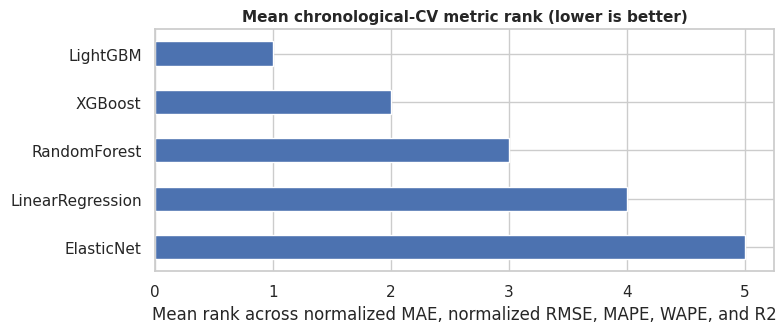

Selected multi-metric model: LightGBM | refined CV R2: 0.9836


In [39]:
rank_plot = selection.sort_values("mean_metric_rank", ascending=True)
ax = rank_plot["mean_metric_rank"].sort_values(ascending=False).plot(kind="barh", figsize=(8, 3.5), color="#4C72B0")
ax.set_title("Mean chronological-CV metric rank (lower is better)")
ax.set_xlabel("Mean rank across normalized MAE, normalized RMSE, MAPE, WAPE, and R2")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
print(f"Selected multi-metric model: {BEST_NAME} | refined CV R2: {winner_trial.user_attrs['cv_r2']:.4f}")

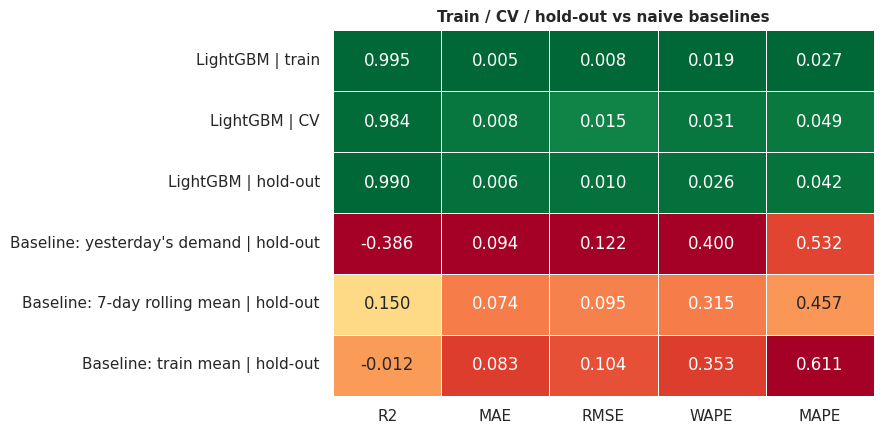

In [40]:
ft = final_tbl[["R2", "MAE", "RMSE", "WAPE", "MAPE"]].astype(float)
ft.index = [f"{m} | {s}" for m, s in ft.index]

sc = ft.copy()
for c in sc.columns:
    rng = ft[c].max() - ft[c].min()
    z = (ft[c] - ft[c].min()) / (rng if rng > 0 else 1)
    sc[c] = z if c == "R2" else 1 - z

plt.figure(figsize=(9, 4.5))
sns.heatmap(sc, annot=ft, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1,
            cbar=False, linewidths=.5, linecolor="white")
plt.title("Train / CV / hold-out vs naive baselines"); plt.tight_layout(); plt.show()

split,CV,hold-out,train
model,,,
ElasticNet,0.2627,0.2761,0.3046
LightGBM,0.9836,0.9903,0.9954
LinearRegression,0.2627,0.2761,0.3046
RandomForest,0.9608,0.9790,0.9964
XGBoost,0.9829,0.9883,0.9936


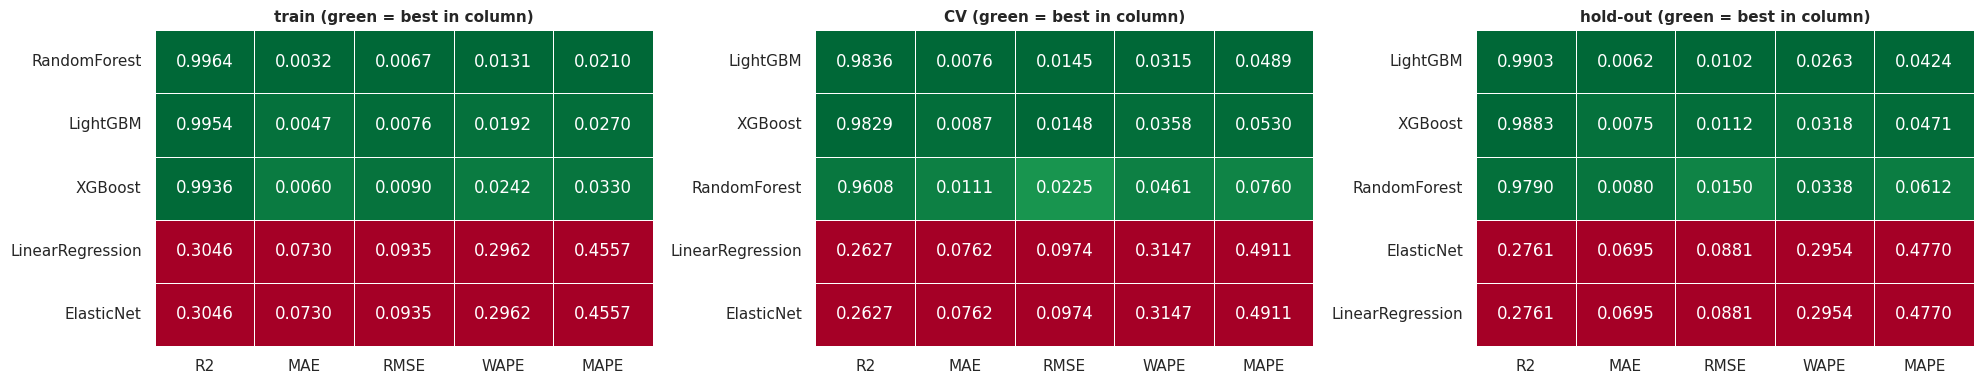

In [41]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt

rows = []
for name in MODEL_NAMES:
    m = make_estimator(name, studies[name].best_params).fit(X_train, y_train)
    for split, X_, y_ in [("train", X_train, y_train), ("hold-out", X_test, y_test)]:
        r = metrics(y_, m.predict(X_))
        rows.append(dict(model=name, split=split, R2=r["R2"], MAE=r["MAE"], RMSE=r["RMSE"],
                         WAPE=r["WAPE"], MAPE=r["MAPE"]))
    b = studies[name].best_trial.user_attrs
    rows.append(dict(model=name, split="CV", R2=b["cv_r2"], MAE=b["cv_mae_01"], RMSE=b["cv_rmse_01"],
                     WAPE=b["cv_wape"], MAPE=b["cv_mape"]))

all_tbl = pd.DataFrame(rows)
display(all_tbl.pivot(index="model", columns="split", values="R2").round(4))   # R2: train / CV / hold-out

def heat(split):
    d = all_tbl[all_tbl.split == split].set_index("model")[["R2", "MAE", "RMSE", "WAPE", "MAPE"]].astype(float)
    d = d.sort_values("R2", ascending=False)
    sc = d.copy()
    for c in d.columns:
        rng = d[c].max() - d[c].min()
        z = (d[c] - d[c].min()) / (rng if rng > 0 else 1)
        sc[c] = z if c == "R2" else 1 - z
    return d, sc

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, split in zip(axes, ["train", "CV", "hold-out"]):
    d, sc = heat(split)
    sns.heatmap(sc, annot=d, fmt=".4f", cmap="RdYlGn", vmin=0, vmax=1, cbar=False,
                linewidths=.5, linecolor="white", ax=ax)
    ax.set_title(f"{split} (green = best in column)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 11.2 Prediction quality and residual diagnostics

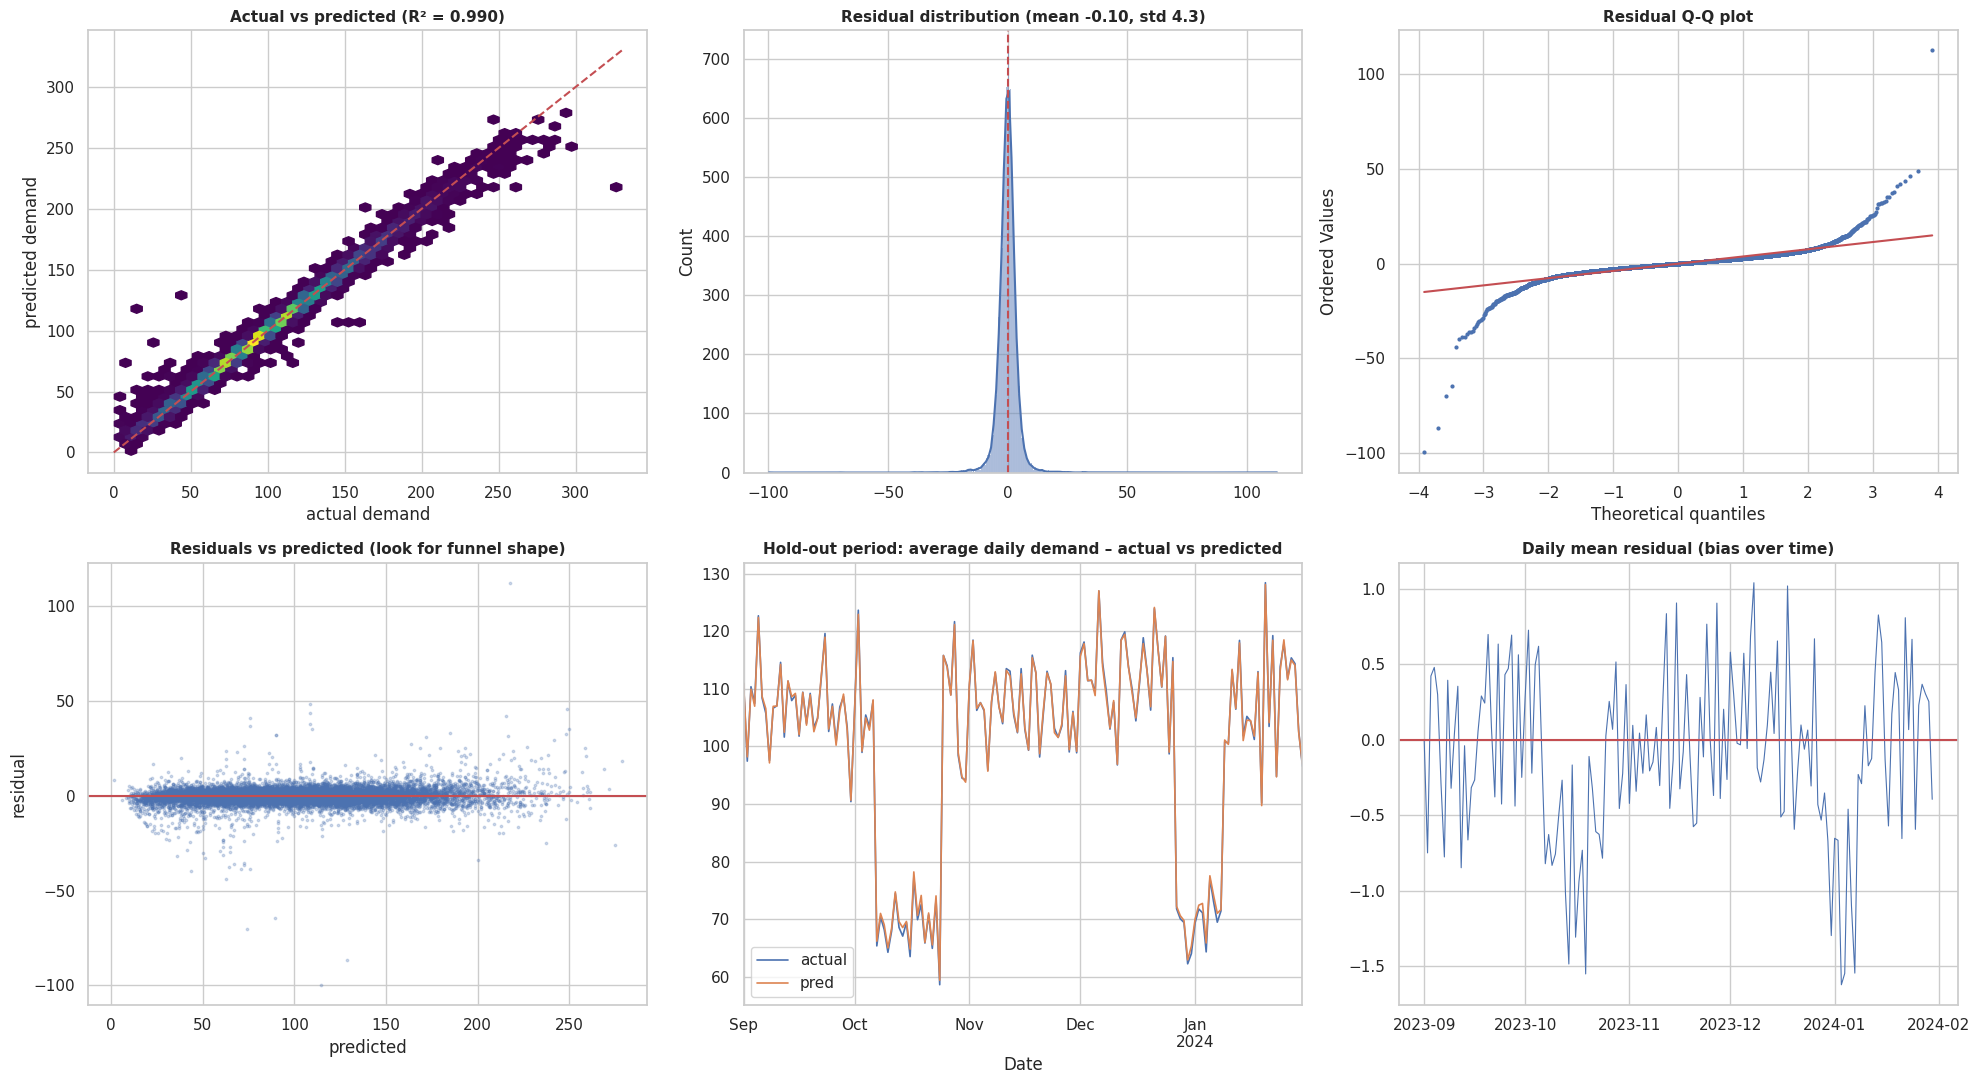

Durbin-Watson of daily residuals: 1.362


In [42]:
pred = test_pred; resid = y_test.values - pred
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes[0, 0].hexbin(y_test, pred, gridsize=45, cmap="viridis", mincnt=1); lim = [0, max(y_test.max(), pred.max())]; axes[0, 0].plot(lim, lim, "r--")
axes[0, 0].set_title(f"Actual vs predicted (R² = {final_metrics['R2']:.3f})"); axes[0, 0].set_xlabel("actual demand"); axes[0, 0].set_ylabel("predicted demand")
sns.histplot(resid, kde=True, ax=axes[0, 1], color="#4C72B0"); axes[0, 1].axvline(0, c="r", ls="--"); axes[0, 1].set_title(f"Residual distribution (mean {resid.mean():.2f}, std {resid.std():.1f})")
stats.probplot(resid, dist="norm", plot=axes[0, 2]); axes[0, 2].set_title("Residual Q-Q plot"); axes[0, 2].get_lines()[0].set_markersize(2)
axes[1, 0].scatter(pred, resid, s=3, alpha=.25); axes[1, 0].axhline(0, c="r"); axes[1, 0].set_title("Residuals vs predicted (look for funnel shape)"); axes[1, 0].set_xlabel("predicted"); axes[1, 0].set_ylabel("residual")
d_ts = pd.DataFrame({"Date": test.Date.values, "actual": y_test.values, "pred": pred}).groupby("Date").mean()
d_ts.plot(ax=axes[1, 1], lw=1.2); axes[1, 1].set_title("Hold-out period: average daily demand – actual vs predicted")
axes[1, 2].plot(d_ts.index, d_ts.actual - d_ts.pred, lw=.8); axes[1, 2].axhline(0, c="r"); axes[1, 2].set_title("Daily mean residual (bias over time)")
plt.tight_layout(); plt.show()
print("Durbin-Watson of daily residuals:", round(durbin_watson(d_ts.actual - d_ts.pred), 3))

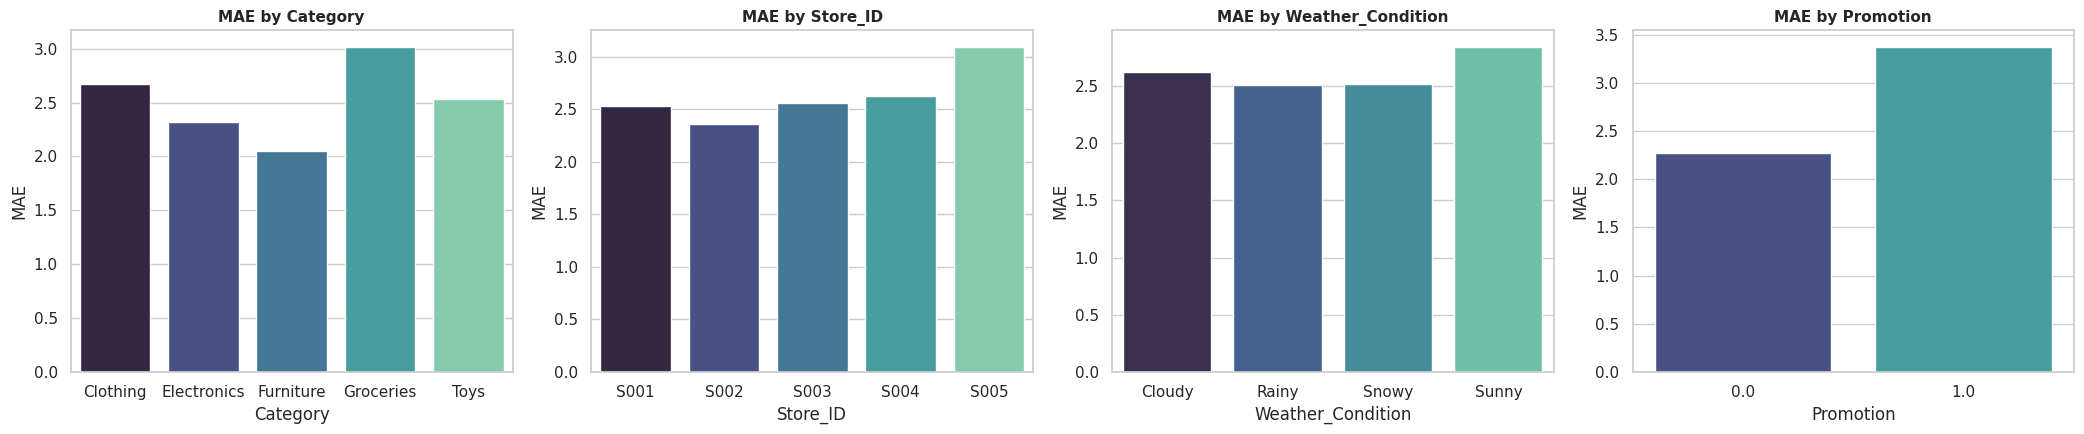

In [43]:
# error by business segment
seg = test.assign(pred=pred, abs_err=np.abs(resid), ape=100*np.abs(resid)/test[TARGET])
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, c in zip(axes, ["Category", "Store_ID", "Weather_Condition", "Promotion"]):
    s = seg.groupby(c, observed=True).agg(MAE=("abs_err", "mean")).reset_index(); sns.barplot(data=s, x=c, y="MAE", ax=ax, palette="mako"); ax.set_title(f"MAE by {c}")
plt.tight_layout(); plt.show()

### 11.3 What drives demand? (feature importance)

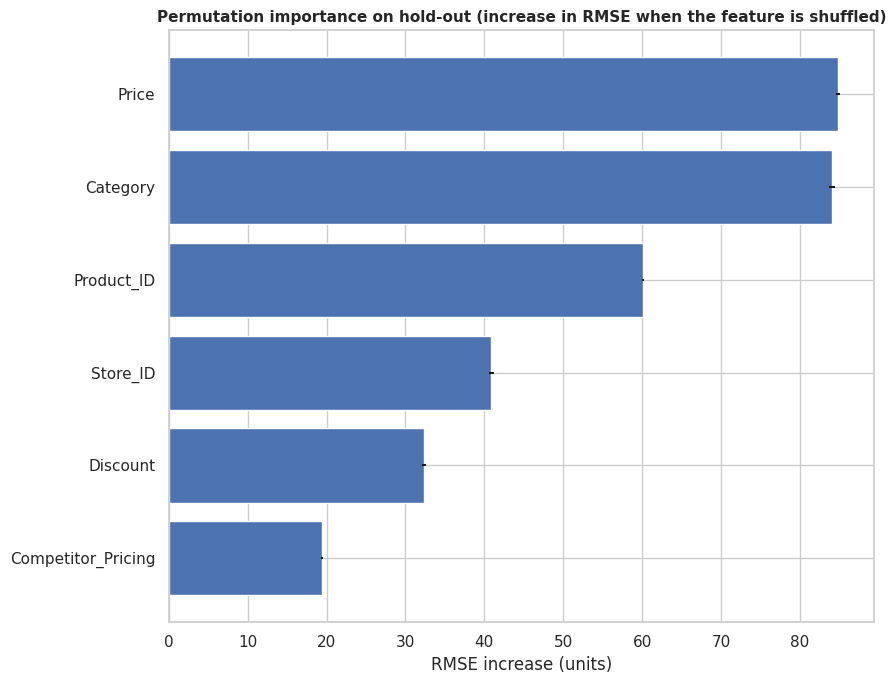

In [44]:
from sklearn.inspection import permutation_importance
samp = test.sample(min(6000, len(test)), random_state=RANDOM_STATE)
pi = permutation_importance(best_model, samp[FEATURES], samp[TARGET], n_repeats=5, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=1)
pi_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance")
plt.figure(figsize=(9, 7)); plt.barh(pi_df.feature, pi_df.importance, xerr=pi_df["std"], color="#4C72B0")
plt.title("Permutation importance on hold-out (increase in RMSE when the feature is shuffled)"); plt.xlabel("RMSE increase (units)"); plt.tight_layout(); plt.show()

## 1️⃣2️⃣ From demand model to **Adaptive Pricing Engine**
### 12.1 Can this data tell us how demand reacts to *our* price? (important sanity check)
Before letting an optimiser play with prices we must check whether the model’s "what if the price were higher" answers are **causal**. We compare demand with (a) our price relative to its own usual level and (b) our price relative to the competitor.

corr(own price index, demand index)       = +0.798
corr(price / competitor price, demand idx) = +0.001


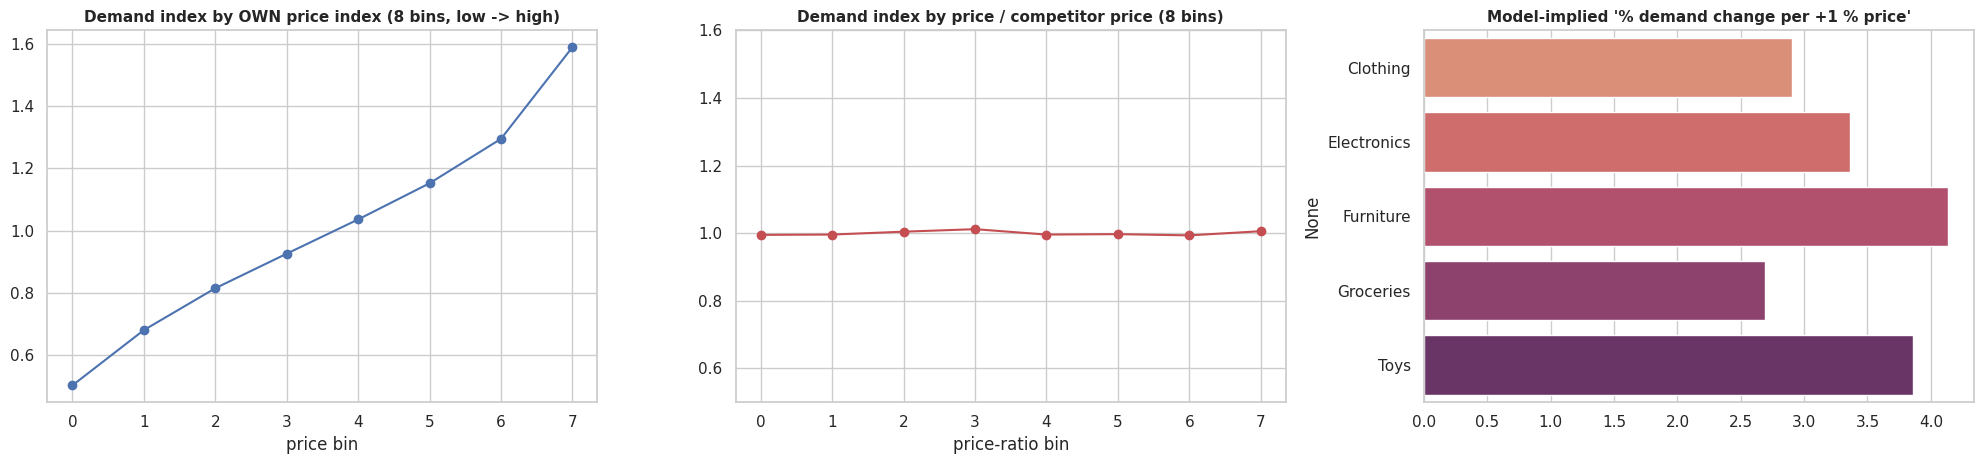

In [45]:
eng_sample = test.sample(n=min(4000, len(test)), random_state=RANDOM_STATE)

dd = df.copy(); gg = dd.groupby(["Store_ID", "Product_ID"])
dd["demand_idx"] = dd.Demand / gg.Demand.transform("mean")          # 1.0 = this series' normal demand
dd["price_idx"]  = dd.Price  / gg.Price.transform("mean")           # 1.0 = this series' normal price
dd["price_bin"]  = pd.qcut(dd.price_idx, 8); dd["ratio_bin"] = pd.qcut(dd.Price_Ratio, 8)
print(f"corr(own price index, demand index)       = {dd.price_idx.corr(dd.demand_idx):+.3f}")
print(f"corr(price / competitor price, demand idx) = {dd.Price_Ratio.corr(dd.demand_idx):+.3f}")

# what the fitted model implies if we nudge the price by +1 %
def price_features(frame, new_price):
    f = frame.copy(); f["Price"] = new_price
    f["Price_Ratio"] = f.Price / f.Competitor_Pricing; f["Price_Gap"] = f.Price - f.Competitor_Pricing
    f["Effective_Price"] = f.Price * (1 - f.Discount / 100); f["Eff_Ratio"] = f.Effective_Price / f.Competitor_Pricing
    f["Price_Change_1d"] = (f.Price - f.Price_Lag1) / f.Price_Lag1
    f["Price_Idx_Exp"] = f.Price / f.Price_ExpMean; f["Price_Idx_7"] = f.Price / f.Price_Roll7; f["Price_Idx_28"] = f.Price / f.Price_Roll28   # v3 features
    return f
d0 = best_model.predict(eng_sample[FEATURES]); d1 = best_model.predict(price_features(eng_sample, eng_sample.Price.values * 1.01)[FEATURES])
elas_model = pd.Series((d1 / d0 - 1) * 100, index=eng_sample.Category.values).groupby(level=0).mean()

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
dd.groupby("price_bin", observed=True).demand_idx.mean().reset_index(drop=True).plot(marker="o", ax=axes[0]); axes[0].set_title("Demand index by OWN price index (8 bins, low -> high)"); axes[0].set_xlabel("price bin")
dd.groupby("ratio_bin", observed=True).demand_idx.mean().reset_index(drop=True).plot(marker="o", color="#C44E52", ax=axes[1]); axes[1].set_ylim(.5, 1.6)
axes[1].set_title("Demand index by price / competitor price (8 bins)"); axes[1].set_xlabel("price-ratio bin")
sns.barplot(x=elas_model.values, y=elas_model.index, ax=axes[2], palette="flare"); axes[2].set_title("Model-implied '% demand change per +1 % price'")
plt.tight_layout(); plt.show()

In [46]:
import numpy as np
import pandas as pd

def recommend_prices_constrained(
    frame,
    model,
    unit_cost,
    elasticity_by_category,
    target_margin=0.30,
    max_competitor_premium=0.10,
    price_multipliers=None,
    elasticity_scale=1.0,
    max_change=0.15,
    min_profit_gain=0.01,
):
    """Return price scenarios subject to explicit business constraints.

    Required frame columns:
      Price, Competitor_Pricing, Discount, Inventory_Level, Category, plus FEATURES.
    unit_cost:
      scalar or Series aligned to frame rows; must be actual per-unit cost.
    elasticity_scale:
      multiplies every elasticity (use for sensitivity analysis).
    max_change:
      largest allowed relative price move per update (0.15 = +/-15 %).
    min_profit_gain:
      the price only moves if scenario profit beats the current price by more than this relative amount.
    elasticity_by_category:
      category -> price elasticity. Treat values as assumptions unless validated experimentally.
    """
    required = {"Price", "Competitor_Pricing", "Discount", "Inventory_Level", "Category"}
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"Missing required pricing columns: {missing}")
    if frame.empty:
        return pd.DataFrame()

    current_price = pd.to_numeric(frame["Price"], errors="coerce").to_numpy(dtype=float)
    competitor = pd.to_numeric(frame["Competitor_Pricing"], errors="coerce").to_numpy(dtype=float)
    discount = pd.to_numeric(frame["Discount"], errors="coerce").fillna(0).to_numpy(dtype=float) / 100.0
    inventory = pd.to_numeric(frame["Inventory_Level"], errors="coerce").fillna(0).clip(lower=0).to_numpy(dtype=float)

    if np.any(~np.isfinite(current_price)) or np.any(current_price <= 0):
        raise ValueError("Price must contain finite positive values.")
    if np.any(~np.isfinite(competitor)) or np.any(competitor <= 0):
        raise ValueError("Competitor_Pricing must contain finite positive values.")
    if np.any((discount < 0) | (discount >= 1)):
        raise ValueError("Discount must be between 0% and less than 100%.")
    if not 0 <= target_margin < 1:
        raise ValueError("target_margin must be in [0, 1).")
    if max_competitor_premium < 0:
        raise ValueError("max_competitor_premium cannot be negative.")
    if max_change < 0 or min_profit_gain < 0:
        raise ValueError("max_change and min_profit_gain cannot be negative.")

    if np.isscalar(unit_cost):
        costs = np.full(len(frame), float(unit_cost), dtype=float)
    else:
        costs = pd.Series(unit_cost, index=frame.index).to_numpy(dtype=float)
    if len(costs) != len(frame) or np.any(~np.isfinite(costs)) or np.any(costs < 0):
        raise ValueError("unit_cost must be finite, non-negative, and aligned with frame rows.")

    multipliers = np.asarray(
        price_multipliers if price_multipliers is not None
        else np.round(np.arange(0.85, 1.1501, 0.025), 3),
        dtype=float
    )
    if multipliers.ndim != 1 or len(multipliers) == 0 or np.any(multipliers <= 0):
        raise ValueError("price_multipliers must be a non-empty 1D array of positive values.")
    multipliers = np.unique(np.append(multipliers[np.abs(multipliers - 1.0) <= max_change + 1e-9], 1.0))   # enforce the move limit, always allow "keep"
    keep_idx = int(np.argmin(np.abs(multipliers - 1.0)))

    base_demand = np.maximum(0.0, np.asarray(model.predict(frame[FEATURES]), dtype=float))
    elasticity = frame["Category"].map(elasticity_by_category)
    if elasticity.isna().any():
        unknown = sorted(frame.loc[elasticity.isna(), "Category"].astype(str).unique())
        raise ValueError(f"Missing elasticity assumption for categories: {unknown}")
    elasticity = elasticity.to_numpy(dtype=float) * elasticity_scale

    candidate_prices = current_price[:, None] * multipliers[None, :]
    net_prices = candidate_prices * (1.0 - discount[:, None])
    expected_demand = base_demand[:, None] * np.power(multipliers[None, :], elasticity[:, None])
    expected_demand = np.maximum(0.0, expected_demand)
    fulfilled_units = np.minimum(expected_demand, inventory[:, None])
    profit = (net_prices - costs[:, None]) * fulfilled_units

    margin = np.divide(
        net_prices - costs[:, None], net_prices,
        out=np.full_like(net_prices, -np.inf), where=net_prices > 0
    )
    feasible = (
        (margin >= target_margin)
        & (candidate_prices <= competitor[:, None] * (1 + max_competitor_premium))
    )

    chosen_idx = np.zeros(len(frame), dtype=int)
    statuses = []
    for i in range(len(frame)):
        valid = np.flatnonzero(feasible[i])
        if len(valid):
            best = valid[np.argmax(profit[i, valid])]
            # hysteresis: stay at the current price when it is feasible and the gain is too small to be worth a price change
            if feasible[i, keep_idx] and best != keep_idx and \
               profit[i, best] - profit[i, keep_idx] <= min_profit_gain * abs(profit[i, keep_idx]):
                chosen_idx[i] = keep_idx
                statuses.append("KEEP_CURRENT_SMALL_GAIN")
            else:
                chosen_idx[i] = best
                statuses.append("OK")
        else:
            # Keep current price as a fallback, but clearly mark it as not constraint-feasible.
            chosen_idx[i] = keep_idx
            statuses.append("NO_FEASIBLE_PRICE")

    row_idx = np.arange(len(frame))
    chosen_price = candidate_prices[row_idx, chosen_idx]
    chosen_net = net_prices[row_idx, chosen_idx]
    chosen_demand = expected_demand[row_idx, chosen_idx]
    chosen_units = fulfilled_units[row_idx, chosen_idx]
    chosen_profit = profit[row_idx, chosen_idx]
    chosen_margin = margin[row_idx, chosen_idx]

    # Baseline is evaluated at current price using the same cost, discount, inventory logic.
    current_net = current_price * (1 - discount)
    current_units = np.minimum(base_demand, inventory)
    current_profit = (current_net - costs) * current_units
    current_margin = np.divide(current_net - costs, current_net,
                               out=np.full_like(current_net, -np.inf), where=current_net > 0)

    result = pd.DataFrame({
        "Category": frame["Category"].astype(str).to_numpy(),
        "Current_Price": current_price,
        "Competitor_Price": competitor,
        "Unit_Cost": costs,
        "Recommended_Price": chosen_price,
        "Price_Change_pct": 100 * (chosen_price / current_price - 1),
        "Baseline_Demand_Forecast": base_demand,
        "Expected_Demand_Scenario": chosen_demand,
        "Expected_Fulfilled_Units": chosen_units,
        "Current_Net_Margin": current_margin,
        "Recommended_Net_Margin": chosen_margin,
        "Estimated_Current_Profit": current_profit,
        "Scenario_Profit": chosen_profit,
        "Decision_Status": statuses,
        "Elasticity_Assumption": elasticity,
    }, index=frame.index)
    return result

,Category,Current_Price,Competitor_Price,Unit_Cost,Recommended_Price,Price_Change_pct,Baseline_Demand_Forecast,Expected_Demand_Scenario,Expected_Fulfilled_Units,Current_Net_Margin,Recommended_Net_Margin,Estimated_Current_Profit,Scenario_Profit,Decision_Status,Elasticity_Assumption
61165,Groceries,34.4000,41.3700,20.6400,39.5600,15.0000,112.9450,100.9971,100.9971,0.3333,0.4203,"1,165.5926","1,511.3203",OK,-0.8000
61691,Furniture,127.2500,118.1100,76.3500,127.2500,0.0000,57.0257,57.0257,57.0257,0.4000,0.4000,"2,902.6086","2,902.6086",OK,-1.2000
61297,Clothing,30.3900,28.3500,18.2340,31.1497,2.5000,205.2269,198.2535,166.0000,0.3684,0.3838,"1,765.6590","1,885.4716",OK,-1.4000
68409,Furniture,123.3700,115.2900,74.0220,126.4542,2.5000,79.7934,77.4637,77.4637,0.3333,0.3496,"2,953.2341","3,082.0360",OK,-1.2000
65934,Clothing,52.5000,59.2800,31.5000,60.3750,15.0000,47.4861,39.0471,39.0471,0.3333,0.4203,747.9057,891.7393,OK,-1.4000
61488,Groceries,81.2600,86.1900,48.7560,93.4490,15.0000,59.7617,53.4398,53.4398,0.4000,0.4783,"1,942.4942","2,388.3840",OK,-0.8000
65050,Electronics,141.8600,168.4900,85.1160,163.1390,15.0000,139.3188,108.3312,108.3312,0.4000,0.4783,"7,905.5060","8,452.3263",OK,-1.8000
59310,Furniture,148.4900,167.3600,89.0940,170.7635,15.0000,78.8068,66.6387,66.6387,0.3333,0.4203,"3,510.6080","4,304.4031",OK,-1.2000
66724,Electronics,112.6900,108.6800,67.6140,118.3245,5.0000,147.8108,135.3834,135.3834,0.4000,0.4286,"6,662.7199","6,865.3604",OK,-1.8000
66192,Groceries,60.3700,66.0800,36.2220,69.4255,15.0000,102.3918,91.5602,91.5602,0.2500,0.3478,"1,236.2783","1,768.7968",OK,-0.8000


Decision_Status
OK                         3454
NO_FEASIBLE_PRICE           530
KEEP_CURRENT_SMALL_GAIN      16
Rows where the price changes: 80.0%
ILLUSTRATIVE scenario profit change on the 3,470 rows with a feasible price: +14.11%


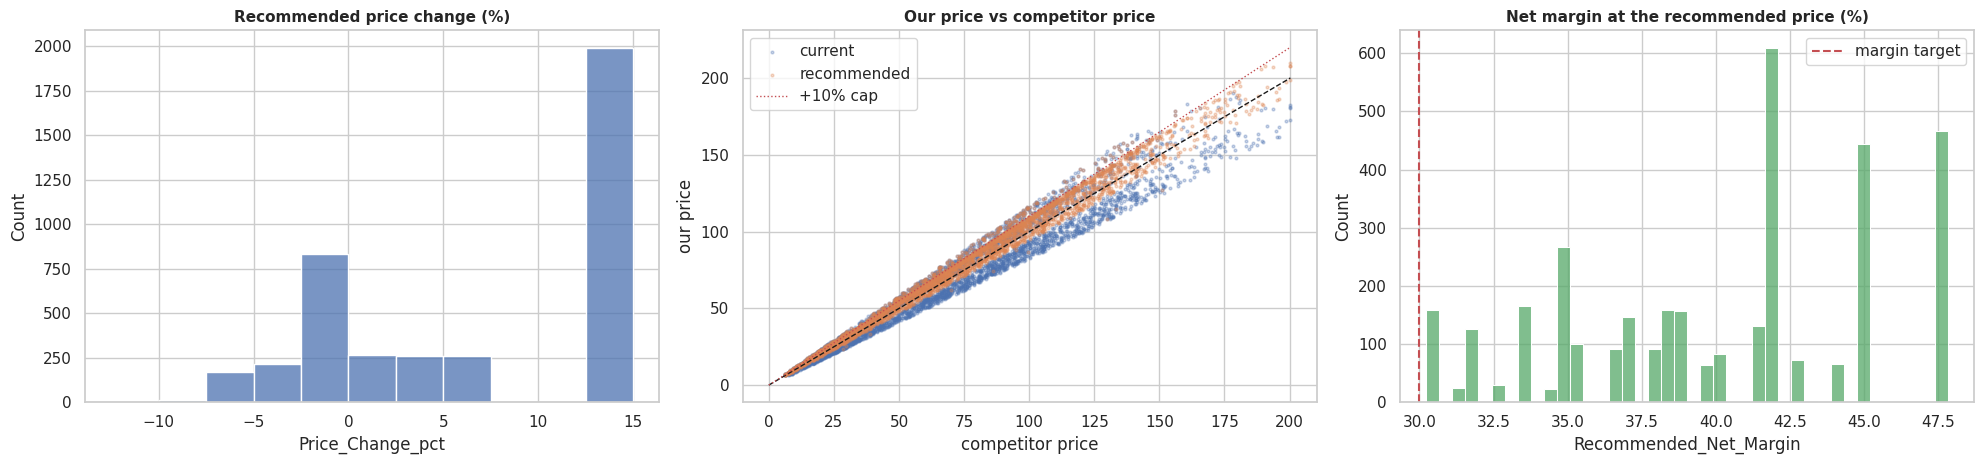

In [47]:
ILLUSTRATIVE_COST_SHARE = 0.60     # ⚠️ NOT a real cost - illustration only
ELASTICITY_ASSUMPTIONS = {"Groceries": -0.8, "Clothing": -1.4, "Toys": -1.5, "Electronics": -1.8, "Furniture": -1.2}   # placeholders
TARGET_MARGIN, MAX_PREMIUM = 0.30, 0.10

demo_cost = ILLUSTRATIVE_COST_SHARE * eng_sample["Price"]
reco = recommend_prices_constrained(eng_sample, best_model, unit_cost=demo_cost, elasticity_by_category=ELASTICITY_ASSUMPTIONS,
                                    target_margin=TARGET_MARGIN, max_competitor_premium=MAX_PREMIUM)
display(reco.head(10))
print(reco["Decision_Status"].value_counts(dropna=False).to_string())
print(f"Rows where the price changes: {(reco.Price_Change_pct.abs() > 1e-9).mean():.1%}")
ok = reco[reco.Decision_Status != "NO_FEASIBLE_PRICE"]
print(f"ILLUSTRATIVE scenario profit change on the {len(ok):,} rows with a feasible price: "
      f"{100 * (ok.Scenario_Profit.sum() / ok.Estimated_Current_Profit.sum() - 1):+.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
sns.histplot(reco.Price_Change_pct, bins=len(np.unique(reco.Price_Change_pct.round(3))), ax=axes[0], color="#4C72B0"); axes[0].set_title("Recommended price change (%)")
axes[1].scatter(reco.Competitor_Price, reco.Current_Price, s=4, alpha=.3, label="current"); axes[1].scatter(reco.Competitor_Price, reco.Recommended_Price, s=4, alpha=.3, label="recommended")
mx = reco.Competitor_Price.max(); axes[1].plot([0, mx], [0, mx], "k--", lw=1); axes[1].plot([0, mx], [0, mx * (1 + MAX_PREMIUM)], "r:", lw=1, label=f"+{MAX_PREMIUM:.0%} cap")
axes[1].set_title("Our price vs competitor price"); axes[1].legend(); axes[1].set_xlabel("competitor price"); axes[1].set_ylabel("our price")
sns.histplot(reco.loc[ok.index, "Recommended_Net_Margin"].clip(-0.5, 1) * 100, bins=40, ax=axes[2], color="#55A868"); axes[2].axvline(100 * TARGET_MARGIN, c="r", ls="--", label="margin target")
axes[2].set_title("Net margin at the recommended price (%)"); axes[2].legend()
plt.tight_layout(); plt.show()

,mean_price_change_pct,share_changed_pct,share_no_feasible_pct,profit_change_pct
elasticity_scale,,,,
0.5000,8.0069,79.9750,13.2500,19.8271
0.7500,8.0069,79.9750,13.2500,16.9312
1.0000,8.0069,79.9750,13.2500,14.1088
1.5000,6.9506,71.6500,13.2500,8.9624
2.0000,3.8906,67.3000,13.2500,6.3249
3.0000,0.4156,75.2500,13.2500,7.7215


Scenario profit change ranges from +6.32% to +19.83% across elasticity scales - the size (and possibly the sign) depends on assumptions the data cannot verify.


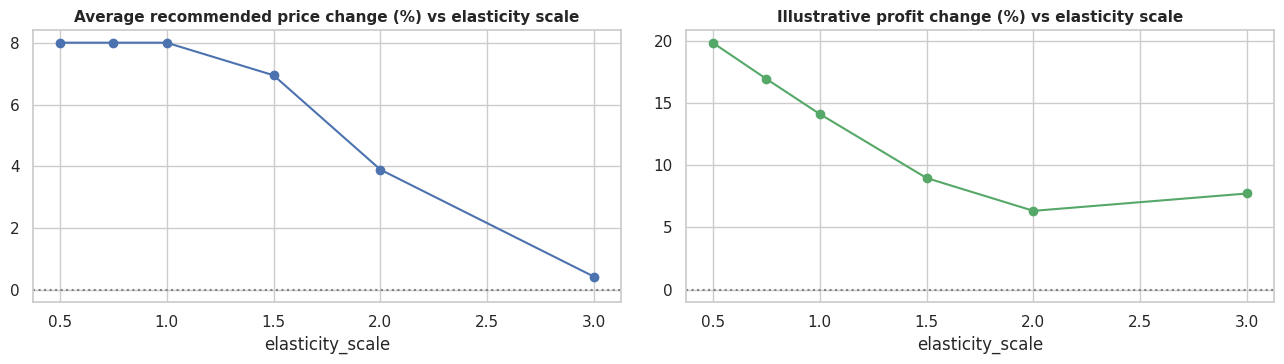

In [48]:
# Sensitivity: how much do the conclusions depend on the (assumed!) elasticity?  Report a range, not a point estimate.
rows = []
for sc in [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]:
    r_ = recommend_prices_constrained(eng_sample, best_model, unit_cost=demo_cost, elasticity_by_category=ELASTICITY_ASSUMPTIONS,
                                      target_margin=TARGET_MARGIN, max_competitor_premium=MAX_PREMIUM, elasticity_scale=sc)
    k_ = r_[r_.Decision_Status != "NO_FEASIBLE_PRICE"]
    rows.append(dict(elasticity_scale=sc, mean_price_change_pct=r_.Price_Change_pct.mean(), share_changed_pct=100 * (r_.Price_Change_pct.abs() > 1e-9).mean(),
                     share_no_feasible_pct=100 * (r_.Decision_Status == "NO_FEASIBLE_PRICE").mean(),
                     profit_change_pct=100 * (k_.Scenario_Profit.sum() / k_.Estimated_Current_Profit.sum() - 1)))
sens = pd.DataFrame(rows).set_index("elasticity_scale"); display(sens)
print(f"Scenario profit change ranges from {sens.profit_change_pct.min():+.2f}% to {sens.profit_change_pct.max():+.2f}% across elasticity scales - "
      "the size (and possibly the sign) depends on assumptions the data cannot verify.")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sens.mean_price_change_pct.plot(marker="o", ax=ax[0]); ax[0].axhline(0, c="grey", ls=":"); ax[0].set_title("Average recommended price change (%) vs elasticity scale")
sens.profit_change_pct.plot(marker="o", color="#55A868", ax=ax[1]); ax[1].axhline(0, c="grey", ls=":"); ax[1].set_title("Illustrative profit change (%) vs elasticity scale")
plt.tight_layout(); plt.show()

In [49]:
# ---- 12.4a  write the pipeline module next to the notebook and import it
from pathlib import Path
import importlib, sys

PIPELINE_SOURCE = r'''"""
pricing_pipeline_components.py
Reusable building blocks of the Adaptive Pricing Engine (v3).

    raw sales table  ->  PricingCleaner  ->  PricingFeatureBuilder  ->  HistoryAwareRegressor
                         (schema, types,     (past-only lag / rolling    (drops rows without history
                          missing, outliers)  / price-vs-own-history      when fitting, returns NaN for
                                              features)                   them when predicting)

Every step keeps ALL input rows in the SAME order, so `pipe.fit(raw, raw["Demand"])` and
`pipe.predict(raw)` line up row by row. Only information available at decision time is used:
every history feature is built with shift(1), so today's Demand is never needed (it may be blank).
"""
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.pipeline import Pipeline

TARGET = "Demand"
KEY = ["Date", "Store_ID", "Product_ID"]
SERIES = ["Store_ID", "Product_ID"]
PLACEHOLDERS = {"", "?", "na", "n/a", "nan", "null", "none", "-", "--", "unknown"}
POSITIVE_COLS = ["Price", "Competitor_Pricing"]
NONNEG_COLS = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Discount", "Demand"]
NUM_IMPUTE = ["Inventory_Level", "Price", "Competitor_Pricing", "Discount"]      # target is never imputed
COUNTS = ["Inventory_Level", "Units_Sold", "Units_Ordered", "Demand"]
BINARY = ["Promotion", "Epidemic"]
CAP_COLS = ["Inventory_Level", "Price", "Competitor_Pricing"]                     # Demand is never capped
CAT_COLS = ["Store_ID", "Product_ID", "Category", "Weather_Condition"]
REQUIRED_INPUT = ["Date", "Store_ID", "Product_ID", "Category", "Weather_Condition", "Inventory_Level",
                  "Price", "Competitor_Pricing", "Discount", "Promotion", "Epidemic"]
# Features that need history; a row is only forecastable when all of them exist.
HIST_REQUIRED = ["Demand_Lag7", "Demand_Roll7", "Price_Change_1d", "Comp_Change_1d",
                 "Demand_Lag14", "Demand_Roll14", "Demand_Roll28", "Demand_Std7", "Price_Roll28"]

def _is_text(s):
    return not (pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s))

class PricingCleaner(BaseEstimator, TransformerMixin):
    """Schema -> dtypes -> disguised / impossible values to NaN -> imputation -> per-Category outlier caps.
    Everything data-dependent (imputation statistics, outlier fences) is learned in fit() from the rows it is given."""

    def __init__(self, imputer="group_median", random_state=42):
        self.imputer = imputer
        self.random_state = random_state

    # ---- stateless part
    def _standardise(self, X):
        d = pd.DataFrame(X).copy()
        d.columns = d.columns.astype(str).str.strip().str.replace(r"\s+", "_", regex=True)
        missing = [c for c in REQUIRED_INPUT if c not in d.columns]
        if missing:
            raise ValueError(f"Input is missing required columns: {missing}")
        d["Date"] = pd.to_datetime(d["Date"], errors="coerce")
        for c in d.columns:
            if c != "Date" and _is_text(d[c]):
                txt = d[c].astype(str).str.strip().str.lower()
                d[c] = d[c].where(~(txt.isin(PLACEHOLDERS) | d[c].isna()), np.nan)
        for c in NUM_IMPUTE + BINARY + [TARGET, "Units_Sold", "Units_Ordered"]:
            if c in d.columns:
                d[c] = pd.to_numeric(d[c], errors="coerce")
        for c in POSITIVE_COLS:
            d.loc[d[c] <= 0, c] = np.nan
        for c in NONNEG_COLS:
            if c in d.columns:
                d.loc[d[c] < 0, c] = np.nan
        if d["Date"].isna().any() or d[["Store_ID", "Product_ID"]].isna().any().any():
            raise ValueError("Date, Store_ID and Product_ID identify the row and cannot be missing.")
        for c in ["Store_ID", "Product_ID"]:
            d[c] = d[c].astype(str)
        return d

    def _context(self, d):
        ctx = pd.get_dummies(d[["Category", "Weather_Condition"]].astype(object).fillna("Unknown").astype(str), dtype=float)
        return pd.concat([d[BINARY].fillna(0).astype(float), ctx], axis=1).reindex(columns=self.ctx_cols_, fill_value=0.0)

    # ---- learn
    def fit(self, X, y=None):
        d = self._standardise(X)
        self.num_median_ = d[NUM_IMPUTE].median()
        self.num_mean_ = d[NUM_IMPUTE].mean()
        self.group_median_ = d.groupby("Category")[NUM_IMPUTE].median()
        self.binary_mode_ = {c: (d[c].mode().iloc[0] if d[c].notna().any() else 0) for c in BINARY}
        self.cat_mode_ = {c: (d[c].mode().iloc[0] if d[c].notna().any() else "Unknown") for c in ["Category", "Weather_Condition"]}
        self.product_category_ = d.dropna(subset=["Category"]).groupby("Product_ID")["Category"].agg(lambda s: s.mode().iloc[0]).to_dict()
        # model-based imputers (knn / iterative) need a context matrix
        d = self._fill_categoricals(d)
        self.ctx_cols_ = list(pd.concat([d[BINARY].fillna(0).astype(float),
                                         pd.get_dummies(d[["Category", "Weather_Condition"]].astype(str), dtype=float)], axis=1).columns)
        self.model_imputer_ = None
        if self.imputer in ("knn", "iterative"):
            from sklearn.preprocessing import StandardScaler
            from sklearn.experimental import enable_iterative_imputer  # noqa: F401
            from sklearn.impute import KNNImputer, IterativeImputer
            from sklearn.linear_model import BayesianRidge
            Z = pd.concat([d[NUM_IMPUTE], self._context(d)], axis=1)
            sc = StandardScaler().fit(Z)
            imp = (KNNImputer(n_neighbors=5, weights="distance") if self.imputer == "knn"
                   else IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=self.random_state))
            imp.fit(sc.transform(Z))
            self.model_imputer_ = (sc, imp)
        d = self._impute(d)
        # outlier fences per Category, learned on the rows given to fit (the training period)
        skew = d[CAP_COLS].skew()
        self.k_by_col_ = {c: (3.0 if abs(skew[c]) > 1 else 1.5) for c in CAP_COLS}
        self.fences_ = {}
        for c in CAP_COLS:
            q = d.groupby("Category")[c].quantile([0.25, 0.75]).unstack()
            iqr = q[0.75] - q[0.25]
            lo = (q[0.25] - self.k_by_col_[c] * iqr).clip(lower=0)
            if c in POSITIVE_COLS:
                lo = lo.clip(lower=0.01)
            self.fences_[c] = (lo.to_dict(), (q[0.75] + self.k_by_col_[c] * iqr).to_dict())
        return self

    # ---- apply
    def _fill_categoricals(self, d):
        d = d.copy()
        cat = d["Category"].where(d["Category"].notna(), d["Product_ID"].map(self.product_category_))
        d["Category"] = cat.fillna(self.cat_mode_["Category"]).astype(str)
        d["Weather_Condition"] = d["Weather_Condition"].fillna(self.cat_mode_["Weather_Condition"]).astype(str)
        return d

    def _impute(self, d):
        d = d.copy()
        for c in BINARY:
            d[c] = d[c].fillna(self.binary_mode_[c])
        num = d[NUM_IMPUTE]
        if num.isna().any().any():
            if self.imputer == "mean":
                num = num.fillna(self.num_mean_)
            elif self.imputer == "median":
                num = num.fillna(self.num_median_)
            elif self.imputer in ("knn", "iterative") and self.model_imputer_ is not None:
                sc, imp = self.model_imputer_
                Z = pd.concat([num, self._context(d)], axis=1)
                num = pd.DataFrame(sc.inverse_transform(imp.transform(sc.transform(Z))), columns=Z.columns, index=d.index)[NUM_IMPUTE]
            else:                                                        # group_median (also the safe fallback)
                med = self.group_median_.reindex(d["Category"]).set_index(d.index)
                num = num.fillna(med).fillna(self.num_median_)
            for c in NUM_IMPUTE:
                d[c] = num[c]
        for c in COUNTS:
            if c in d.columns and c != TARGET:
                d[c] = d[c].round()
        d["Discount"] = d["Discount"].round()
        return d

    def transform(self, X):
        d = self._fill_categoricals(self._standardise(X))
        d = self._impute(d)
        for c in CAP_COLS:                                              # winsorise, never delete rows
            lo_map, hi_map = self.fences_[c]
            lo, hi = d["Category"].map(lo_map).astype(float), d["Category"].map(hi_map).astype(float)
            d[c] = d[c].clip(lower=lo, upper=hi)                         # unseen category -> NaN fence -> unchanged
            if c in COUNTS:
                d[c] = d[c].round()
        return d

class PricingFeatureBuilder(BaseEstimator, TransformerMixin):
    """Adds the engineered features. Row-preserving and order-preserving. Rows without enough history keep NaN."""

    def fit(self, X, y=None):
        return self

    def __sklearn_is_fitted__(self):          # stateless step: always "fitted" (lets pipe[:-1].transform(...) work)
        return True

    def transform(self, X):
        d = pd.DataFrame(X).copy()
        if not d.index.is_unique:
            raise ValueError("Input index must be unique.")
        original_index = d.index
        s = d.sort_values(SERIES + ["Date"], kind="mergesort")
        g = s.groupby(SERIES, observed=True, sort=False)
        gaps = g["Date"].diff().dropna().dt.days
        if len(gaps) and not (gaps == 1).all():
            warnings.warn(f"{int((gaps != 1).sum())} non-consecutive day gaps: lag features are not exact calendar lags there.")

        s["Price_Ratio"] = s.Price / s.Competitor_Pricing
        s["Price_Gap"] = s.Price - s.Competitor_Pricing
        s["Effective_Price"] = s.Price * (1 - s.Discount / 100)
        s["Eff_Ratio"] = s.Effective_Price / s.Competitor_Pricing

        has_target = TARGET in s.columns
        dem = g[TARGET] if has_target else None
        if not has_target:
            raise ValueError("History needs the Demand column (it may be blank only for the rows to be forecast).")
        s["Demand_Lag1"] = dem.shift(1)
        s["Demand_Lag7"] = dem.shift(7)
        s["Demand_Roll7"] = dem.transform(lambda x: x.shift(1).rolling(7).mean())
        s["Price_Lag1"] = g["Price"].shift(1)
        s["Price_Change_1d"] = (s.Price - s.Price_Lag1) / s.Price_Lag1
        s["Comp_Change_1d"] = g["Competitor_Pricing"].transform(lambda x: x.pct_change())
        # v3 additions: longer demand memory ...
        s["Demand_Lag14"] = dem.shift(14)
        s["Demand_Roll14"] = dem.transform(lambda x: x.shift(1).rolling(14).mean())
        s["Demand_Roll28"] = dem.transform(lambda x: x.shift(1).rolling(28).mean())
        s["Demand_Std7"] = dem.transform(lambda x: x.shift(1).rolling(7).std())
        s["Demand_ExpMean"] = dem.transform(lambda x: x.shift(1).expanding().mean())
        s["Demand_EWM"] = dem.transform(lambda x: x.shift(1).ewm(alpha=0.3).mean())
        # ... and today's price relative to this series' OWN past price level
        s["Price_ExpMean"] = g["Price"].transform(lambda x: x.shift(1).expanding().mean())
        s["Price_Roll7"] = g["Price"].transform(lambda x: x.shift(1).rolling(7).mean())
        s["Price_Roll28"] = g["Price"].transform(lambda x: x.shift(1).rolling(28).mean())
        s["Price_Idx_Exp"] = s.Price / s.Price_ExpMean
        s["Price_Idx_7"] = s.Price / s.Price_Roll7
        s["Price_Idx_28"] = s.Price / s.Price_Roll28

        s["Month"] = s.Date.dt.month
        s["DayOfWeek"] = s.Date.dt.dayofweek
        s["Is_Weekend"] = (s.DayOfWeek >= 5).astype(int)
        for c in CAT_COLS:
            s[c] = s[c].astype(str)
        return s.loc[original_index]

class HistoryAwareRegressor(BaseEstimator, RegressorMixin):
    """Wraps the tuned model. fit(): uses only rows whose history features exist and whose target is known.
    predict(): NaN for rows that lack history (cold start) instead of silently guessing."""

    def __init__(self, estimator, required=None):
        self.estimator = estimator
        self.required = required

    def _ok(self, X):
        req = list(self.required) if self.required is not None else HIST_REQUIRED
        return X[req].notna().all(axis=1).to_numpy()

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        ok = self._ok(X) & np.isfinite(y)
        self.n_fit_rows_, self.n_dropped_rows_ = int(ok.sum()), int((~ok).sum())
        self.estimator_ = clone(self.estimator).fit(X[ok], y[ok])
        return self

    def predict(self, X):
        out = np.full(len(X), np.nan)
        ok = self._ok(X)
        if ok.any():
            out[ok] = self.estimator_.predict(X[ok])
        return out

def make_pricing_pipeline(final_estimator, imputer="group_median", random_state=42):
    """raw table -> clean -> features -> model.  Fit with pipe.fit(raw_history, raw_history['Demand'])."""
    return Pipeline([("clean", PricingCleaner(imputer=imputer, random_state=random_state)),
                     ("features", PricingFeatureBuilder()),
                     ("model", HistoryAwareRegressor(final_estimator))])
'''

Path(PIPELINE_MODULE).write_text(PIPELINE_SOURCE, encoding="utf-8")
if os.getcwd() not in sys.path: sys.path.insert(0, os.getcwd())
import pricing_pipeline_components as ppc
importlib.reload(ppc)
print("wrote", PIPELINE_MODULE, "| components:", [n for n in ("PricingCleaner", "PricingFeatureBuilder", "HistoryAwareRegressor", "make_pricing_pipeline") if hasattr(ppc, n)])

wrote pricing_pipeline_components.py | components: ['PricingCleaner', 'PricingFeatureBuilder', 'HistoryAwareRegressor', 'make_pricing_pipeline']


In [50]:
# ---- 12.4b  fit the pipeline on RAW training rows only, predict from RAW data, and compare with the notebook model
raw_all   = df_raw.copy()                                   # the CSV exactly as delivered (original column names, untouched)
raw_dates = pd.to_datetime(raw_all["Date"])
raw_train = raw_all[raw_dates < CUT_DATE]

pipe = ppc.make_pricing_pipeline(make_estimator(BEST_NAME, studies[BEST_NAME].best_params), imputer=best_imputer, random_state=RANDOM_STATE)
pipe.fit(raw_train, raw_train["Demand"])
print("Pipeline steps:", [n for n, _ in pipe.steps], "| imputer:", best_imputer)
print(f"Fitted on {pipe[-1].n_fit_rows_:,} rows; {pipe[-1].n_dropped_rows_:,} rows skipped because they have no history yet")

pred_all = pipe.predict(raw_all)                            # raw table in -> one forecast per row (NaN = not enough history)
hold = (raw_dates >= CUT_DATE).to_numpy() & ~np.isnan(pred_all)
pipe_metrics = metrics(raw_all["Demand"].to_numpy(float)[hold], pred_all[hold])

cmp_tbl = pd.DataFrame({"notebook model (best_model)": {k: final_metrics[k] for k in HEADLINE},
                        "end-to-end pipeline":         {k: pipe_metrics[k] for k in HEADLINE}})
cmp_tbl["abs diff"] = (cmp_tbl.iloc[:, 0] - cmp_tbl.iloc[:, 1]).abs(); display(cmp_tbl)
print(f"Hold-out rows scored: pipeline {hold.sum():,} | notebook {len(test):,}")

# row-level parity (same keys, same rows)
feat_all = pipe[:-1].transform(raw_all); feat_all["pred"] = pred_all
chk = test[KEY].merge(feat_all[KEY + ["pred"]], on=KEY, how="left")
chk["notebook_pred"] = best_model.predict(X_test)
print(f"max |pipeline - notebook| prediction difference: {(chk.pred - chk.notebook_pred).abs().max():.6f} demand units")
assert abs(pipe_metrics["WAPE"] - final_metrics["WAPE"]) < 0.002 and hold.sum() == len(test), "Pipeline and notebook model disagree - investigate"
print("✅ pipeline reproduces the notebook model on the hold-out")

Pipeline steps: ['clean', 'features', 'model'] | imputer: iterative
Fitted on 58,000 rows; 2,800 rows skipped because they have no history yet


,notebook model (best_model),end-to-end pipeline,abs diff
MAE,0.0062,0.0062,0.0000
RMSE,0.0102,0.0102,0.0000
MAPE,0.0424,0.0424,0.0000
WAPE,0.0263,0.0263,0.0000


Hold-out rows scored: pipeline 15,200 | notebook 15,200
max |pipeline - notebook| prediction difference: 0.000000 demand units
✅ pipeline reproduces the notebook model on the hold-out


In [51]:
# ---- 12.4c  safety tests on the pipeline
# (1) LEAKAGE PROOF: blank out the last day's Demand and drop the leaky Units_* columns -> its forecasts must not change.
last_day = (raw_dates == raw_dates.max()).to_numpy()
blind = raw_all.copy(); blind.loc[last_day, "Demand"] = np.nan
blind = blind.drop(columns=[c for c in ["Units Sold", "Units Ordered"] if c in blind.columns])
p_blind = pipe.predict(blind)
print("(1) forecasts for the last day unchanged without today's Demand / Units_*:", bool(np.allclose(pred_all[last_day], p_blind[last_day], equal_nan=True)))

# (2) DIRTY INPUT: corrupt ~4 % of the hold-out rows (missing / impossible / placeholder values) and score again.
rng = np.random.default_rng(RANDOM_STATE); dirty = raw_all.copy()
holdout_idx = np.flatnonzero((raw_dates >= CUT_DATE).to_numpy())
if len(holdout_idx) < 600:
    raise ValueError(f"Dirty-input safety test needs at least 600 hold-out rows; found {len(holdout_idx)}.")
idx = rng.choice(holdout_idx, 600, replace=False)
dirty.loc[dirty.index[idx[:150]], "Price"] = np.nan
dirty.loc[dirty.index[idx[150:300]], "Competitor Pricing"] = -5
dirty.loc[dirty.index[idx[300:400]], "Category"] = "?"
dirty.loc[dirty.index[idx[400:500]], "Weather Condition"] = "unknown"
dirty.loc[dirty.index[idx[500:]], "Inventory Level"] = np.nan
p_dirty = pipe.predict(dirty); ok_ = (raw_dates >= CUT_DATE).to_numpy() & ~np.isnan(p_dirty)
m_dirty = metrics(raw_all["Demand"].to_numpy(float)[ok_], p_dirty[ok_])
print(f"(2) dirty input still scored: WAPE {pipe_metrics['WAPE']:.4f} (clean) -> {m_dirty['WAPE']:.4f} (4 % of rows corrupted)")

# (3) COLD START: a series with only 5 days of history must give NaN, not an invented number.
one = raw_all[(raw_all["Store ID"] == raw_all["Store ID"].iloc[0]) & (raw_all["Product ID"] == raw_all["Product ID"].iloc[0])].head(5)
print("(3) forecast with only 5 days of history:", pipe.predict(one), "(NaN = not enough history -> use a fallback rule)")

(1) forecasts for the last day unchanged without today's Demand / Units_*: True
(2) dirty input still scored: WAPE 0.0263 (clean) -> 0.0314 (4 % of rows corrupted)
(3) forecast with only 5 days of history: [nan nan nan nan nan] (NaN = not enough history -> use a fallback rule)


In [52]:
# ---- 12.4d  deploy: fit on ALL history, save, reload, and call the pricing engine through the pipeline
import joblib
deploy_pipe = ppc.make_pricing_pipeline(make_estimator(BEST_NAME, studies[BEST_NAME].best_params), imputer=best_imputer, random_state=RANDOM_STATE)
deploy_pipe.fit(raw_all, raw_all["Demand"])
joblib.dump(dict(pipeline=deploy_pipe, model_name=BEST_NAME, trained_through=str(raw_dates.max().date()), holdout_metrics=pipe_metrics,
                 y_range=Y_RANGE, required_input_columns=ppc.REQUIRED_INPUT, module_file=PIPELINE_MODULE), PIPELINE_FILE)
model_bundle = dict(model=deploy_pipe[-1].estimator_, model_name=BEST_NAME,
                    best_params=studies[BEST_NAME].best_params, features=FEATURES,
                    num_feats=NUM_FEATS, cat_feats=CAT_FEATS, target_transform=TARGET_TF_NAME,
                    trained_through=str(raw_dates.max().date()), holdout_metrics=pipe_metrics)
joblib.dump(model_bundle, "best_pricing_demand_model.joblib")
reloaded = joblib.load(PIPELINE_FILE)["pipeline"]
assert np.allclose(reloaded.predict(raw_all.tail(500)), deploy_pipe.predict(raw_all.tail(500)), equal_nan=True)
print(f"Saved {PIPELINE_FILE} and best_pricing_demand_model.joblib from the same production fit; reload check passed.")

def pipeline_recommend(pipe_, raw_history, decision_date, unit_cost, **engine_kw):
    """raw history (incl. the decision day's rows) -> constrained price recommendations. unit_cost: scalar, Series or callable(frame)."""
    feats = pipe_[:-1].transform(raw_history)
    today = feats[(feats["Date"] == pd.Timestamp(decision_date)) & feats[ppc.HIST_REQUIRED].notna().all(axis=1)]
    if today.empty: raise ValueError("No forecastable rows for this date (check history length).")
    cost = unit_cost(today) if callable(unit_cost) else unit_cost
    return recommend_prices_constrained(today, pipe_[-1].estimator_, unit_cost=cost, **engine_kw)

# ⚠️ ILLUSTRATIVE cost and PLACEHOLDER elasticities again (see 12.3) - this only demonstrates the wiring.
reco_pipe = pipeline_recommend(deploy_pipe, raw_all, raw_dates.max(), unit_cost=lambda t: ILLUSTRATIVE_COST_SHARE * t["Price"],
                               elasticity_by_category=ELASTICITY_ASSUMPTIONS, target_margin=TARGET_MARGIN, max_competitor_premium=MAX_PREMIUM)
display(reco_pipe.head(8)); print(reco_pipe["Decision_Status"].value_counts().to_string())

Saved pricing_pipeline.joblib and best_pricing_demand_model.joblib from the same production fit; reload check passed.


,Category,Current_Price,Competitor_Price,Unit_Cost,Recommended_Price,Price_Change_pct,Baseline_Demand_Forecast,Expected_Demand_Scenario,Expected_Fulfilled_Units,Current_Net_Margin,Recommended_Net_Margin,Estimated_Current_Profit,Scenario_Profit,Decision_Status,Elasticity_Assumption
75900,Electronics,71.5600,66.6600,42.9360,71.5600,0.0000,110.4702,110.4702,110.4702,0.3333,0.3333,"2,371.5737","2,371.5737",OK,-1.8000
75901,Clothing,70.5500,74.5000,42.3300,81.1325,15.0000,118.0827,97.0978,97.0978,0.4000,0.4783,"3,332.2946","3,767.6375",OK,-1.4000
75902,Clothing,59.4600,58.6700,35.6760,63.9195,7.5000,138.1601,124.8564,124.8564,0.3333,0.3798,"2,464.5004","2,728.3063",OK,-1.4000
75903,Electronics,93.8200,105.6000,56.2920,107.8930,15.0000,86.6293,67.3610,67.3610,0.3333,0.4203,"2,438.2680","2,749.1177",OK,-1.8000
75904,Groceries,45.8200,53.9400,27.4920,52.6930,15.0000,32.6243,29.1731,29.1731,0.4000,0.4783,597.9374,735.1909,OK,-0.8000
75905,Toys,37.1300,43.8400,22.2780,42.6995,15.0000,92.8675,75.3038,75.3038,0.3333,0.4203,"1,034.4514","1,216.2738",OK,-1.5000
75906,Groceries,24.5700,22.3500,14.7420,24.5700,0.0000,79.9551,79.9551,79.9551,0.4000,0.4000,785.7990,785.7990,OK,-0.8000
75907,Electronics,34.6800,39.4500,20.8080,39.8820,15.0000,51.4096,39.9749,39.9749,0.3333,0.4203,534.8651,603.0539,OK,-1.8000


Decision_Status
OK                   97
NO_FEASIBLE_PRICE     3


In [54]:
# ---- v4: final safety check - the ORIGINAL dataset must be exactly as it was at the start
assert file_sha256(ORIGINAL_PATH) == ORIGINAL_SHA256, "The original dataset changed during the run!"
print("✅ Original dataset untouched (sha256 unchanged). All work was done on:", WORKING_COPY_PATH)

✅ Original dataset untouched (sha256 unchanged). All work was done on: /kaggle/working/sales_data_working_copy.csv
